### Build turbines

In [1]:
# cell 1: imports and helpers
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RHO = 1.225

def take_integer_speeds(df, col, ws_out=np.arange(0, 26, 1.0)):
    ws = df["speed"].to_numpy(dtype=float)
    p = df[col].to_numpy(dtype=float)
    is_int = np.isclose(ws, np.round(ws))
    ws_i, p_i = ws[is_int], p[is_int]
    order = np.argsort(ws_i)
    ws_i, p_i = ws_i[order], p_i[order]
    _, first = np.unique(ws_i, return_index=True)
    ws_i, p_i = ws_i[first], p_i[first]
    mask = np.isin(np.round(ws_i).astype(int), ws_out.astype(int))
    ws_i = np.round(ws_i[mask]).astype(float)
    p_i = p_i[mask]
    idx = {int(w): i for i, w in enumerate(ws_i)}
    power = np.array([p_i[idx[int(w)]] if int(w) in idx else np.nan
                      for w in ws_out], dtype=float)
    return ws_out.copy(), power

def make_turbine_dict(name, ws, power_kw, ct_ws, ct_vals,
                      rotor_diameter, hub_height, tsr=8.0,
                      ref_tilt=5.0, ref_air_density=1.225,
                      cosine_loss_exponent_yaw=1.88,
                      cosine_loss_exponent_tilt=1.88):
    table = {
        "wind_speed": ws,
        "power": power_kw,
        "thrust_coefficient": np.interp(ws, ct_ws, ct_vals),
        "ref_tilt": ref_tilt,
        "ref_air_density": ref_air_density,
        "cosine_loss_exponent_yaw": cosine_loss_exponent_yaw,
        "cosine_loss_exponent_tilt": cosine_loss_exponent_tilt,
    }
    return {
        "turbine_type": name,
        "rotor_diameter": rotor_diameter,
        "hub_height": hub_height,
        "TSR": tsr,
        "power_thrust_table": table,
    }

In [2]:
# cell 2: load data and build all turbines from one spec table
pc = pd.read_csv("power_curves.csv")
pc.columns = [c.strip() for c in pc.columns]
ct = pd.read_csv("ct_values.csv", encoding="utf-8-sig")
ct.columns = [c.strip() for c in ct.columns]
ct_ws = ct["speed"].to_numpy()

# V150-4.2 power curve inline (kW), the others normalized in the CSV
v150_ws = np.arange(0, 26, 1.0)
v150_kw = np.array([0, 0, 0, 81, 285, 597, 1062, 1709, 2545, 3458, 4038, 4191,
                    4200, 4200, 4200, 4200, 4200, 4200, 4200, 4200, 4200, 3870,
                    2745, 1805, 1283, 0], dtype=float)

SPECS = {
    "vestas_v150_4.2": dict(ws=v150_ws, kw=v150_kw, ct_col="vestas v150-4.2mw",
                            rotor_diameter=150.0, hub_height=105.0),
    "vestas_v90_1.8":  dict(pc_col="Vestas.V90.1800", rated=1800.0,
                            ct_col="vestas v90-1.8mw",
                            rotor_diameter=90.0, hub_height=80.0),
    "vestas_v112_3.3": dict(pc_col="Vestas.V112.3300", rated=3300.0,
                            ct_col="vestas v112-3.3mw",
                            rotor_diameter=112.0, hub_height=84.0),
}

turbines = {}
for name, s in SPECS.items():
    if "kw" in s:
        ws, kw = s["ws"], s["kw"]
    else:
        ws, norm = take_integer_speeds(pc, s["pc_col"])
        kw = norm * s["rated"]
    turbines[name] = make_turbine_dict(
        name, ws, kw, ct_ws, ct[s["ct_col"]].to_numpy(),
        rotor_diameter=s["rotor_diameter"], hub_height=s["hub_height"],
    )

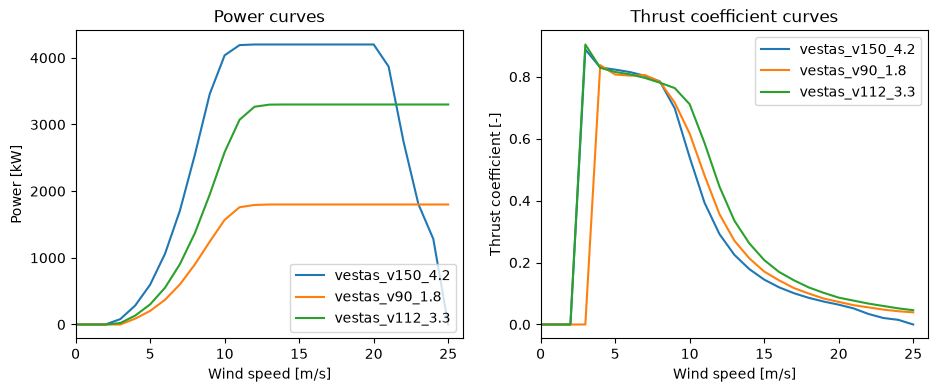

In [3]:
# cell 3: power and Ct curves
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name, t in turbines.items():
    tt = t["power_thrust_table"]
    axes[0].plot(tt["wind_speed"], tt["power"], label=name)
    axes[1].plot(tt["wind_speed"], tt["thrust_coefficient"], label=name)
axes[0].set(xlabel="Wind speed [m/s]", ylabel="Power [kW]",
            title="Power curves", xlim=(0, 26))
axes[1].set(xlabel="Wind speed [m/s]", ylabel="Thrust coefficient [-]",
            title="Thrust coefficient curves", xlim=(0, 26))
for ax in axes:
    ax.legend()
plt.show()

### Process MERRA2 data

In [4]:
# post-processing: MERRA-2 levels -> hub-height wind speeds (renewables.ninja log-law method)
import numpy as np
import pandas as pd

INPUT_FILE = "merra2_wind_52.30N_5.30E_2023.csv"
TURBINE_HUBS = {
    "vestas_v150_4.2": 105.0,
    "vestas_v90_1.8": 80.0,
    "vestas_v112_3.3": 84.0,
}
WEIGHTS = np.array([1.0, 1.0, 2.0])  # 50m weighted more, as in renewables.ninja

df = pd.read_csv(INPUT_FILE, parse_dates=["time"])
piv = df.pivot(index="time", columns="level", values="speed")[["2m", "10m", "50m"]]
speeds = piv.to_numpy()

# fit v = A*ln(h) + B per timestamp (vectorised weighted least squares)
x = np.log([2.0, 10.0, 50.0])
w = WEIGHTS / WEIGHTS.sum()
xw = (w * x).sum()
ym = (speeds * w).sum(axis=1, keepdims=True)
A = (w * (x - xw) * (speeds - ym)).sum(axis=1) / (w * (x - xw) ** 2).sum()
B = ym[:, 0] - A * xw

hub = pd.DataFrame(
    {f"{name}_hub_speed": np.where(A == 0, 0.0, A * np.log(h) + B)
     for name, h in TURBINE_HUBS.items()},
    index=piv.index,
)

out = df.merge(hub, on="time", how="left")
OUTPUT_FILE = INPUT_FILE.replace(".csv", "_turbine_hubs.csv")
out.to_csv(OUTPUT_FILE, index=False)

print(f"{len(out)} records, {out['time'].min()} to {out['time'].max()}, saved to {OUTPUT_FILE}")
print(out.groupby("level")["speed"].describe())
print(out.filter(like="_hub_speed").describe())

26280 records, 2023-01-01 00:00:00 to 2023-12-31 23:00:00, saved to merra2_wind_52.30N_5.30E_2023_turbine_hubs.csv
        count       mean       std       min       25%        50%        75%  \
level                                                                          
10m    8760.0  10.643510  3.707914  0.101232  8.202051  10.792356  13.061049   
2m     8760.0   8.876987  2.918615  0.097891  7.007156   9.038174  10.795936   
50m    8760.0  12.302113  4.494506  0.080266  9.248928  12.452061  15.276368   

             max  
level             
10m    28.307084  
2m     22.798736  
50m    32.665060  
       vestas_v150_4.2_hub_speed  vestas_v90_1.8_hub_speed  \
count               26280.000000              26280.000000   
mean                   13.099140                 12.810611   
std                     4.862781                  4.727404   
min                     0.077903                  0.079579   
25%                     9.784340                  9.591277   
50%              

### Test agreement between FLORIS and renewables.ninja on same input wind speed

In [5]:
# cell 1: FLORIS vs renewables.ninja per turbine, single-turbine inflow from ninja wind speed
from floris import FlorisModel

NINJA_FILES = {
    "vestas_v150_4.2": "ninja_wind_52.3000_5.3000_corrected_v150.csv",
    "vestas_v90_1.8": "ninja_wind_52.3000_5.3000_corrected_v90.csv",
    "vestas_v112_3.3": "ninja_wind_52.3000_5.3000_corrected_v112.csv",
}

results = {}
for name, path in NINJA_FILES.items():
    t = turbines[name]
    hub = t["hub_height"]

    ninja = pd.read_csv(path, skiprows=3, parse_dates=["time"])
    ws = ninja["wind_speed"].to_numpy(dtype=float)
    ninja_kw = ninja["electricity"].to_numpy()

    fmodel = FlorisModel("defaults")
    fmodel.set(
        layout_x=[0.0],
        layout_y=[0.0],
        turbine_type=[t],
        reference_wind_height=hub,
        wind_shear=0.0,
        wind_speeds=ws,
        wind_directions=np.full(len(ninja), 270.0),
        turbulence_intensities=np.full(len(ninja), 0.06),
    )
    fmodel.run()
    floris_kw = fmodel.get_turbine_powers()[:, 0] / 1000.0

    diff = floris_kw - ninja_kw
    mask = ws >= 3.0
    results[name] = {
        "time": ninja["time"],
        "ws": ws,
        "ninja_kw": ninja_kw,
        "floris_kw": floris_kw,
        "diff": diff,
    }

    print(f"\n=== {name} (hub {hub:.0f} m) ===")
    print(f"FLORIS mean [kW]:            {floris_kw.mean():.1f}")
    print(f"ninja mean [kW]:             {ninja_kw.mean():.1f}")
    print(f"mean diff above cut-in [kW]: {diff[mask].mean():.1f}")
    print(f"RMSE above cut-in [kW]:      {np.sqrt((diff[mask] ** 2).mean()):.1f}")
    print(f"AEP FLORIS [GWh]:            {floris_kw.sum() / 1e3:.2f}")
    print(f"AEP ninja [GWh]:             {ninja_kw.sum() / 1e3:.2f}")
    print(f"AEP ratio:                   {floris_kw.sum() / ninja_kw.sum():.3f}")


=== vestas_v150_4.2 (hub 105 m) ===
FLORIS mean [kW]:            2047.0
ninja mean [kW]:             2028.6
mean diff above cut-in [kW]: 19.2
RMSE above cut-in [kW]:      226.4
AEP FLORIS [GWh]:            17931.36
AEP ninja [GWh]:             17770.37
AEP ratio:                   1.009

=== vestas_v90_1.8 (hub 80 m) ===
FLORIS mean [kW]:            711.8
ninja mean [kW]:             722.7
mean diff above cut-in [kW]: -10.7
RMSE above cut-in [kW]:      81.6
AEP FLORIS [GWh]:            6235.73
AEP ninja [GWh]:             6330.68
AEP ratio:                   0.985

=== vestas_v112_3.3 (hub 84 m) ===
FLORIS mean [kW]:            1153.8
ninja mean [kW]:             1191.3
mean diff above cut-in [kW]: -37.6
RMSE above cut-in [kW]:      146.2
AEP FLORIS [GWh]:            10107.71
AEP ninja [GWh]:             10435.84
AEP ratio:                   0.969


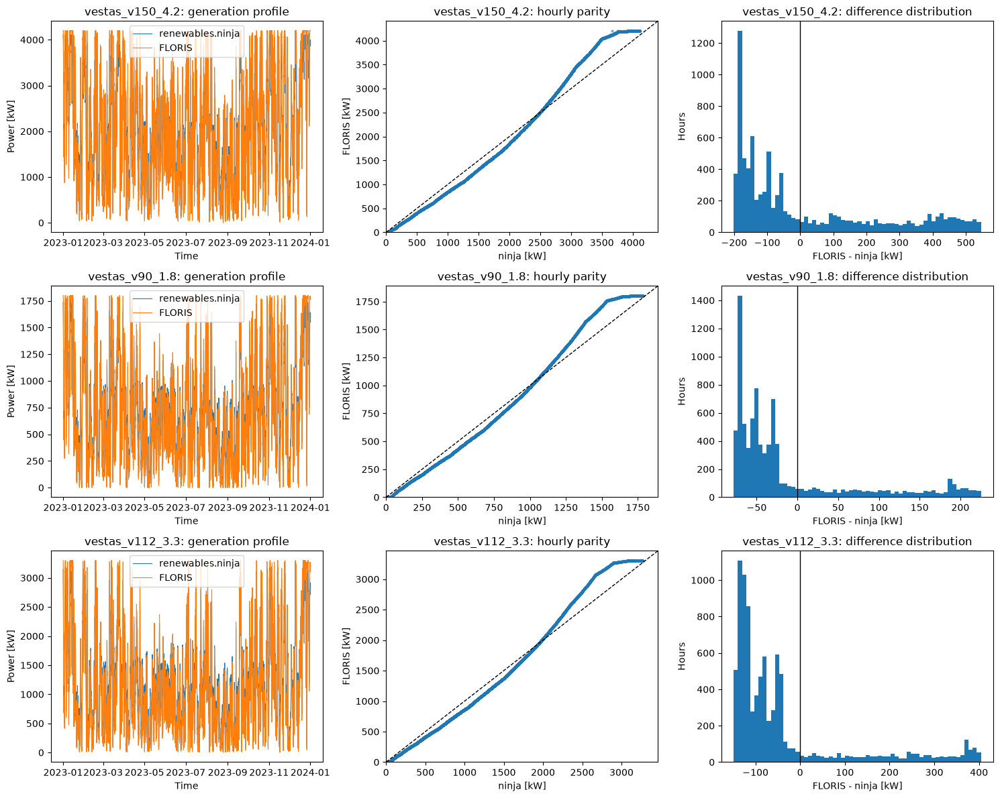

In [6]:
# cell 2: generation profile, parity, difference distribution per turbine
fig, axes = plt.subplots(len(results), 3, figsize=(15, 4 * len(results)))
axes = np.atleast_2d(axes)

for row, (name, r) in enumerate(results.items()):
    ninja_kw, floris_kw, diff = r["ninja_kw"], r["floris_kw"], r["diff"]

    ax = axes[row, 0]
    ax.plot(r["time"], ninja_kw, lw=0.8, label="renewables.ninja")
    ax.plot(r["time"], floris_kw, lw=0.8, label="FLORIS")
    ax.set_xlabel("Time")
    ax.set_ylabel("Power [kW]")
    ax.set_title(f"{name}: generation profile")
    ax.legend()

    ax = axes[row, 1]
    ax.scatter(ninja_kw, floris_kw, s=4, alpha=0.5)
    lim = [0, max(ninja_kw.max(), floris_kw.max()) * 1.05]
    ax.plot(lim, lim, "k--", lw=1)
    ax.set_xlim(lim)
    ax.set_ylim(lim)
    ax.set_xlabel("ninja [kW]")
    ax.set_ylabel("FLORIS [kW]")
    ax.set_title(f"{name}: hourly parity")

    ax = axes[row, 2]
    ax.hist(diff, bins=60)
    ax.axvline(0, color="k", lw=1)
    ax.set_xlabel("FLORIS - ninja [kW]")
    ax.set_ylabel("Hours")
    ax.set_title(f"{name}: difference distribution")

plt.tight_layout()
plt.show()

Conclusion: good agreement between FLORIS single-turbine simulation and VWF model when using same input data

### Test agreement between MERRA2 and renewables.ninja wind speed at hub height

In [7]:
# cell 1: load, align by time, apply bias correction, compute stats per turbine
BIAS_CORRECTION_NL = {"alpha": 0.594, "beta": 2.844}  # Netherlands, Table S3

merra = pd.read_csv("merra2_wind_52.30N_5.30E_2023_turbine_hubs.csv", parse_dates=["time"])
merra = merra[merra["level"] == "50m"].copy()

ws_results = {}
for name, path in NINJA_FILES.items():
    ninja = pd.read_csv(path, skiprows=3, parse_dates=["time"])

    merged = ninja[["time", "wind_speed"]].rename(columns={"wind_speed": "ninja_ws"}).merge(
        merra[["time", f"{name}_hub_speed"]], on="time", how="inner"
    )
    merged = merged.rename(columns={f"{name}_hub_speed": "merra_raw"})
    merged["merra_corr"] = BIAS_CORRECTION_NL["alpha"] * merged["merra_raw"] + BIAS_CORRECTION_NL["beta"]

    diff_raw = merged["merra_raw"] - merged["ninja_ws"]
    diff_corr = merged["merra_corr"] - merged["ninja_ws"]
    ws_results[name] = merged.assign(diff_raw=diff_raw, diff_corr=diff_corr)

    print(f"\n=== {name} ({len(merged)} aligned hours) ===")
    print(f"mean ninja ws [m/s]:          {merged['ninja_ws'].mean():.3f}")
    print(f"mean MERRA-2 raw ws [m/s]:    {merged['merra_raw'].mean():.3f}")
    print(f"mean MERRA-2 corrected [m/s]: {merged['merra_corr'].mean():.3f}")
    print(f"raw:       MAE {np.abs(diff_raw).mean():.3f}   RMSE {np.sqrt((diff_raw**2).mean()):.3f}   r {merged['merra_raw'].corr(merged['ninja_ws']):.4f}")
    print(f"corrected: MAE {np.abs(diff_corr).mean():.3f}   RMSE {np.sqrt((diff_corr**2).mean()):.3f}   r {merged['merra_corr'].corr(merged['ninja_ws']):.4f}")


=== vestas_v150_4.2 (8760 aligned hours) ===
mean ninja ws [m/s]:          7.360
mean MERRA-2 raw ws [m/s]:    13.099
mean MERRA-2 corrected [m/s]: 10.625
raw:       MAE 6.435   RMSE 7.795   r 0.0715
corrected: MAE 3.992   RMSE 4.885   r 0.0715

=== vestas_v90_1.8 (8760 aligned hours) ===
mean ninja ws [m/s]:          7.135
mean MERRA-2 raw ws [m/s]:    12.811
mean MERRA-2 corrected [m/s]: 10.454
raw:       MAE 6.327   RMSE 7.646   r 0.0704
corrected: MAE 3.970   RMSE 4.840   r 0.0704

=== vestas_v112_3.3 (8760 aligned hours) ===
mean ninja ws [m/s]:          7.175
mean MERRA-2 raw ws [m/s]:    12.862
mean MERRA-2 corrected [m/s]: 10.484
raw:       MAE 6.346   RMSE 7.672   r 0.0706
corrected: MAE 3.974   RMSE 4.848   r 0.0706


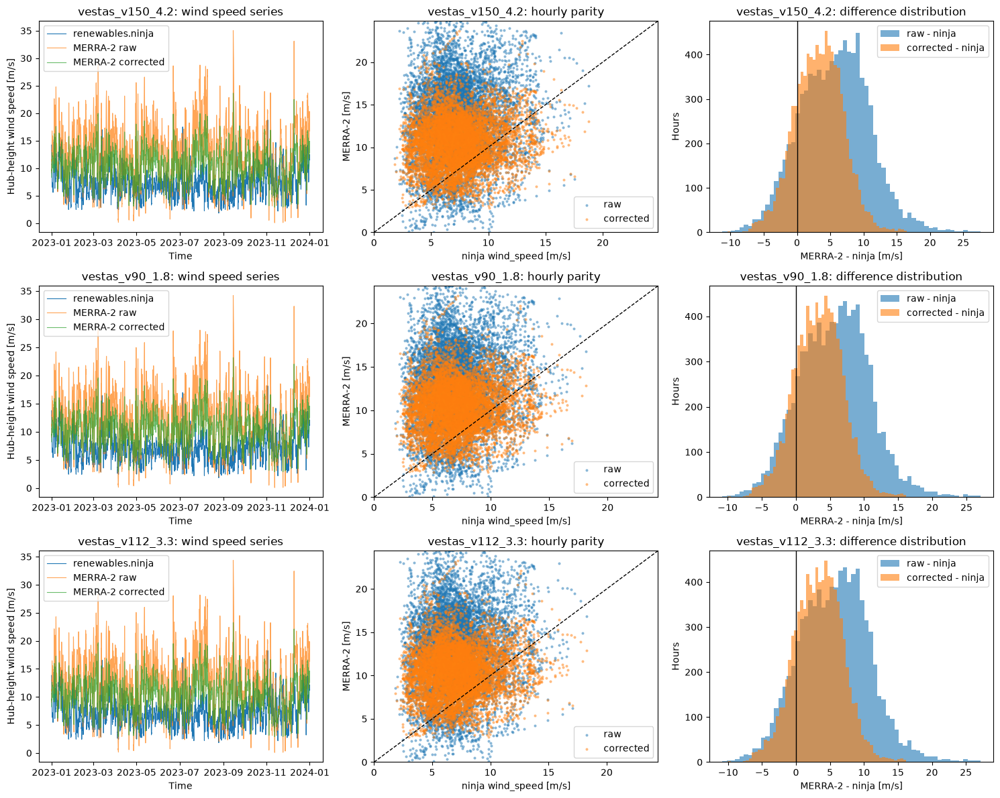

In [8]:
# cell 2: wind speed comparison plots per turbine (raw and corrected vs ninja)
fig, axes = plt.subplots(len(ws_results), 3, figsize=(15, 4 * len(ws_results)))
axes = np.atleast_2d(axes)

for row, (name, m) in enumerate(ws_results.items()):
    ax = axes[row, 0]
    ax.plot(m["time"], m["ninja_ws"], lw=0.8, label="renewables.ninja")
    ax.plot(m["time"], m["merra_raw"], lw=0.8, alpha=0.7, label="MERRA-2 raw")
    ax.plot(m["time"], m["merra_corr"], lw=0.8, alpha=0.7, label="MERRA-2 corrected")
    ax.set_xlabel("Time")
    ax.set_ylabel("Hub-height wind speed [m/s]")
    ax.set_title(f"{name}: wind speed series")
    ax.legend()

    ax = axes[row, 1]
    ax.scatter(m["ninja_ws"], m["merra_raw"], s=4, alpha=0.4, label="raw")
    ax.scatter(m["ninja_ws"], m["merra_corr"], s=4, alpha=0.4, label="corrected")
    lim = [0, max(m["ninja_ws"].max(), m["merra_corr"].max()) * 1.05]
    ax.plot(lim, lim, "k--", lw=1)
    ax.set_xlim(lim)
    ax.set_ylim(lim)
    ax.set_xlabel("ninja wind_speed [m/s]")
    ax.set_ylabel("MERRA-2 [m/s]")
    ax.set_title(f"{name}: hourly parity")
    ax.legend()

    ax = axes[row, 2]
    ax.hist(m["diff_raw"], bins=60, alpha=0.6, label="raw - ninja")
    ax.hist(m["diff_corr"], bins=60, alpha=0.6, label="corrected - ninja")
    ax.axvline(0, color="k", lw=1)
    ax.set_xlabel("MERRA-2 - ninja [m/s]")
    ax.set_ylabel("Hours")
    ax.set_title(f"{name}: difference distribution")
    ax.legend()

plt.tight_layout()
plt.show()

Conclusion: poor agreement between wind speeds extracted directly from MERRA2 and those processed through bias correction by renewables.ninja.

### Compare wakeless single-turbine FLORIS model with raw MERRA data input to renewables.ninja output

In [9]:
# Add electricity and direction to existing ws_results
for name, path in NINJA_FILES.items():
    ninja = pd.read_csv(path, skiprows=3, parse_dates=["time"])
    dir_col = "direction"
    
    ninja_kw = ninja.set_index("time")["electricity"]
    ws_results[name]["ninja_kw"] = ws_results[name]["time"].map(ninja_kw).to_numpy()
    
    merra_dir = merra.set_index("time")[dir_col]
    ws_results[name]["merra_dir"] = ws_results[name]["time"].map(merra_dir).to_numpy()

In [10]:
# Run FLORIS for all turbines with raw and corrected wind speeds
floris_results = {}

for name in NINJA_FILES.keys():
    turbine_dict = turbines[name]
    merged = ws_results[name]

    # FLORIS with raw MERRA
    fmodel_raw = FlorisModel("defaults")
    fmodel_raw.set(
        layout_x=[0.0], layout_y=[0.0],
        turbine_type=[turbine_dict],
        reference_wind_height=turbine_dict["hub_height"],
        wind_shear=0.0,
    )
    fmodel_raw.set(
        wind_speeds=merged["merra_raw"].to_numpy(),
        wind_directions=merged["merra_dir"].to_numpy(),
        turbulence_intensities=0.06 * np.ones(len(merged)),
    )
    fmodel_raw.run()
    power_raw = fmodel_raw.get_turbine_powers()[:, 0] / 1000.0

    # FLORIS with corrected MERRA
    fmodel_corr = FlorisModel("defaults")
    fmodel_corr.set(
        layout_x=[0.0], layout_y=[0.0],
        turbine_type=[turbine_dict],
        reference_wind_height=turbine_dict["hub_height"],
        wind_shear=0.0,
    )
    fmodel_corr.set(
        wind_speeds=merged["merra_corr"].to_numpy(),
        wind_directions=merged["merra_dir"].to_numpy(),
        turbulence_intensities=0.06 * np.ones(len(merged)),
    )
    fmodel_corr.run()
    power_corr = fmodel_corr.get_turbine_powers()[:, 0] / 1000.0

    floris_results[name] = {
        "ninja_kw": merged["ninja_kw"].to_numpy(),
        "floris_raw_kw": power_raw,
        "floris_corr_kw": power_corr,
        "time": merged["time"],
    }

In [11]:
# Print comparison statistics
for name, res in floris_results.items():
    ninja_kw = res["ninja_kw"]
    floris_raw = res["floris_raw_kw"]
    floris_corr = res["floris_corr_kw"]

    print(f"\n=== {name} ({len(ninja_kw)} hours) ===")

    for label, floris_kw in [("FLORIS (raw MERRA)", floris_raw), ("FLORIS (corr MERRA)", floris_corr)]:
        diff = floris_kw - ninja_kw
        print(f"\n{label} vs ninja:")
        print(f"  mean diff [kW]:     {diff.mean():.1f}")
        print(f"  MAE [kW]:           {np.abs(diff).mean():.1f}")
        print(f"  RMSE [kW]:          {np.sqrt((diff**2).mean()):.1f}")
        print(f"  AEP FLORIS [GWh]:   {floris_kw.sum()/1e6:.2f}")
        print(f"  AEP ninja [GWh]:    {ninja_kw.sum()/1e6:.2f}")
        print(f"  AEP ratio:          {floris_kw.sum()/ninja_kw.sum():.3f}")


=== vestas_v150_4.2 (8760 hours) ===

FLORIS (raw MERRA) vs ninja:
  mean diff [kW]:     1494.1
  MAE [kW]:           1874.0
  RMSE [kW]:          2189.0
  AEP FLORIS [GWh]:   30.86
  AEP ninja [GWh]:    17.77
  AEP ratio:          1.737

FLORIS (corr MERRA) vs ninja:
  mean diff [kW]:     1479.7
  MAE [kW]:           1772.7
  RMSE [kW]:          2107.8
  AEP FLORIS [GWh]:   30.73
  AEP ninja [GWh]:    17.77
  AEP ratio:          1.729

=== vestas_v90_1.8 (8760 hours) ===

FLORIS (raw MERRA) vs ninja:
  mean diff [kW]:     764.3
  MAE [kW]:           891.8
  RMSE [kW]:          1024.8
  AEP FLORIS [GWh]:   13.03
  AEP ninja [GWh]:    6.33
  AEP ratio:          2.058

FLORIS (corr MERRA) vs ninja:
  mean diff [kW]:     680.4
  MAE [kW]:           803.5
  RMSE [kW]:          946.5
  AEP FLORIS [GWh]:   12.29
  AEP ninja [GWh]:    6.33
  AEP ratio:          1.942

=== vestas_v112_3.3 (8760 hours) ===

FLORIS (raw MERRA) vs ninja:
  mean diff [kW]:     1458.9
  MAE [kW]:           1685.9


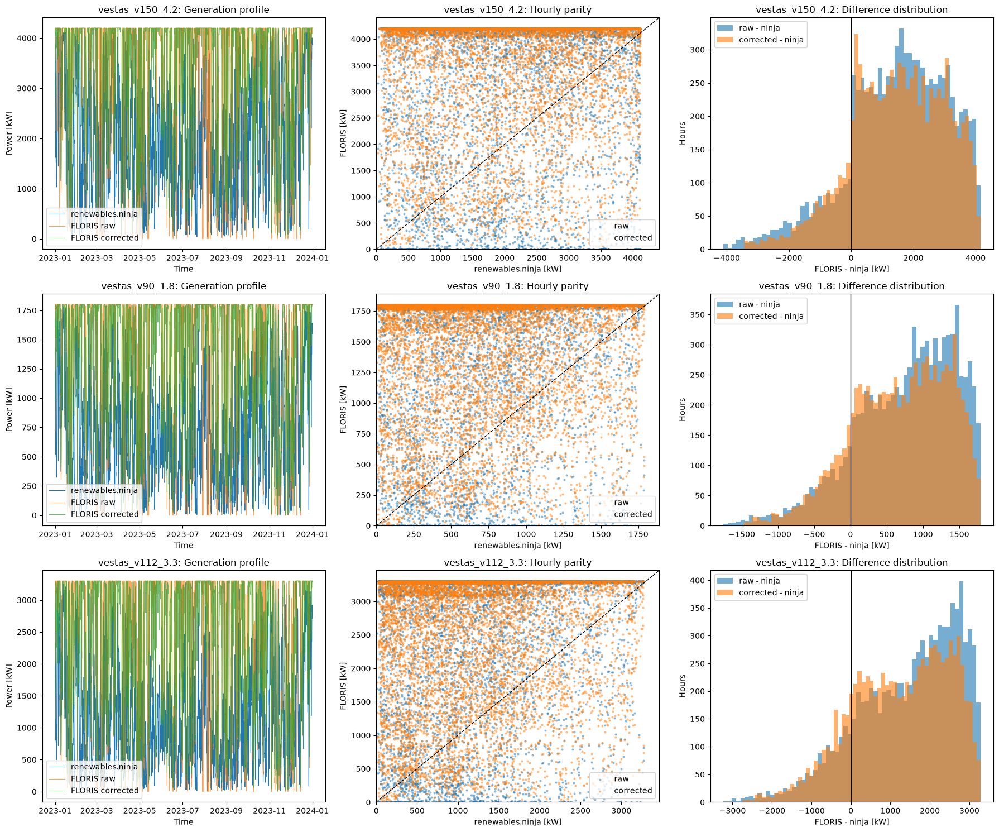

In [12]:
# Create comparison plots
n_turbines = len(floris_results)
fig, axes = plt.subplots(n_turbines, 3, figsize=(18, 5 * n_turbines))
axes = np.atleast_2d(axes)

for row, (name, res) in enumerate(floris_results.items()):
    time = res["time"]
    ninja_kw = res["ninja_kw"]
    floris_raw = res["floris_raw_kw"]
    floris_corr = res["floris_corr_kw"]

    ax = axes[row, 0]
    ax.plot(time, ninja_kw, lw=0.8, label="renewables.ninja")
    ax.plot(time, floris_raw, lw=0.8, alpha=0.7, label="FLORIS raw")
    ax.plot(time, floris_corr, lw=0.8, alpha=0.7, label="FLORIS corrected")
    ax.set_xlabel("Time")
    ax.set_ylabel("Power [kW]")
    ax.set_title(f"{name}: Generation profile")
    ax.legend()

    ax = axes[row, 1]
    ax.scatter(ninja_kw, floris_raw, s=4, alpha=0.4, label="raw")
    ax.scatter(ninja_kw, floris_corr, s=4, alpha=0.4, label="corrected")
    lim = [0, max(ninja_kw.max(), floris_corr.max()) * 1.05]
    ax.plot(lim, lim, "k--", lw=1)
    ax.set_xlim(lim)
    ax.set_ylim(lim)
    ax.set_xlabel("renewables.ninja [kW]")
    ax.set_ylabel("FLORIS [kW]")
    ax.set_title(f"{name}: Hourly parity")
    ax.legend()

    ax = axes[row, 2]
    ax.hist(floris_raw - ninja_kw, bins=60, alpha=0.6, label="raw - ninja")
    ax.hist(floris_corr - ninja_kw, bins=60, alpha=0.6, label="corrected - ninja")
    ax.axvline(0, color="k", lw=1)
    ax.set_xlabel("FLORIS - ninja [kW]")
    ax.set_ylabel("Hours")
    ax.set_title(f"{name}: Difference distribution")
    ax.legend()

plt.tight_layout()
plt.show()

Conclusion: poor agreement between FLORIS model relying on raw MERRA2 wind speeds and VWF model relying on bias corrected wind speeds.

### Compare KNMI meteorological station wind speeds to renewables.ninja bias corrected wind speeds

In [13]:
# Cell A: load all three KNMI stations, log-law to each turbine hub height
import numpy as np
import pandas as pd

KNMI_FILES = {
    240: "uurgeg_240_2021-2030.txt",  # Schiphol
    275: "uurgeg_275_2021-2030.txt",  # Deelen
    348: "uurgeg_348_2021-2030.txt",  # Cabauw
    260: "uurgeg_260_2021-2030.txt",  # De Bilt
    267: "uurgeg_267_2021-2030.txt",  # Stavoren
    269: "uurgeg_269_2021-2030.txt",  # Lelystad
    273: "uurgeg_273_2021-2030.txt",  # Marknesse
    278: "uurgeg_278_2021-2030.txt",  # Heino
    356: "uurgeg_356_2021-2030.txt",  # Herwijnen
}

Z0_BY_STATION = {
    240: 0.1,
    275: 0.03,
    348: 0.03,
    260: 0.4,
    267: 0.03,
    269: 0.03,
    273: 0.1,
    278: 0.03,
    356: 0.03,
}
H_REF = 10.0
YEAR = 2023

KNMI_COLS = ["STN", "yyyymmdd", "hh", "DD", "FH", "FF", "FX",
             "T", "T10N", "TD", "SQ", "Q", "DR", "RH", "P",
             "VV", "N", "U", "WW", "IX", "M", "R", "S", "O", "Y"]


def load_knmi(path, year=YEAR):
    with open(path) as f:
        lines = f.readlines()
    start = next(i for i, ln in enumerate(lines) if ln.strip() and ln.strip()[0].isdigit())
    df = pd.read_csv(
        path, skiprows=start, header=None, names=KNMI_COLS,
        usecols=["yyyymmdd", "hh", "DD", "FH", "FF", "FX"],
        dtype=str, skipinitialspace=True,
    )
    for c in ["DD", "FH", "FF", "FX"]:
        df[c] = pd.to_numeric(df[c].str.strip(), errors="coerce")
    df["yyyymmdd"] = df["yyyymmdd"].str.strip()
    df["hh"] = df["hh"].str.strip()
    df["time"] = (
        pd.to_datetime(df["yyyymmdd"], format="%Y%m%d")
        + pd.to_timedelta(df["hh"].astype(int) - 1, unit="h")
    )
    df["ws_10m"] = df["FH"] / 10.0
    df["ws_10m_10min"] = df["FF"] / 10.0
    df["ws_gust"] = df["FX"] / 10.0
    out = df.loc[df["time"].dt.year == year,
                 ["time", "DD", "ws_10m", "ws_10m_10min", "ws_gust"]].reset_index(drop=True)
    return out


knmi = {stn: load_knmi(path) for stn, path in KNMI_FILES.items()}

for stn, df in knmi.items():
    print(f"STN {stn}: {len(df)} rows, {df['time'].min()} to {df['time'].max()}, "
          f"mean 10 m = {df['ws_10m'].mean():.3f} m/s")

# Extrapolate to each turbine hub height using station-specific z0
for name, t in turbines.items():
    h_hub = t["hub_height"]
    for stn, df in knmi.items():
        z0 = Z0_BY_STATION[stn]
        ratio = np.log(h_hub / z0) / np.log(H_REF / z0)
        knmi[stn][f"ws_hub_{name}"] = df["ws_10m"] * ratio
        print(f"STN {stn} -> {name} (hub {h_hub} m, z0={z0}): scale {ratio:.3f}, "
              f"mean hub {knmi[stn][f'ws_hub_{name}'].mean():.3f} m/s")

STN 240: 8760 rows, 2023-01-01 00:00:00 to 2023-12-31 23:00:00, mean 10 m = 5.209 m/s
STN 275: 8760 rows, 2023-01-01 00:00:00 to 2023-12-31 23:00:00, mean 10 m = 3.894 m/s
STN 348: 8760 rows, 2023-01-01 00:00:00 to 2023-12-31 23:00:00, mean 10 m = 4.486 m/s
STN 260: 8760 rows, 2023-01-01 00:00:00 to 2023-12-31 23:00:00, mean 10 m = 3.516 m/s
STN 267: 8760 rows, 2023-01-01 00:00:00 to 2023-12-31 23:00:00, mean 10 m = 5.818 m/s
STN 269: 8760 rows, 2023-01-01 00:00:00 to 2023-12-31 23:00:00, mean 10 m = 4.507 m/s
STN 273: 8760 rows, 2023-01-01 00:00:00 to 2023-12-31 23:00:00, mean 10 m = 4.083 m/s
STN 278: 8760 rows, 2023-01-01 00:00:00 to 2023-12-31 23:00:00, mean 10 m = 3.100 m/s
STN 356: 8760 rows, 2023-01-01 00:00:00 to 2023-12-31 23:00:00, mean 10 m = 4.205 m/s
STN 240 -> vestas_v150_4.2 (hub 105.0 m, z0=0.1): scale 1.511, mean hub 7.868 m/s
STN 275 -> vestas_v150_4.2 (hub 105.0 m, z0=0.03): scale 1.405, mean hub 5.470 m/s
STN 348 -> vestas_v150_4.2 (hub 105.0 m, z0=0.03): scale 1.40


=== STN 240 / vestas_v150_4.2 (8760 hours) ===
mean KNMI hub [m/s]:   7.868
mean ninja    [m/s]:   7.360
mean diff     [m/s]:   0.508
std diff      [m/s]:   2.509
MAE           [m/s]:   2.036
RMSE          [m/s]:   2.560
RMSE above cut-in:     2.572
correlation:           0.8652

=== STN 275 / vestas_v150_4.2 (8760 hours) ===
mean KNMI hub [m/s]:   5.470
mean ninja    [m/s]:   7.360
mean diff     [m/s]:   -1.891
std diff      [m/s]:   1.823
MAE           [m/s]:   2.138
RMSE          [m/s]:   2.626
RMSE above cut-in:     2.638
correlation:           0.7915

=== STN 348 / vestas_v150_4.2 (8760 hours) ===
mean KNMI hub [m/s]:   6.302
mean ninja    [m/s]:   7.360
mean diff     [m/s]:   -1.058
std diff      [m/s]:   1.998
MAE           [m/s]:   1.838
RMSE          [m/s]:   2.261
RMSE above cut-in:     2.271
correlation:           0.8506

=== STN 260 / vestas_v150_4.2 (8760 hours) ===
mean KNMI hub [m/s]:   6.084
mean ninja    [m/s]:   7.360
mean diff     [m/s]:   -1.276
std diff      [m/s]

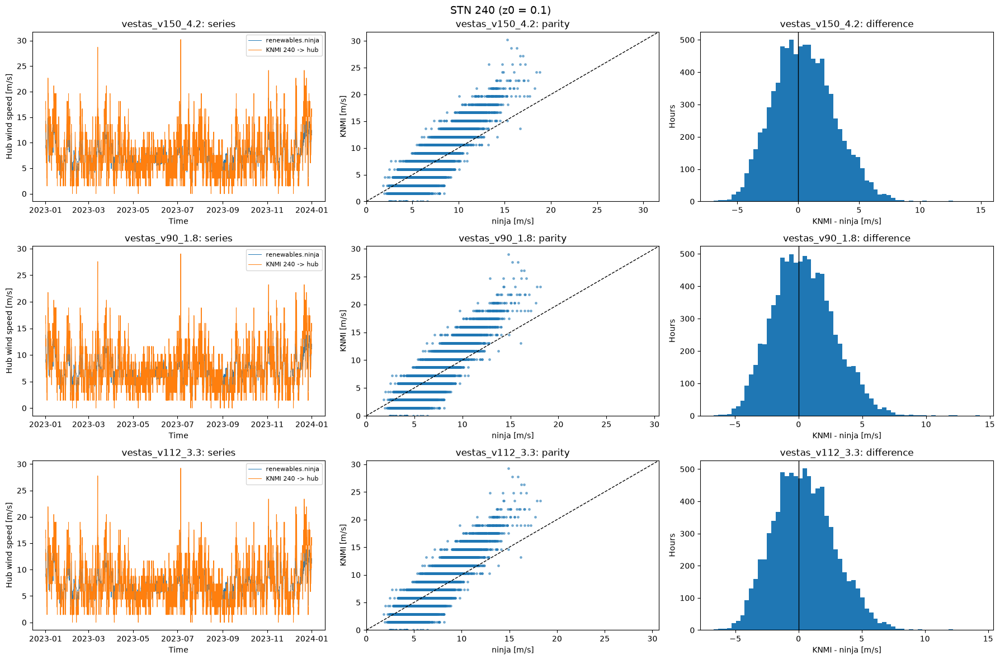

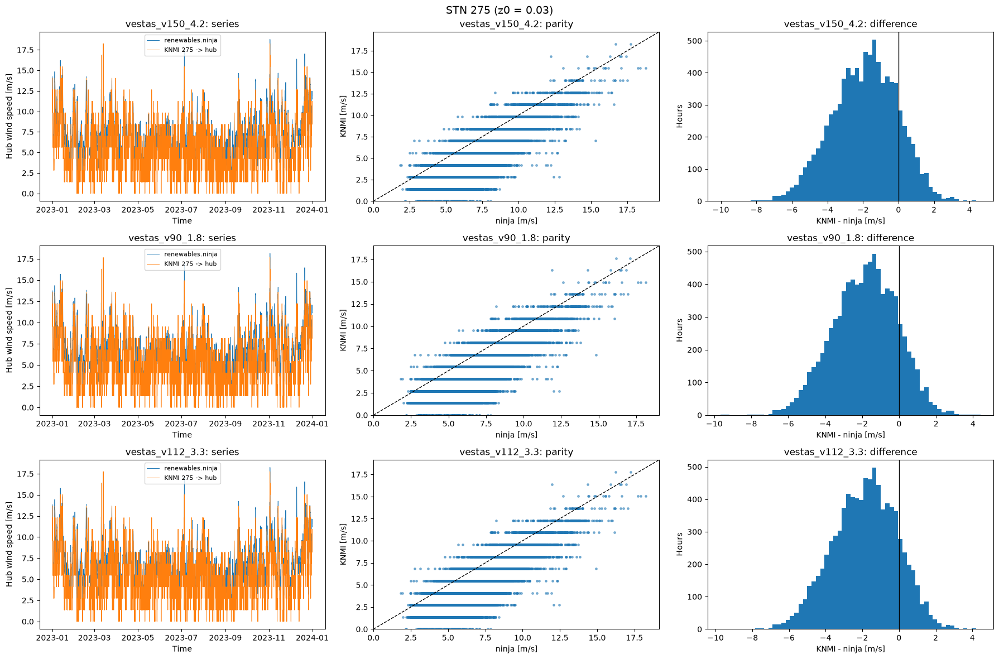

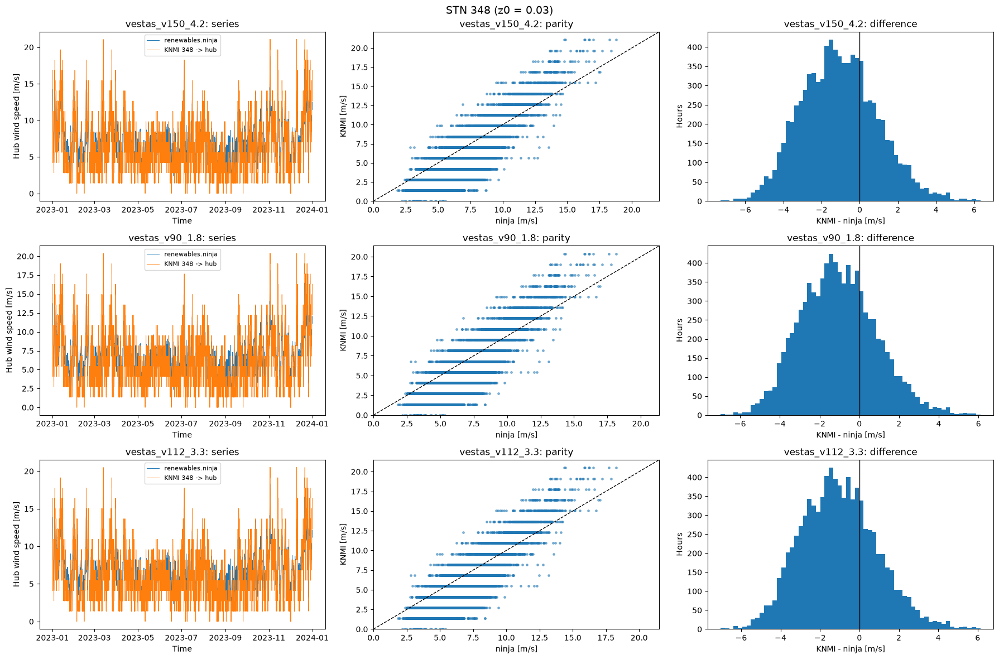

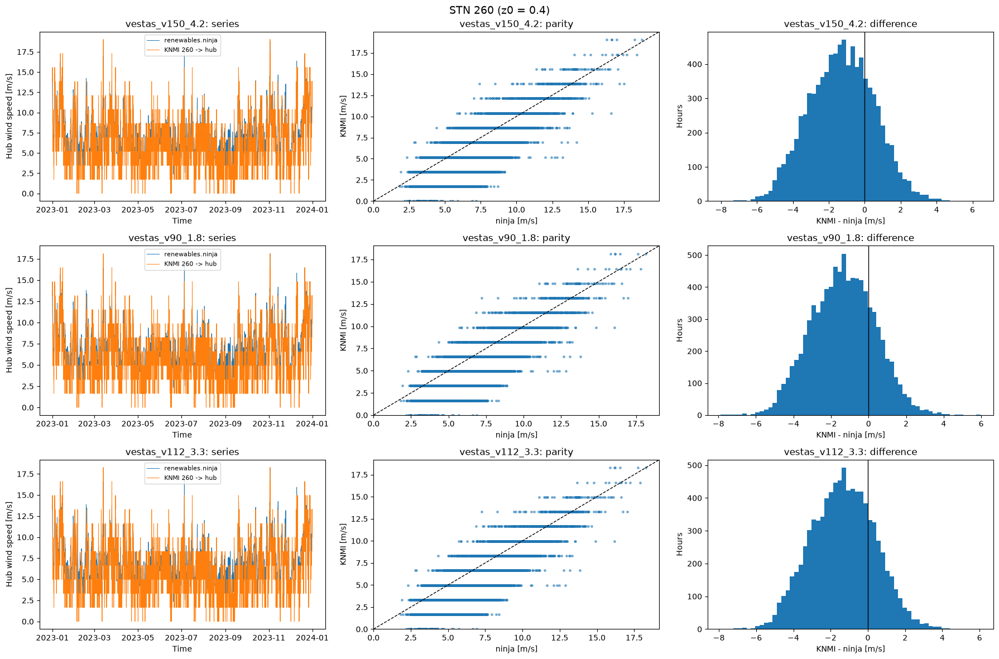

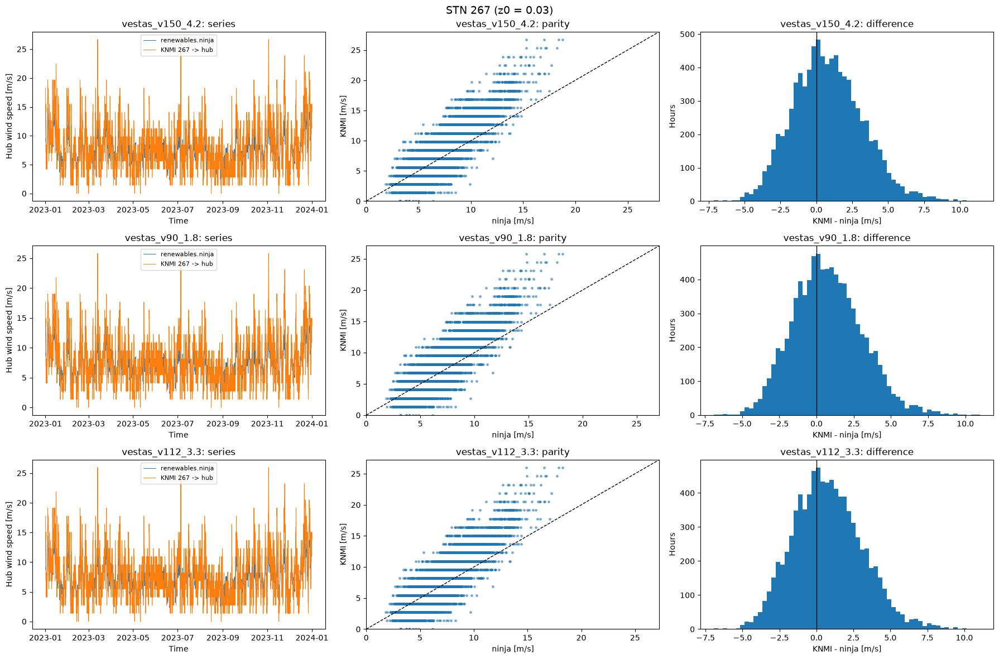

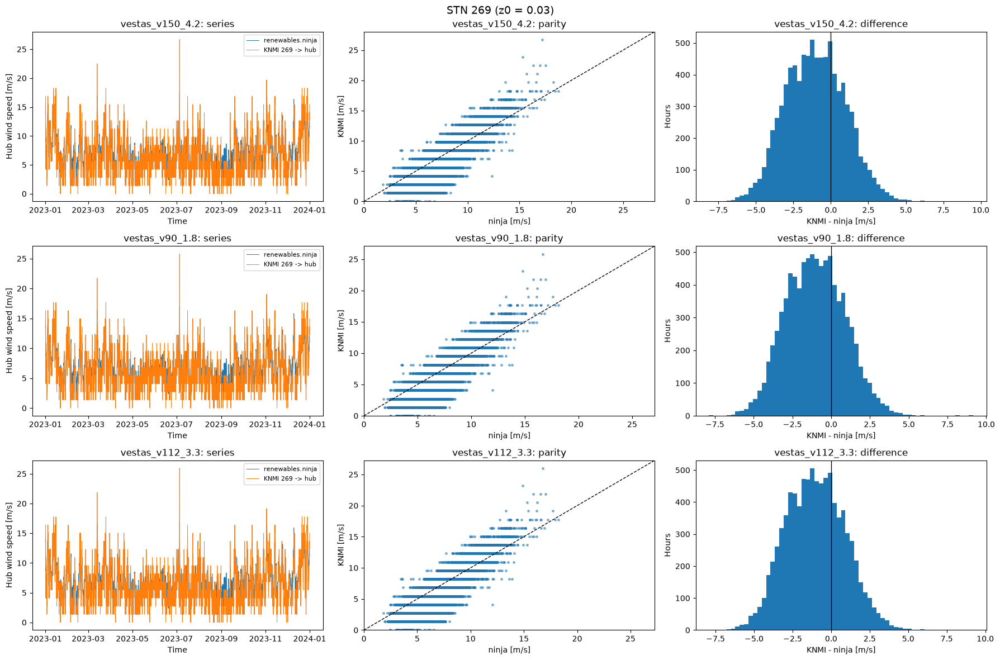

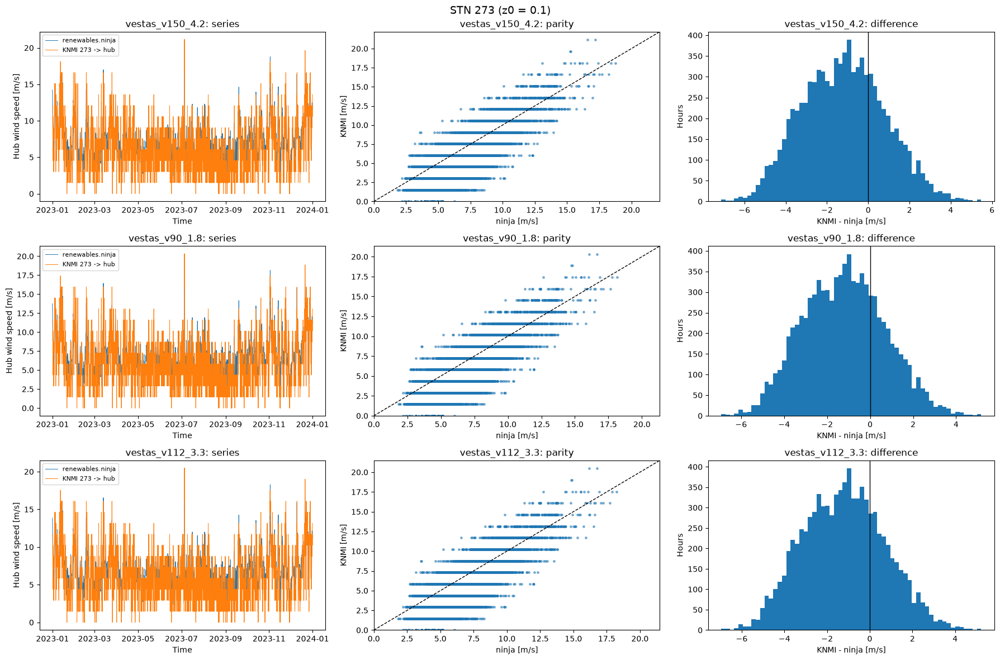

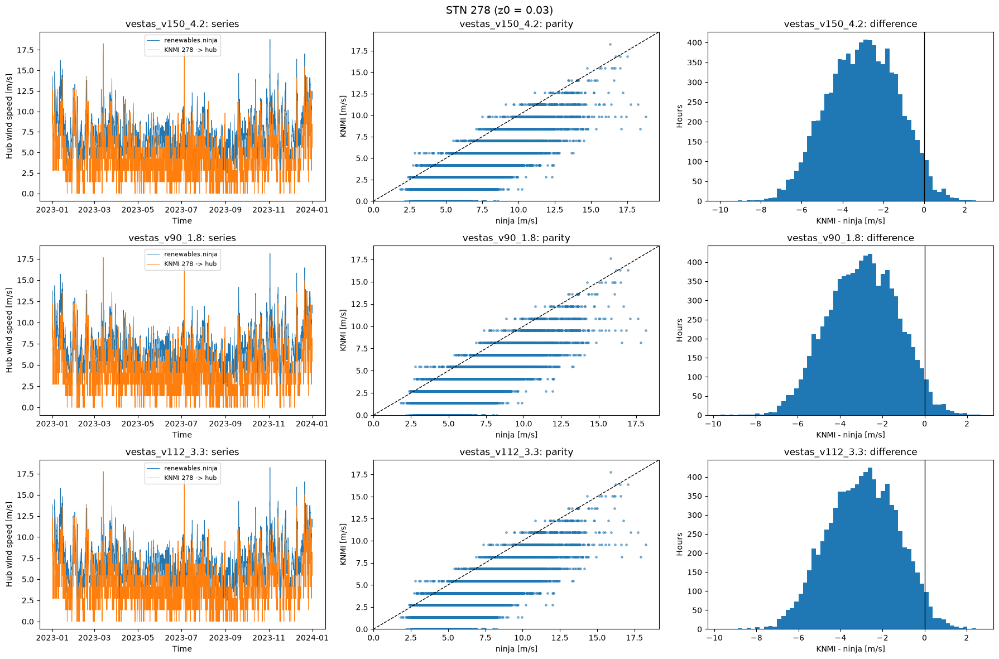

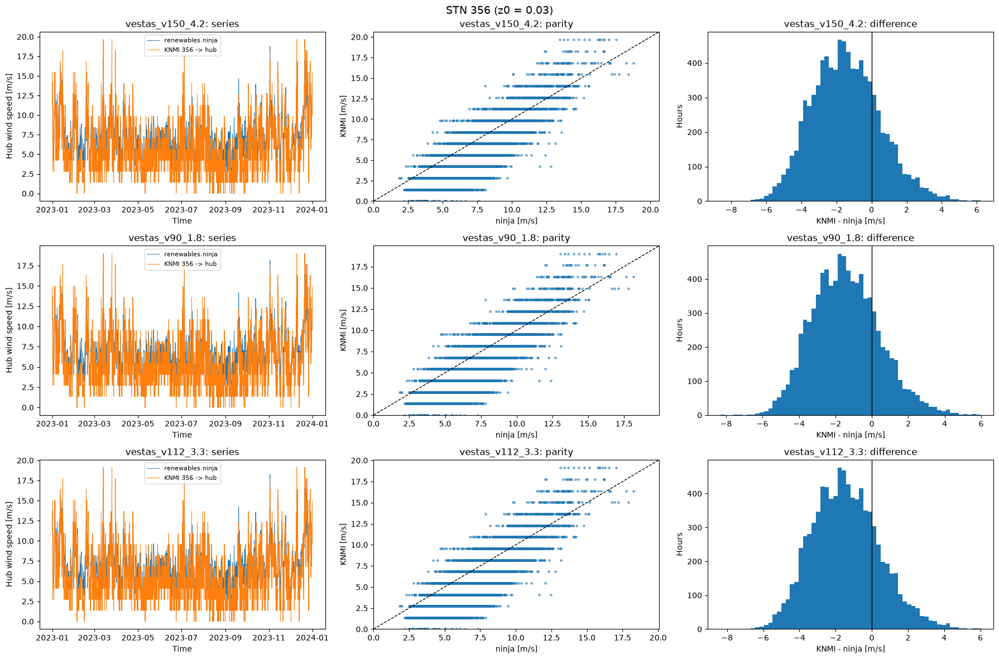

In [14]:
# Cell B: KNMI hub speed vs renewables.ninja, one figure per station
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ws_results_knmi = {}

for name, path in NINJA_FILES.items():
    ninja = pd.read_csv(path, skiprows=3, parse_dates=["time"])[["time", "wind_speed"]]
    for stn, df in knmi.items():
        m = df[["time", "DD", f"ws_hub_{name}"]].merge(ninja, on="time", how="inner")
        m = m.rename(columns={f"ws_hub_{name}": "knmi_hub", "wind_speed": "ninja_ws"})
        m["diff"] = m["knmi_hub"] - m["ninja_ws"]
        ws_results_knmi[(stn, name)] = m

        mask = m["ninja_ws"] >= 3.0
        d = m["diff"]
        print(f"\n=== STN {stn} / {name} ({len(m)} hours) ===")
        print(f"mean KNMI hub [m/s]:   {m['knmi_hub'].mean():.3f}")
        print(f"mean ninja    [m/s]:   {m['ninja_ws'].mean():.3f}")
        print(f"mean diff     [m/s]:   {d.mean():.3f}")
        print(f"std diff      [m/s]:   {d.std():.3f}")
        print(f"MAE           [m/s]:   {np.abs(d).mean():.3f}")
        print(f"RMSE          [m/s]:   {np.sqrt((d**2).mean()):.3f}")
        print(f"RMSE above cut-in:     {np.sqrt((d[mask]**2).mean()):.3f}")
        print(f"correlation:           {np.corrcoef(m['knmi_hub'], m['ninja_ws'])[0,1]:.4f}")

# One figure per station, rows = turbines, cols = series / parity / difference
names = list(NINJA_FILES.keys())

for stn in knmi.keys():
    fig, axes = plt.subplots(len(names), 3, figsize=(18, 4 * len(names)), squeeze=False)
    fig.suptitle(f"STN {stn} (z0 = {Z0_BY_STATION[stn]})", fontsize=14)

    for row, name in enumerate(names):
        m = ws_results_knmi[(stn, name)]

        ax = axes[row, 0]
        ax.plot(m["time"], m["ninja_ws"], lw=0.7, label="renewables.ninja")
        ax.plot(m["time"], m["knmi_hub"], lw=0.7, label=f"KNMI {stn} -> hub")
        ax.set_xlabel("Time"); ax.set_ylabel("Hub wind speed [m/s]")
        ax.set_title(f"{name}: series"); ax.legend(fontsize=8)

        ax = axes[row, 1]
        ax.scatter(m["ninja_ws"], m["knmi_hub"], s=6, alpha=0.5)
        lim = [0, max(m["ninja_ws"].max(), m["knmi_hub"].max()) * 1.05]
        ax.plot(lim, lim, "k--", lw=1)
        ax.set_xlim(lim); ax.set_ylim(lim)
        ax.set_xlabel("ninja [m/s]"); ax.set_ylabel("KNMI [m/s]")
        ax.set_title(f"{name}: parity")

        ax = axes[row, 2]
        ax.hist(m["diff"], bins=60); ax.axvline(0, color="k", lw=1)
        ax.set_xlabel("KNMI - ninja [m/s]"); ax.set_ylabel("Hours")
        ax.set_title(f"{name}: difference")

    plt.tight_layout()
    plt.show()


=== STN 240 / vestas_v150_4.2 (8760 hours) ===
FLORIS mean [kW]:          2113.2
ninja mean  [kW]:          2028.6
mean diff   [kW]:          84.7
mean diff above cut-in:    131.2
MAE above cut-in [kW]:     834.8
RMSE above cut-in [kW]:    1030.4
FLORIS AEP [GWh]:          18512.06
ninja AEP  [GWh]:          17770.37
AEP ratio FLORIS/ninja:    1.042

=== STN 275 / vestas_v150_4.2 (8760 hours) ===
FLORIS mean [kW]:          1254.9
ninja mean  [kW]:          2028.6
mean diff   [kW]:          -773.7
mean diff above cut-in:    -663.6
MAE above cut-in [kW]:     900.6
RMSE above cut-in [kW]:    1140.6
FLORIS AEP [GWh]:          10992.67
ninja AEP  [GWh]:          17770.37
AEP ratio FLORIS/ninja:    0.619

=== STN 348 / vestas_v150_4.2 (8760 hours) ===
FLORIS mean [kW]:          1527.8
ninja mean  [kW]:          2028.6
mean diff   [kW]:          -500.8
mean diff above cut-in:    -379.9
MAE above cut-in [kW]:     836.0
RMSE above cut-in [kW]:    1050.4
FLORIS AEP [GWh]:          13383.40
ninj

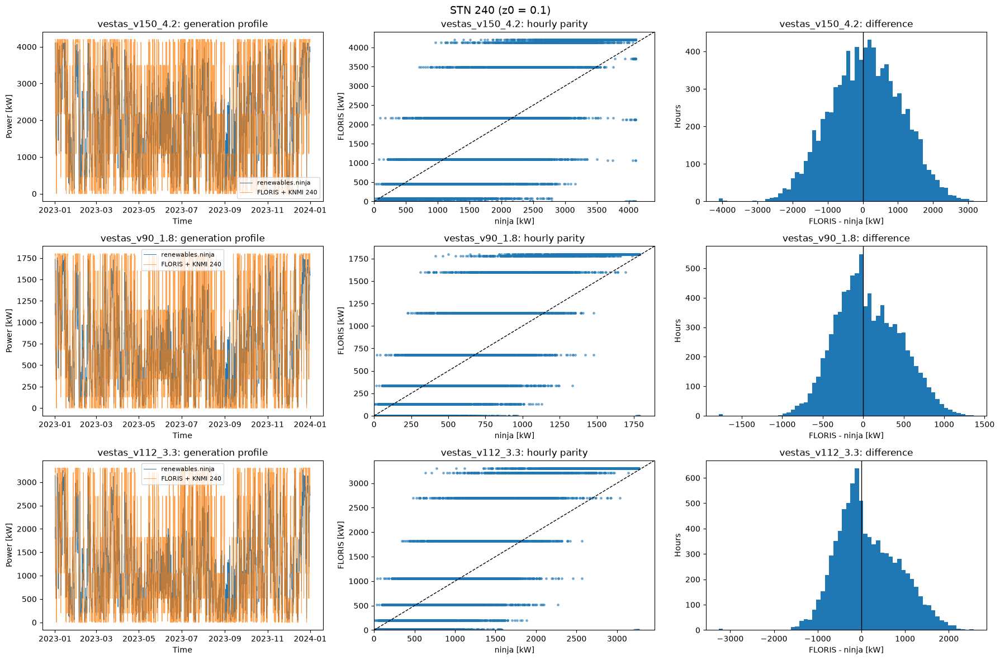

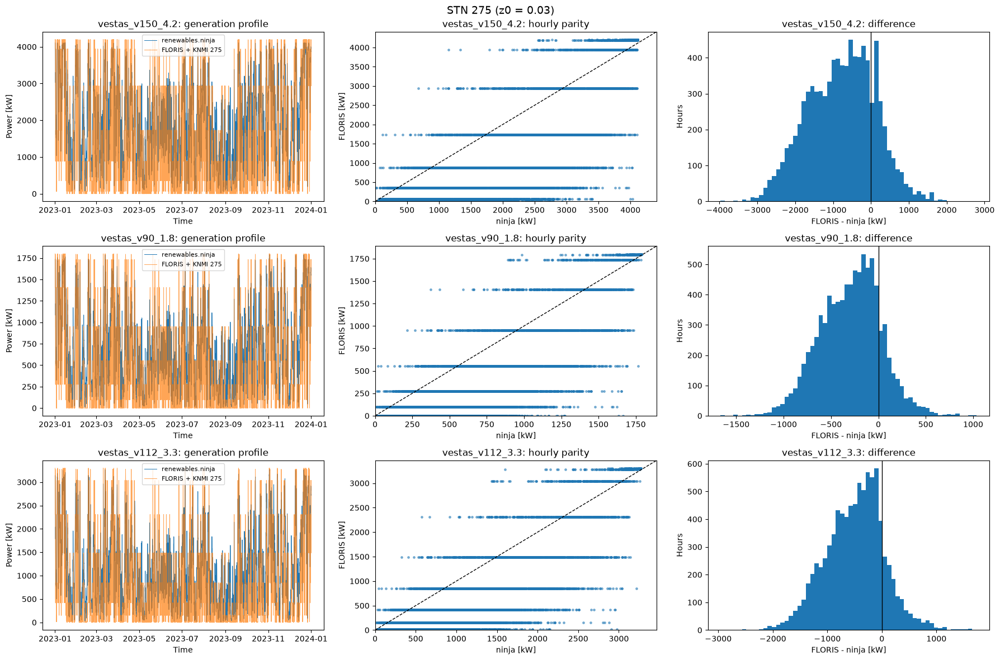

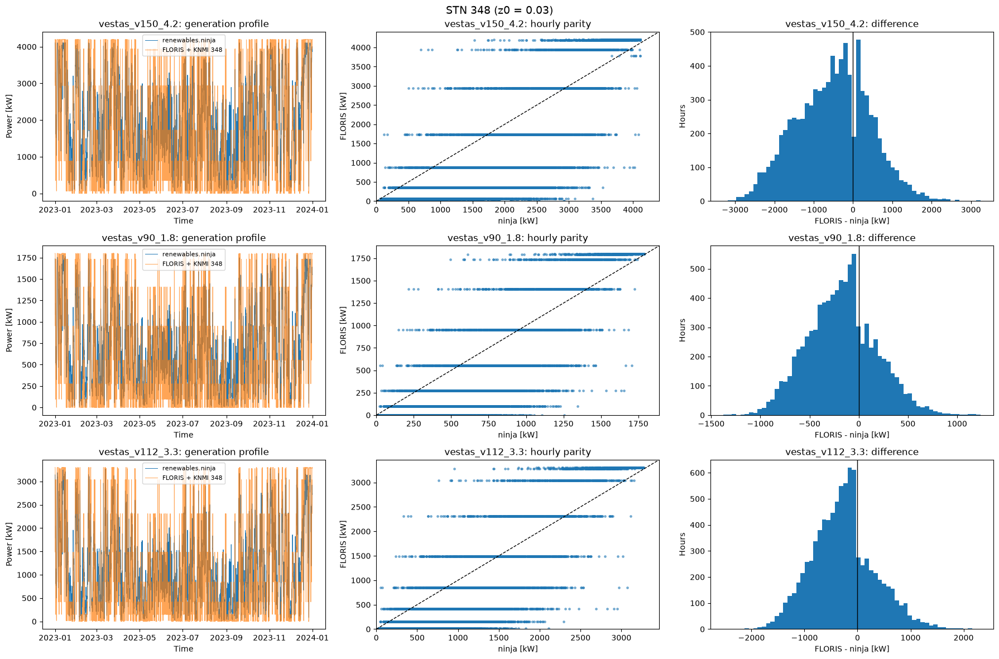

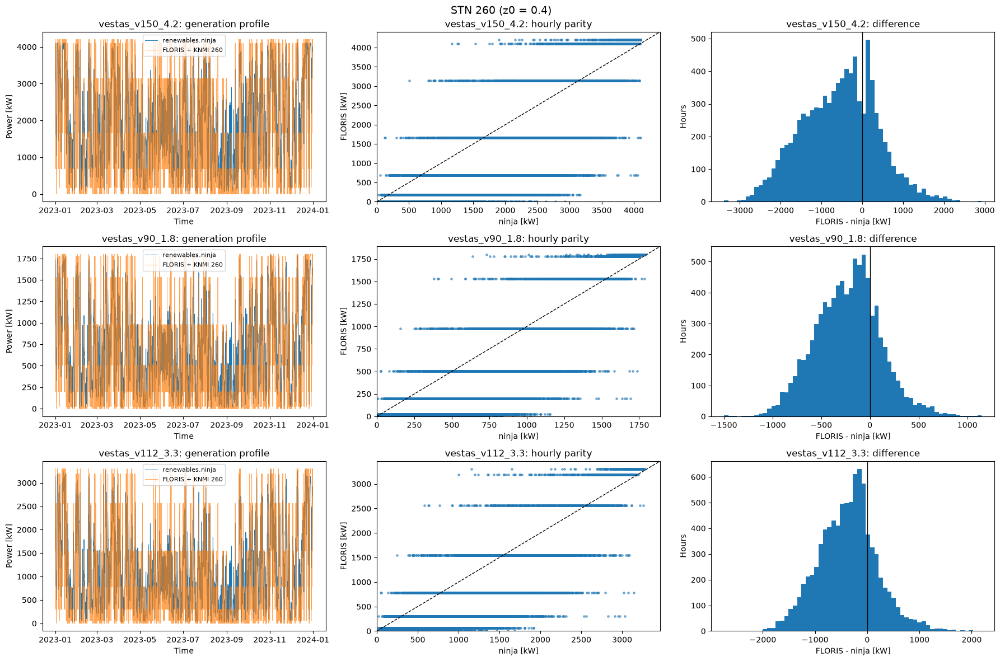

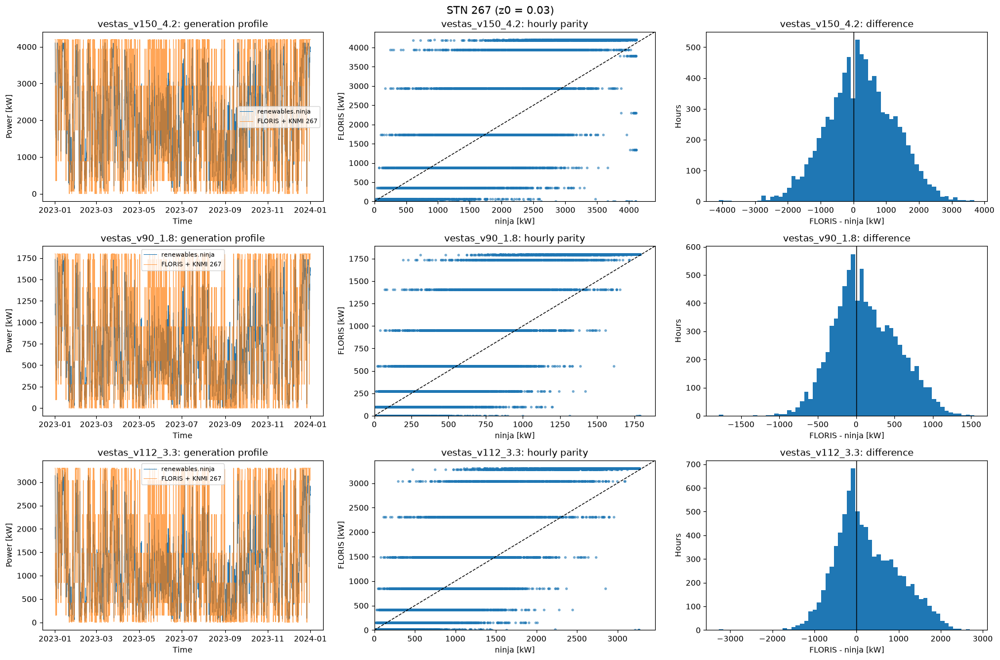

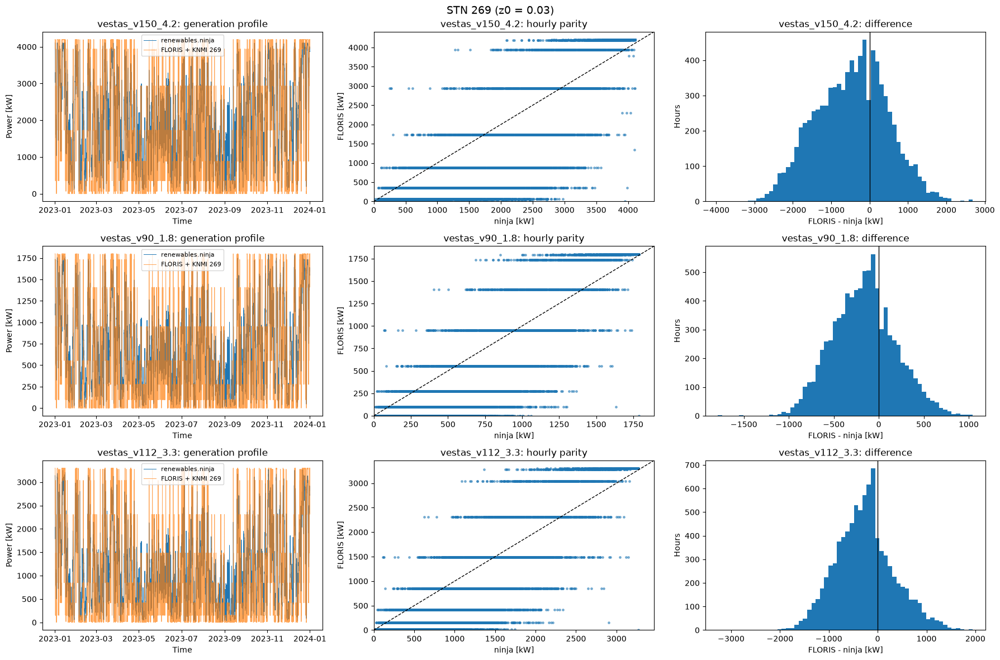

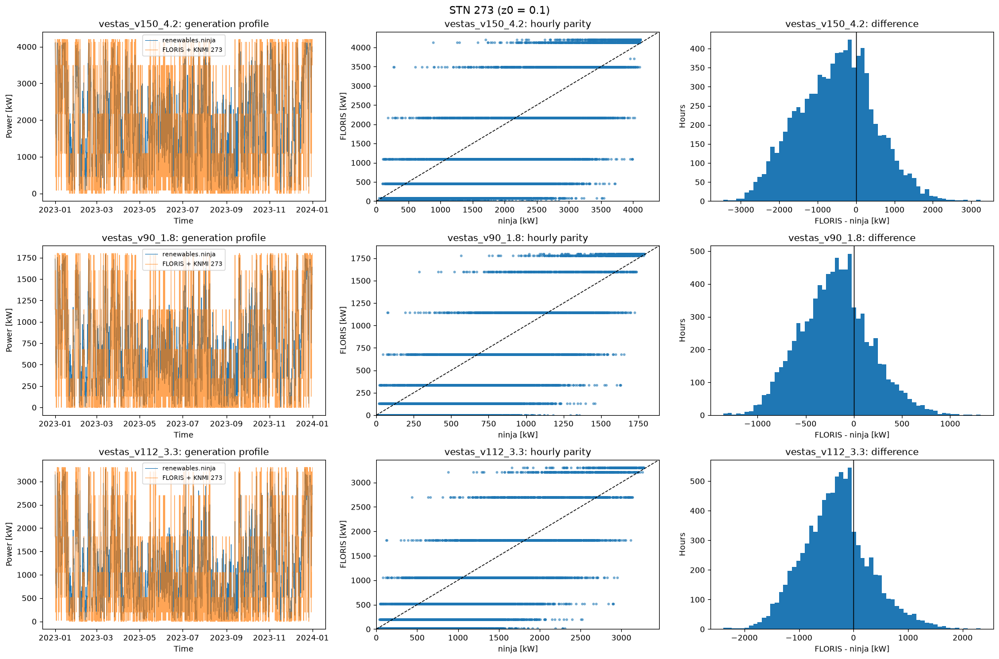

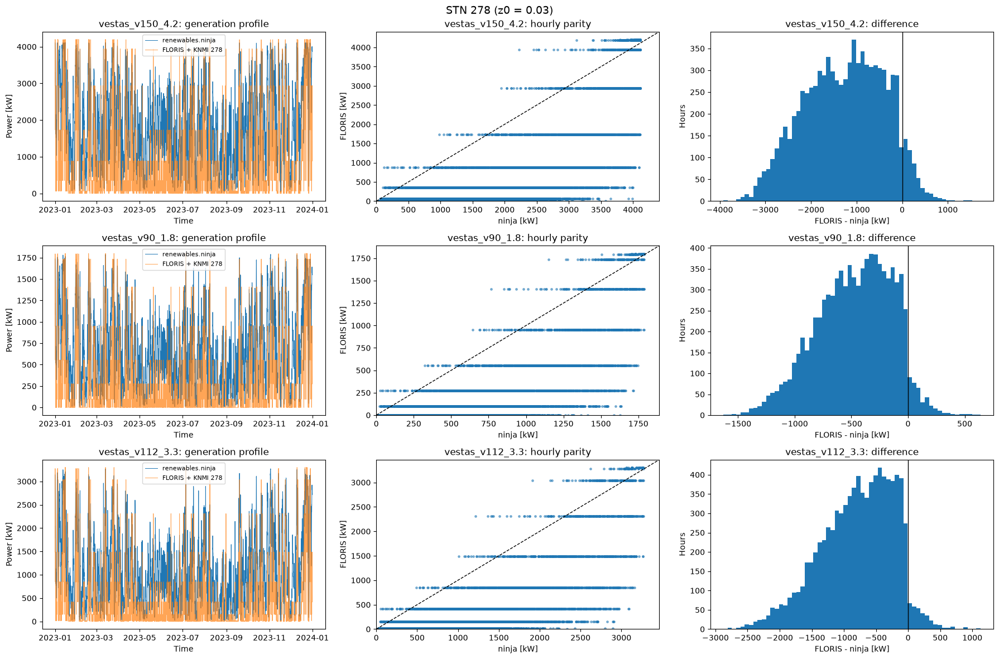

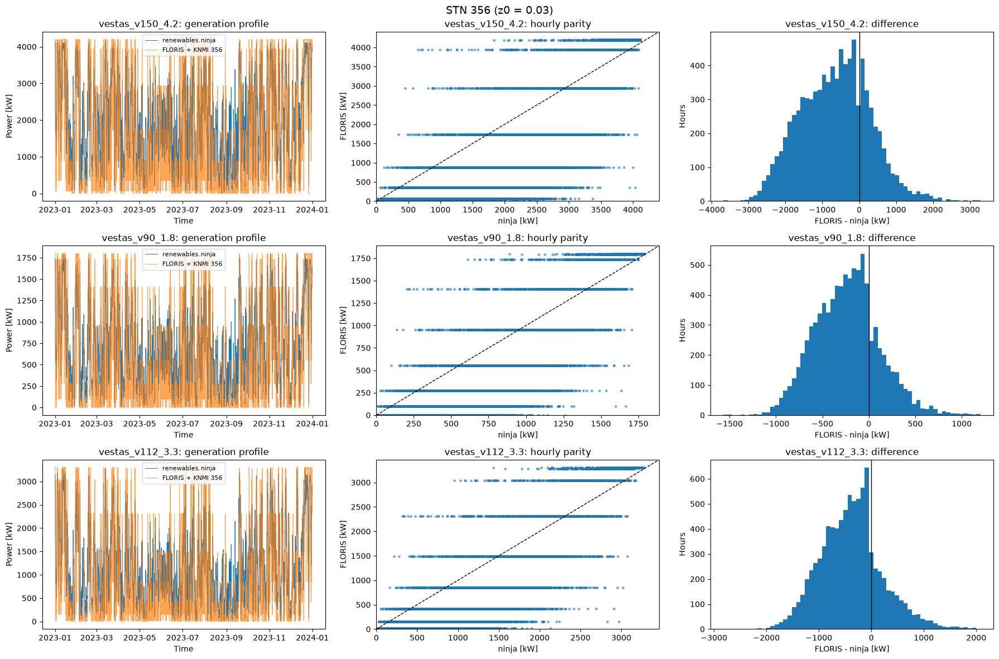

In [15]:
# Cell C: FLORIS on KNMI hub speeds vs renewables.ninja power, one figure per station
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from floris import FlorisModel

floris_results_knmi = {}

for name in NINJA_FILES.keys():
    t = turbines[name]
    for stn in knmi.keys():
        m = ws_results_knmi[(stn, name)][["time", "DD", "knmi_hub"]].copy()

        # replace missing/zero hub speeds with a tiny number instead of dropping
        ws = m["knmi_hub"].to_numpy(dtype=float).copy()
        ws[~np.isfinite(ws) | (ws <= 0)] = 0.001

        # handle direction: fill calm/variable with interpolation
        DD = m["DD"].where(m["DD"].between(1, 360)).interpolate().ffill().bfill().to_numpy(dtype=float)

        fm = FlorisModel("defaults")
        fm.set(
            layout_x=[0.0], layout_y=[0.0], turbine_type=[t],
            reference_wind_height=t["hub_height"], wind_shear=0.0,
        )
        fm.set(
            wind_speeds=ws,
            wind_directions=DD,
            turbulence_intensities=0.06 * np.ones_like(ws),
        )
        fm.run()
        floris_kw = fm.get_turbine_powers()[:, 0] / 1000.0

        floris_results_knmi[(stn, name)] = {
            "time": m["time"].to_numpy(),
            "ws": ws,
            "floris_kw": floris_kw,
        }

# Pull ninja electricity (kW) once per turbine and align
for name, path in NINJA_FILES.items():
    ninja = pd.read_csv(path, skiprows=3, parse_dates=["time"])[["time", "electricity"]]
    ninja_kw = ninja.set_index("time")["electricity"]
    for stn in knmi.keys():
        r = floris_results_knmi[(stn, name)]
        r["ninja_kw"] = pd.Series(r["time"]).map(ninja_kw).to_numpy(dtype=float)

for (stn, name), r in floris_results_knmi.items():
    ws = r["ws"]; f = r["floris_kw"]; n = r["ninja_kw"]
    d = f - n
    mask = ws >= 3.0
    print(f"\n=== STN {stn} / {name} ({len(ws)} hours) ===")
    print(f"FLORIS mean [kW]:          {f.mean():.1f}")
    print(f"ninja mean  [kW]:          {n.mean():.1f}")
    print(f"mean diff   [kW]:          {d.mean():.1f}")
    print(f"mean diff above cut-in:    {d[mask].mean():.1f}")
    print(f"MAE above cut-in [kW]:     {np.abs(d[mask]).mean():.1f}")
    print(f"RMSE above cut-in [kW]:    {np.sqrt((d[mask]**2).mean()):.1f}")
    print(f"FLORIS AEP [GWh]:          {f.sum()/1e3:.2f}")
    print(f"ninja AEP  [GWh]:          {n.sum()/1e3:.2f}")
    print(f"AEP ratio FLORIS/ninja:    {f.sum()/n.sum():.3f}")

# One figure per station, rows = turbines, cols = series / parity / difference
names = list(NINJA_FILES.keys())

for stn in knmi.keys():
    fig, axes = plt.subplots(len(names), 3, figsize=(18, 4 * len(names)), squeeze=False)
    fig.suptitle(f"STN {stn} (z0 = {Z0_BY_STATION[stn]})", fontsize=14)

    for row, name in enumerate(names):
        r = floris_results_knmi[(stn, name)]
        t = r["time"]; f = r["floris_kw"]; n = r["ninja_kw"]

        ax = axes[row, 0]
        ax.plot(t, n, lw=0.7, label="renewables.ninja")
        ax.plot(t, f, lw=0.7, alpha=0.7, label=f"FLORIS + KNMI {stn}")
        ax.set_xlabel("Time"); ax.set_ylabel("Power [kW]")
        ax.set_title(f"{name}: generation profile"); ax.legend(fontsize=8)

        ax = axes[row, 1]
        ax.scatter(n, f, s=6, alpha=0.5)
        lim = [0, max(np.nanmax(n), np.nanmax(f)) * 1.05]
        ax.plot(lim, lim, "k--", lw=1)
        ax.set_xlim(lim); ax.set_ylim(lim)
        ax.set_xlabel("ninja [kW]"); ax.set_ylabel("FLORIS [kW]")
        ax.set_title(f"{name}: hourly parity")

        ax = axes[row, 2]
        ax.hist(f - n, bins=60); ax.axvline(0, color="k", lw=1)
        ax.set_xlabel("FLORIS - ninja [kW]"); ax.set_ylabel("Hours")
        ax.set_title(f"{name}: difference")

    plt.tight_layout()
    plt.show()

Conclusion: compared to the renewables.ninja bias corrected wind speeds, measured wind speeds are structurally lower at De Bilt (despite using different surface roughness values that should fit the location of each station), and reasonably correlated on an hourly basis at Stavoren and Lelystad (with Lelystad again on the lower side). This structural difference propagates into the power output: the AEP at Stavoren and Lelystad matches the renewables.ninja output, and it is structurally lower at De Bilt. Despite matching the high-level yearly output, time-dependent hourly output does not perfectly match.

### Check correlations between KNMI wind speed and resulting FLORIS single-turbine power output compared to renewables.ninja outputs

STN 240 / vestas_v150_4.2:
   monthly: n=  12  r=0.9691
    weekly: n=  53  r=0.9759
     daily: n= 365  r=0.9617
STN 275 / vestas_v150_4.2:
   monthly: n=  12  r=0.9575
    weekly: n=  53  r=0.9656
     daily: n= 365  r=0.9443
STN 348 / vestas_v150_4.2:
   monthly: n=  12  r=0.9882
    weekly: n=  53  r=0.9803
     daily: n= 365  r=0.9564
STN 260 / vestas_v150_4.2:
   monthly: n=  12  r=0.9464
    weekly: n=  53  r=0.9619
     daily: n= 365  r=0.9465
STN 267 / vestas_v150_4.2:
   monthly: n=  12  r=0.9659
    weekly: n=  53  r=0.9548
     daily: n= 365  r=0.9221
STN 269 / vestas_v150_4.2:
   monthly: n=  12  r=0.9735
    weekly: n=  53  r=0.9746
     daily: n= 365  r=0.9535
STN 273 / vestas_v150_4.2:
   monthly: n=  12  r=0.9354
    weekly: n=  53  r=0.9517
     daily: n= 365  r=0.9286
STN 278 / vestas_v150_4.2:
   monthly: n=  12  r=0.9650
    weekly: n=  53  r=0.9567
     daily: n= 365  r=0.9171
STN 356 / vestas_v150_4.2:
   monthly: n=  12  r=0.9730
    weekly: n=  53  r=0.9672
   

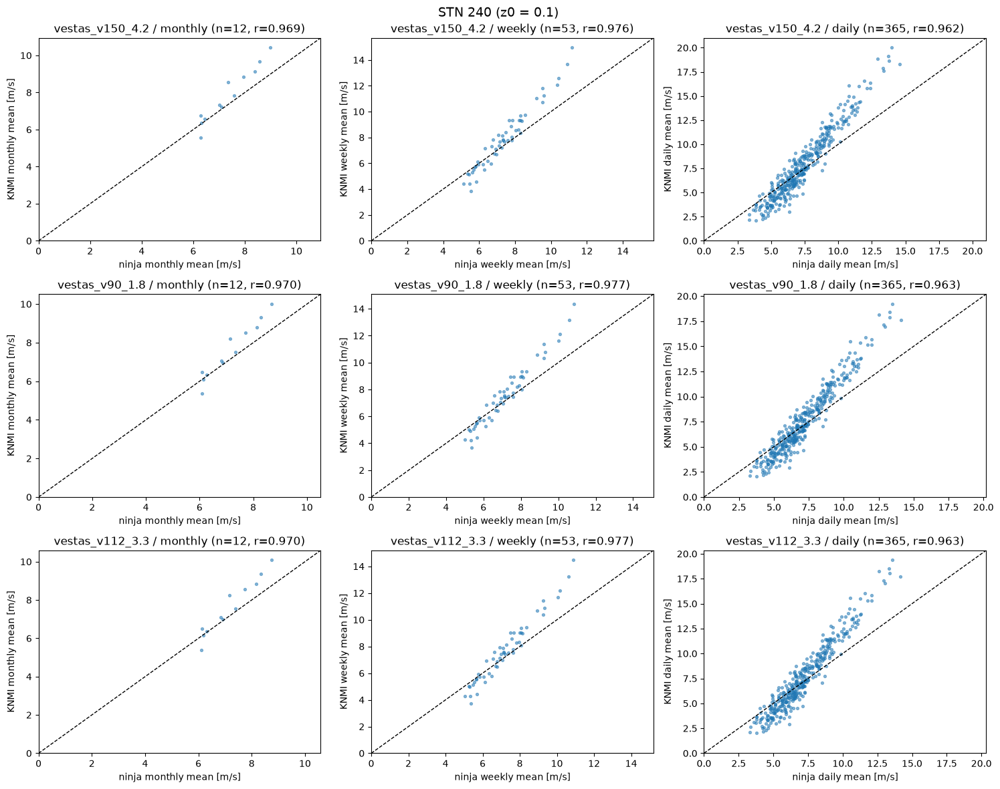

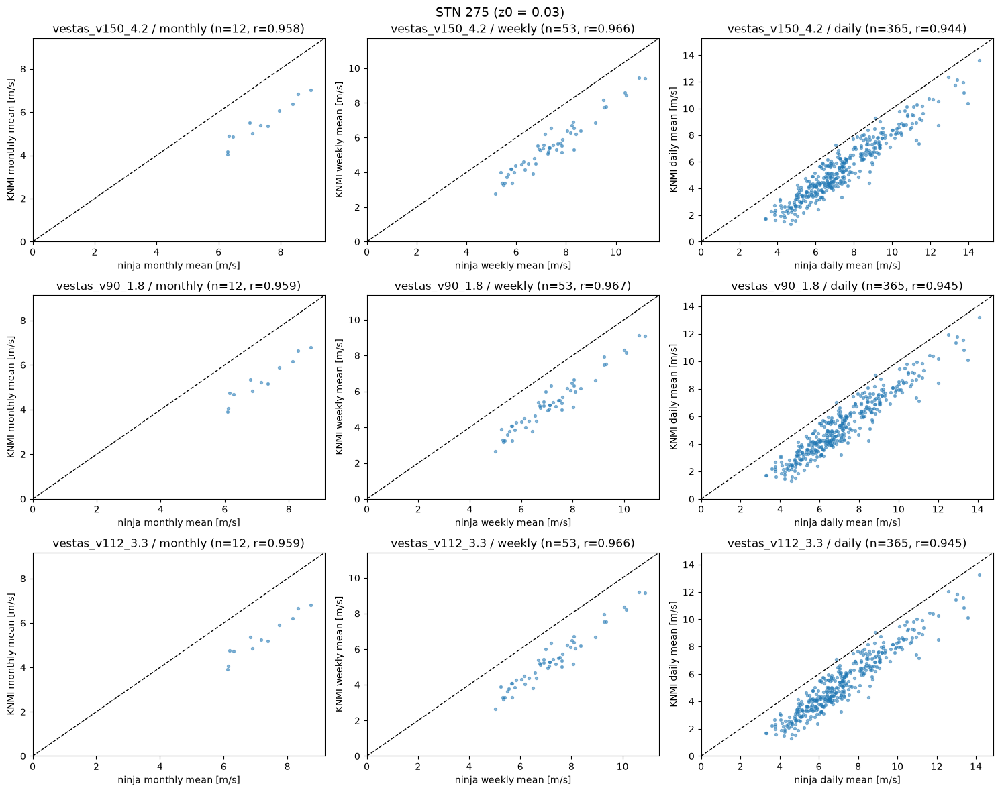

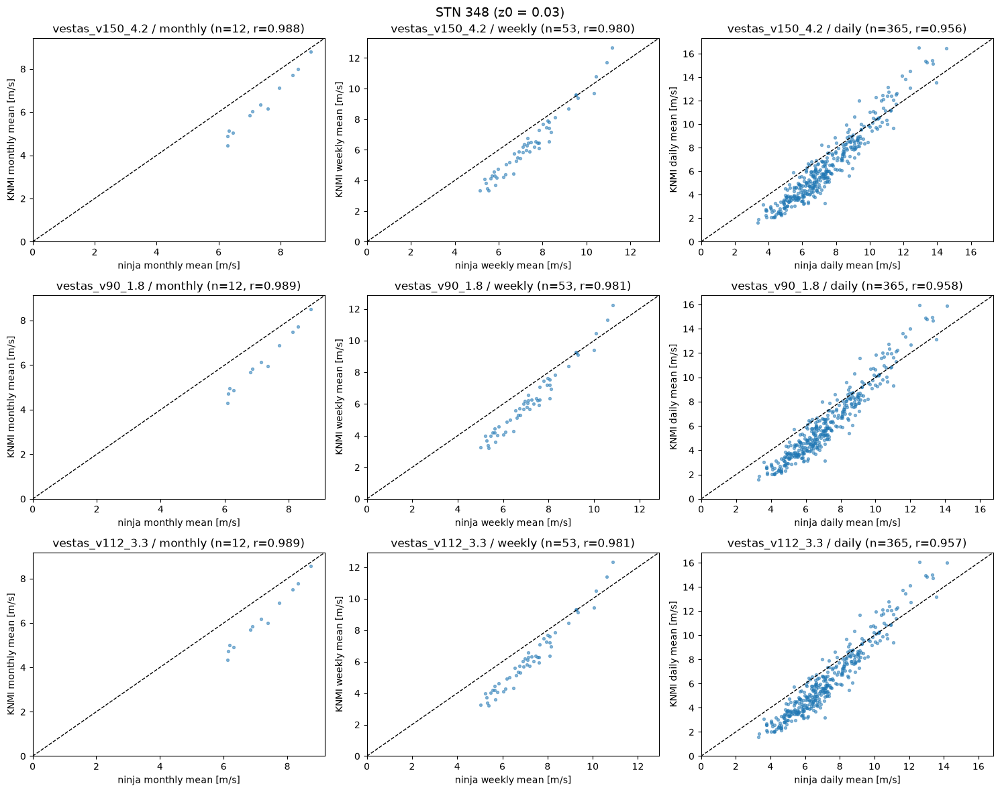

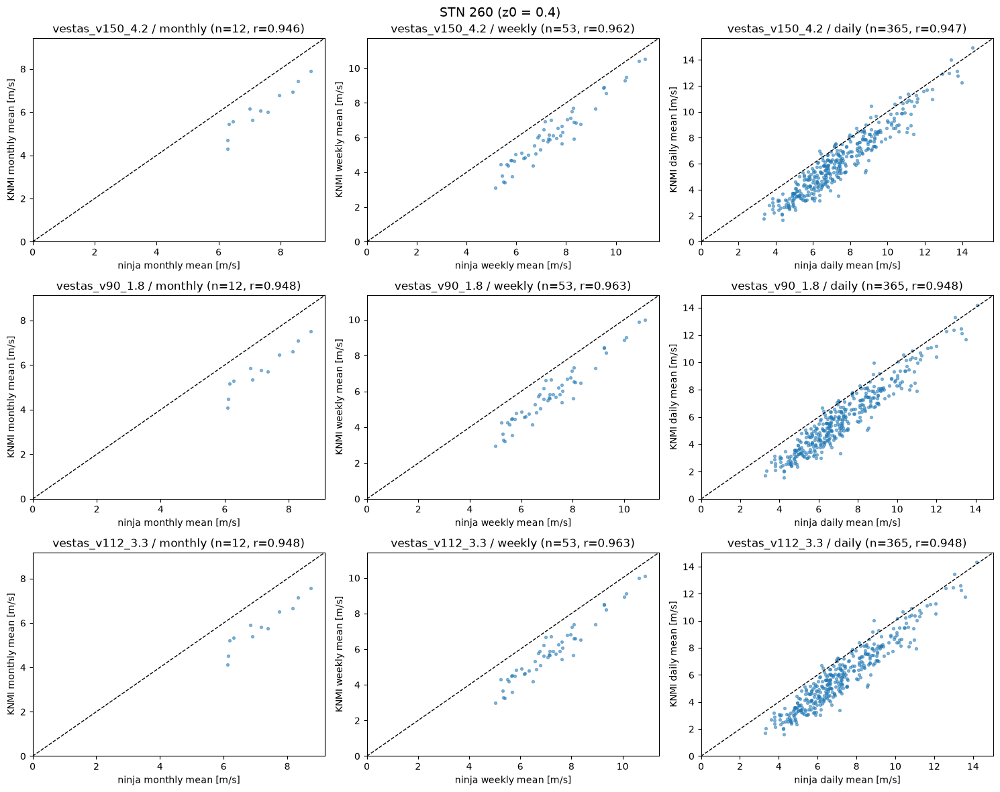

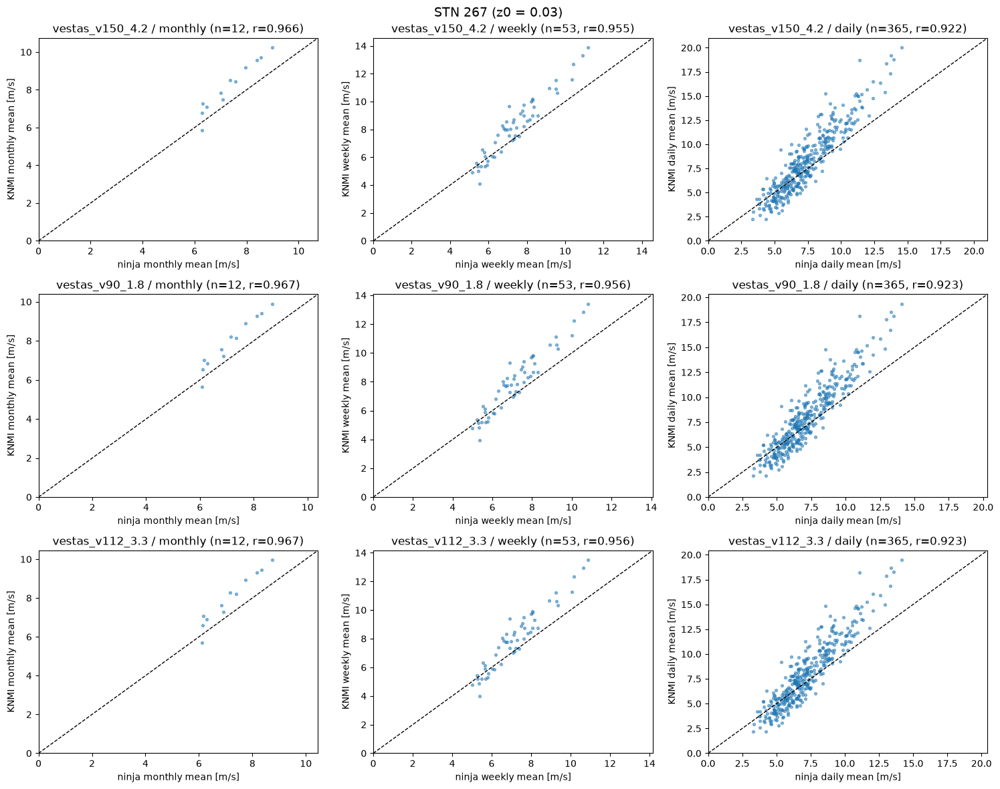

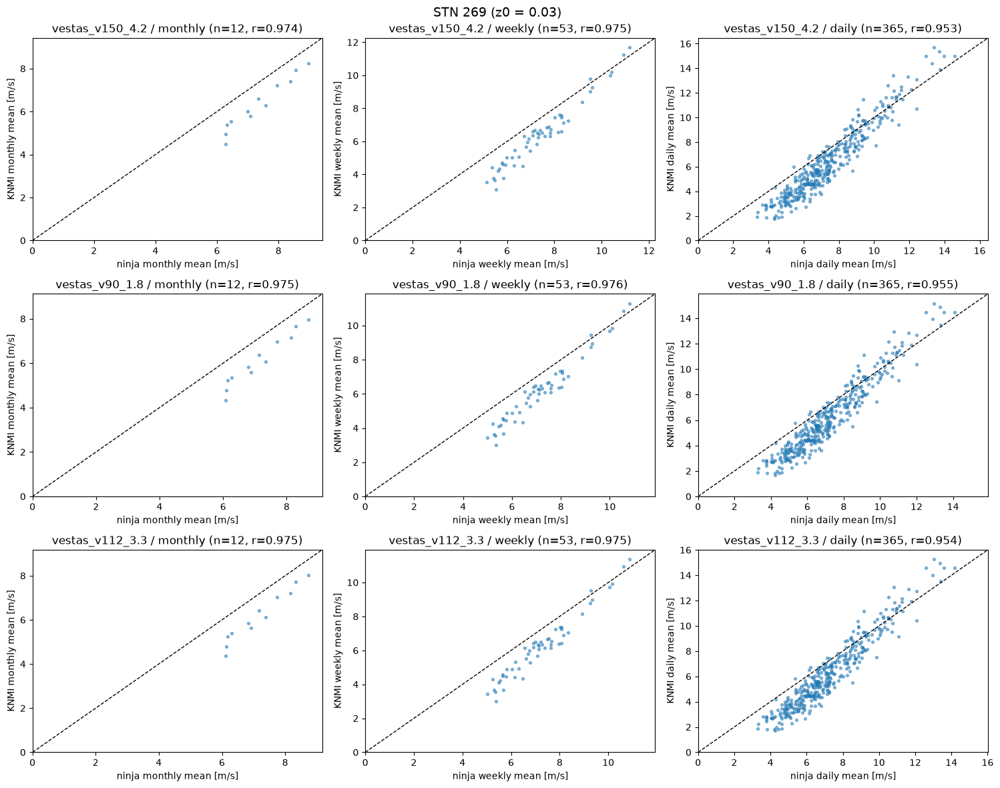

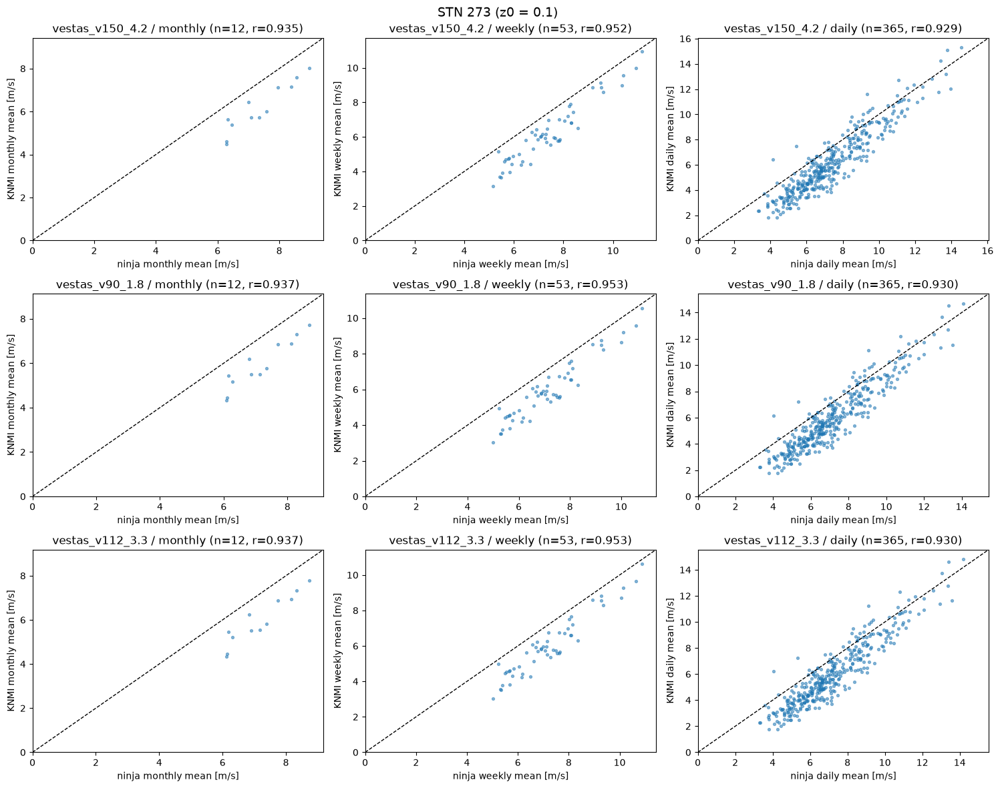

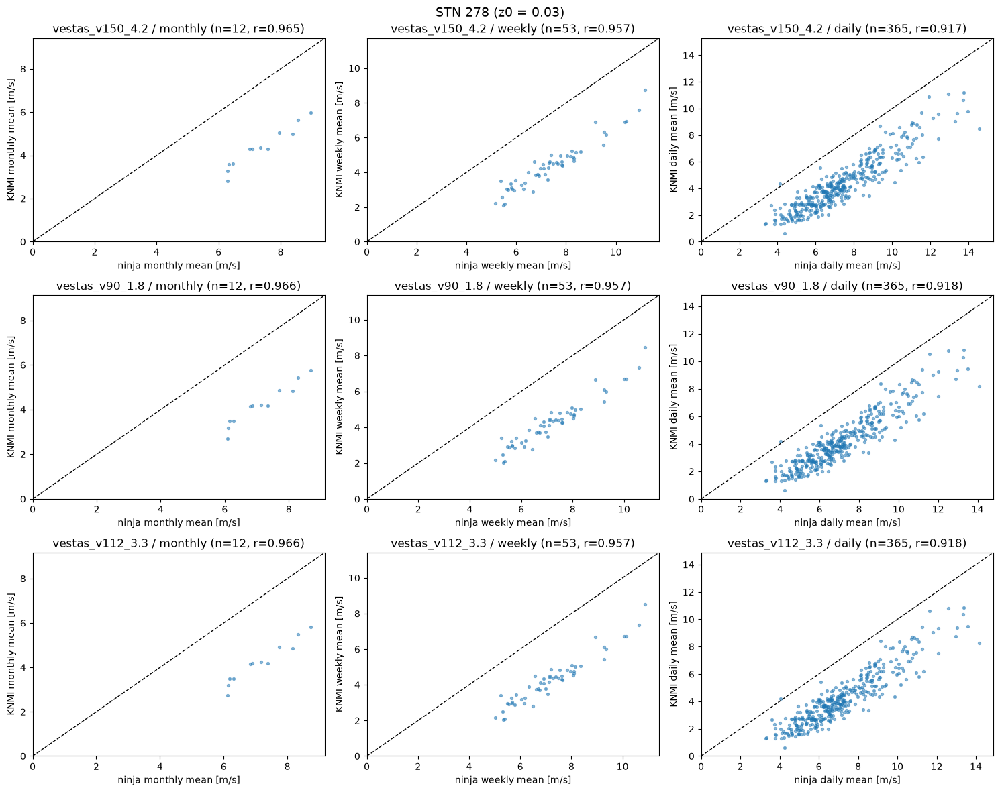

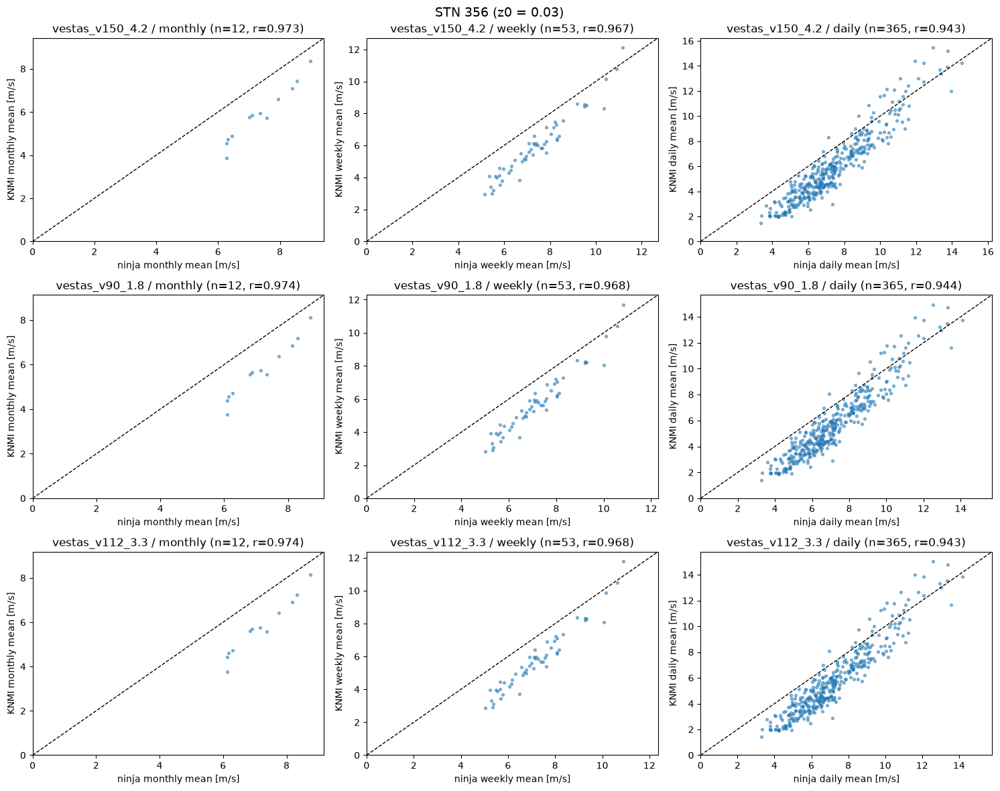

In [16]:
# Cell 6: monthly, weekly, daily wind speed correlation, all stations x all turbines
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RESOLUTIONS = [("monthly", "month"), ("weekly", "week"), ("daily", "day")]

# Pull ninja wind_speed once per turbine, then align per station
ninja_ws = {}
for name, path in NINJA_FILES.items():
    n = pd.read_csv(path, skiprows=3, parse_dates=["time"])[["time", "wind_speed"]]
    ninja_ws[name] = n.set_index("time")["wind_speed"]

results_ws = {}

for name in NINJA_FILES.keys():
    for stn, df in knmi.items():
        m = df[["time", f"ws_hub_{name}"]].rename(columns={f"ws_hub_{name}": "knmi"})
        m["ninja"] = m["time"].map(ninja_ws[name]).to_numpy(dtype=float)
        m = m.dropna(subset=["knmi", "ninja"])
        m["month"] = m["time"].dt.to_period("M").astype(str)
        m["week"]  = m["time"].dt.to_period("W-SUN").astype(str)
        m["day"]   = m["time"].dt.normalize()

        for label, key in RESOLUTIONS:
            g = m.groupby(key)[["knmi", "ninja"]].mean().reset_index()
            r = g["knmi"].corr(g["ninja"]) if len(g) > 1 else float("nan")
            results_ws[(stn, name, label)] = (g, r)

        print(f"STN {stn} / {name}:")
        for label, _ in RESOLUTIONS:
            g, r = results_ws[(stn, name, label)]
            print(f"  {label:>8s}: n={len(g):4d}  r={r:.4f}")

# One figure per station; rows = turbines, cols = monthly / weekly / daily
names = list(NINJA_FILES.keys())

for stn in knmi.keys():
    fig, axes = plt.subplots(len(names), len(RESOLUTIONS),
                             figsize=(15, 4 * len(names)), squeeze=False)
    fig.suptitle(f"STN {stn} (z0 = {Z0_BY_STATION[stn]})", fontsize=14)

    for row, name in enumerate(names):
        for col, (label, _) in enumerate(RESOLUTIONS):
            g, r = results_ws[(stn, name, label)]
            ax = axes[row, col]
            ax.scatter(g["ninja"], g["knmi"], s=8, alpha=0.5)
            lim = [0, max(g["ninja"].max(), g["knmi"].max()) * 1.05]
            ax.plot(lim, lim, "k--", lw=1)
            ax.set_xlim(lim); ax.set_ylim(lim)
            ax.set_xlabel(f"ninja {label} mean [m/s]")
            ax.set_ylabel(f"KNMI {label} mean [m/s]")
            ax.set_title(f"{name} / {label} (n={len(g)}, r={r:.3f})")

    plt.tight_layout()
    plt.show()

STN 240 / vestas_v150_4.2:
   monthly: n=  12  r=0.9455
    weekly: n=  53  r=0.9604
     daily: n= 365  r=0.9325
STN 275 / vestas_v150_4.2:
   monthly: n=  12  r=0.9585
    weekly: n=  53  r=0.9636
     daily: n= 365  r=0.9240
STN 348 / vestas_v150_4.2:
   monthly: n=  12  r=0.9818
    weekly: n=  53  r=0.9715
     daily: n= 365  r=0.9344
STN 260 / vestas_v150_4.2:
   monthly: n=  12  r=0.9540
    weekly: n=  53  r=0.9570
     daily: n= 365  r=0.9294
STN 267 / vestas_v150_4.2:
   monthly: n=  12  r=0.9147
    weekly: n=  53  r=0.9222
     daily: n= 365  r=0.8839
STN 269 / vestas_v150_4.2:
   monthly: n=  12  r=0.9828
    weekly: n=  53  r=0.9704
     daily: n= 365  r=0.9355
STN 273 / vestas_v150_4.2:
   monthly: n=  12  r=0.9347
    weekly: n=  53  r=0.9471
     daily: n= 365  r=0.9076
STN 278 / vestas_v150_4.2:
   monthly: n=  12  r=0.9556
    weekly: n=  53  r=0.9208
     daily: n= 365  r=0.8399
STN 356 / vestas_v150_4.2:
   monthly: n=  12  r=0.9740
    weekly: n=  53  r=0.9588
   

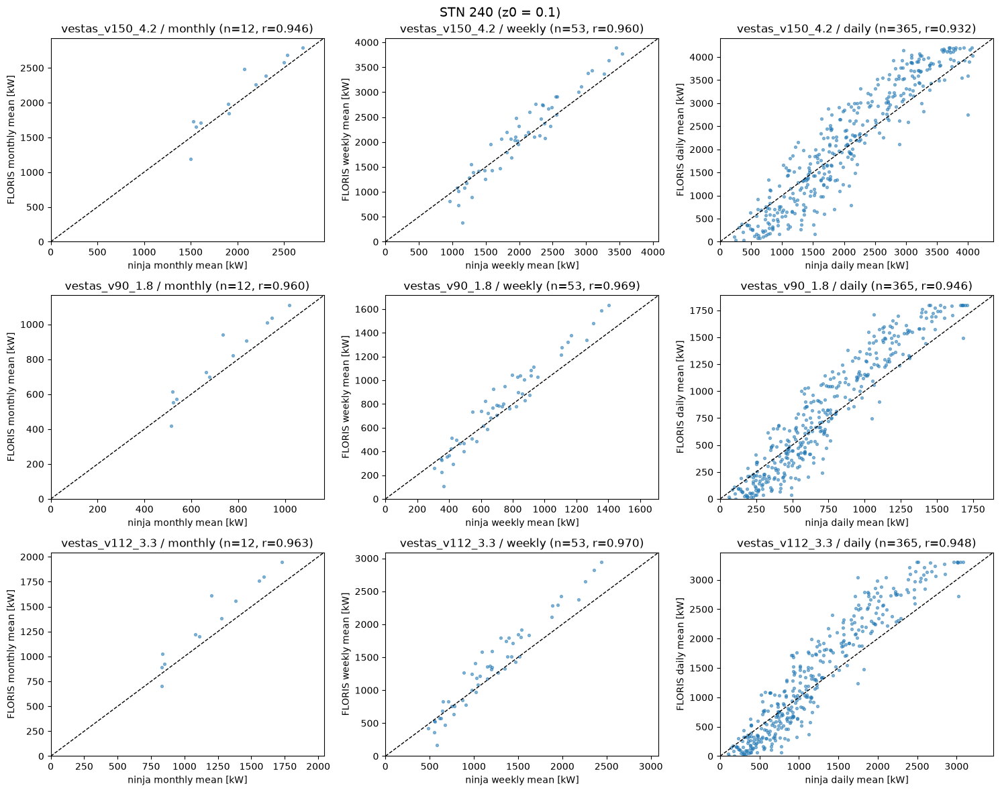

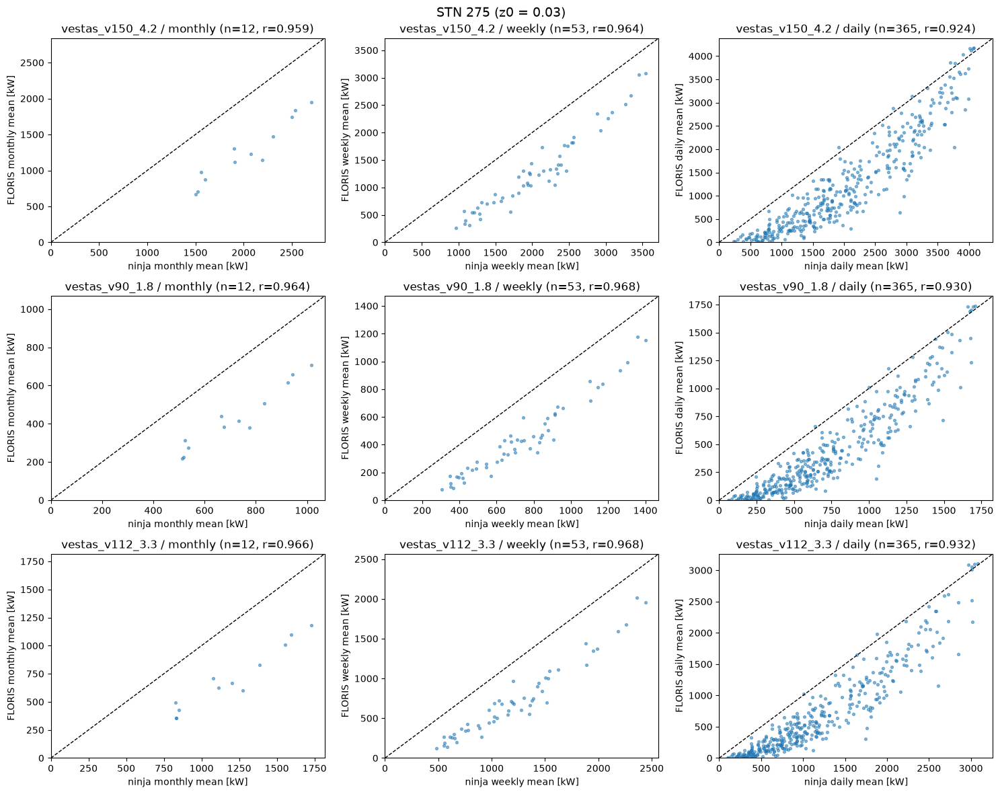

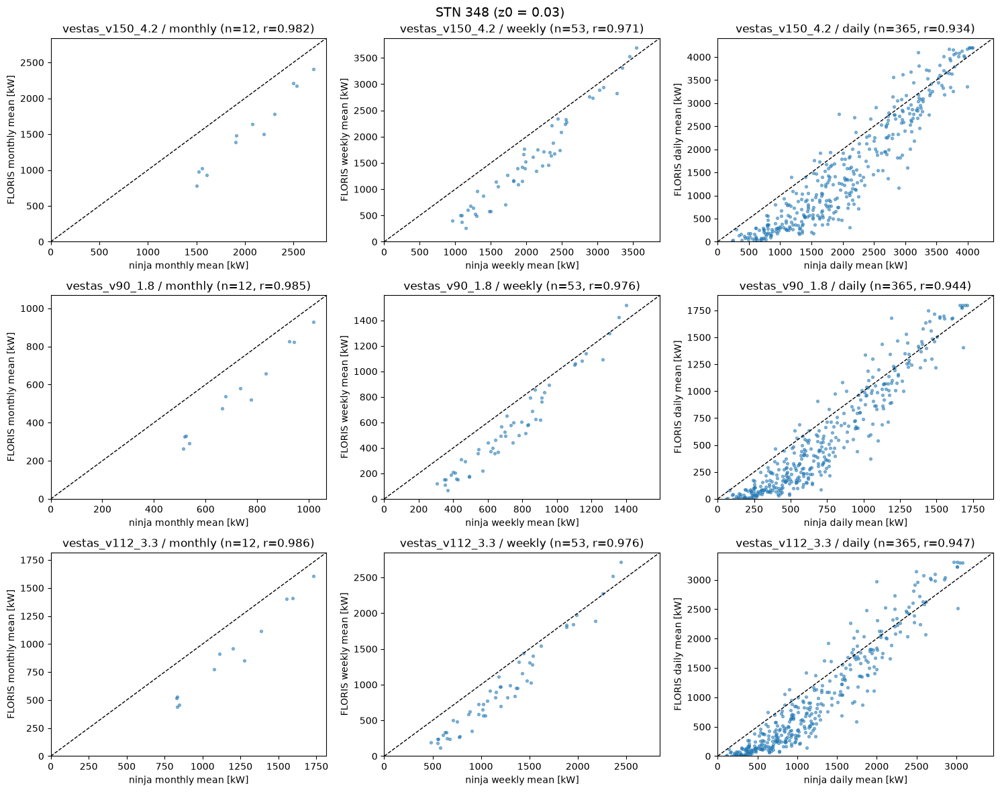

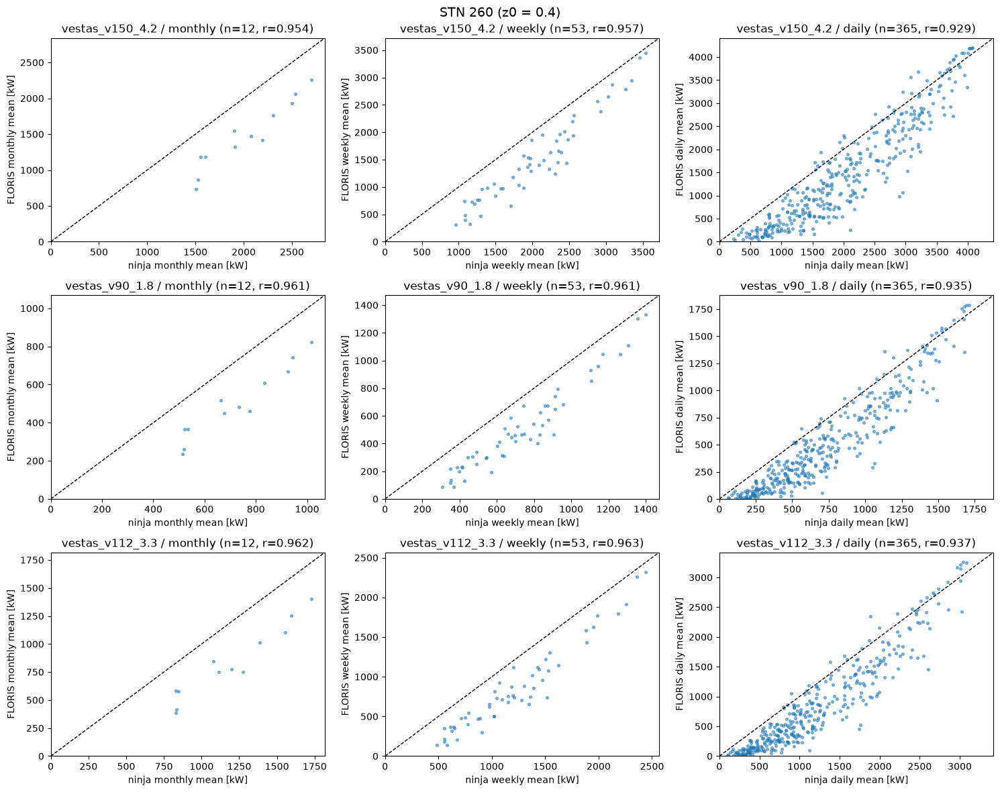

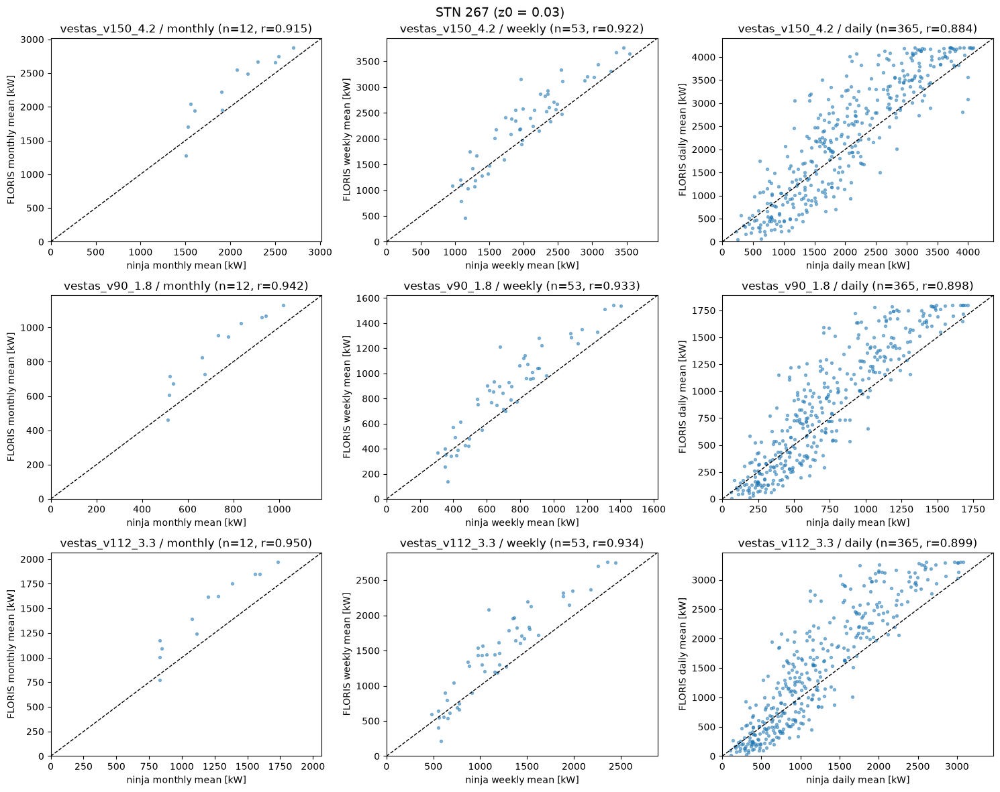

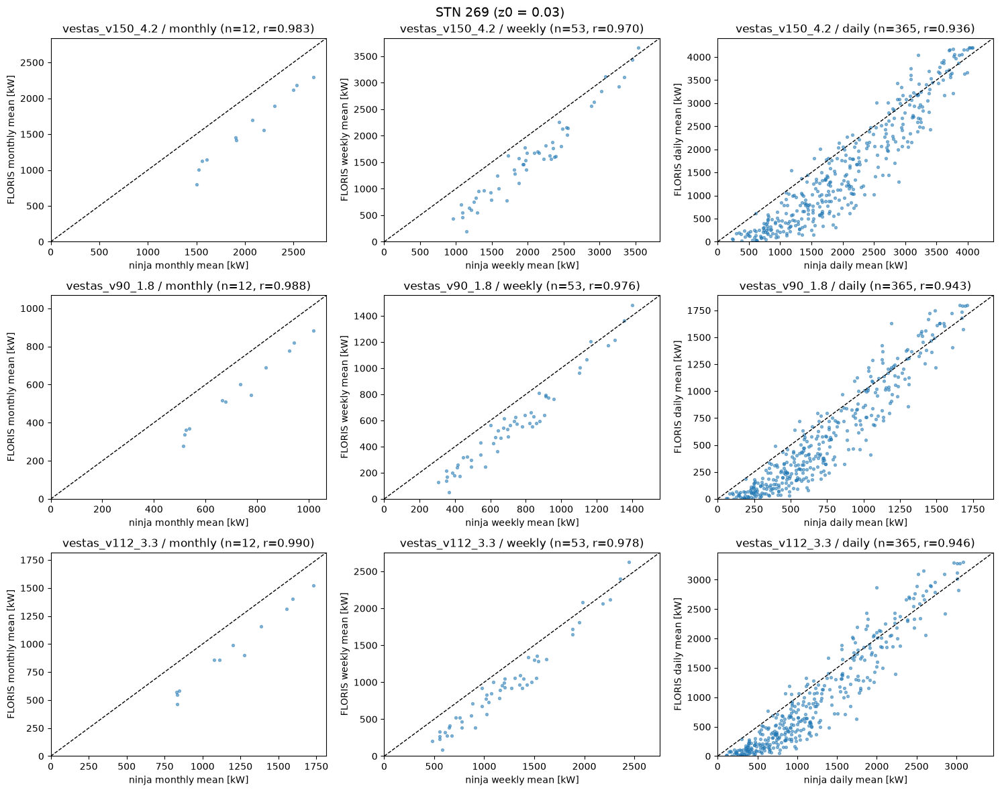

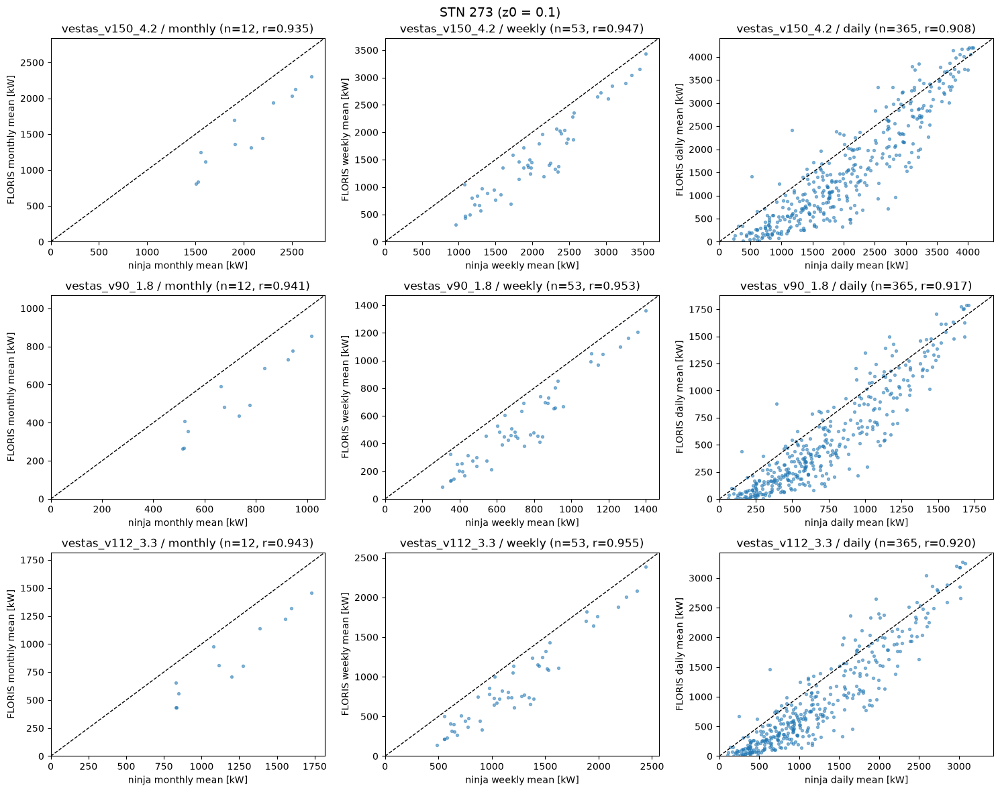

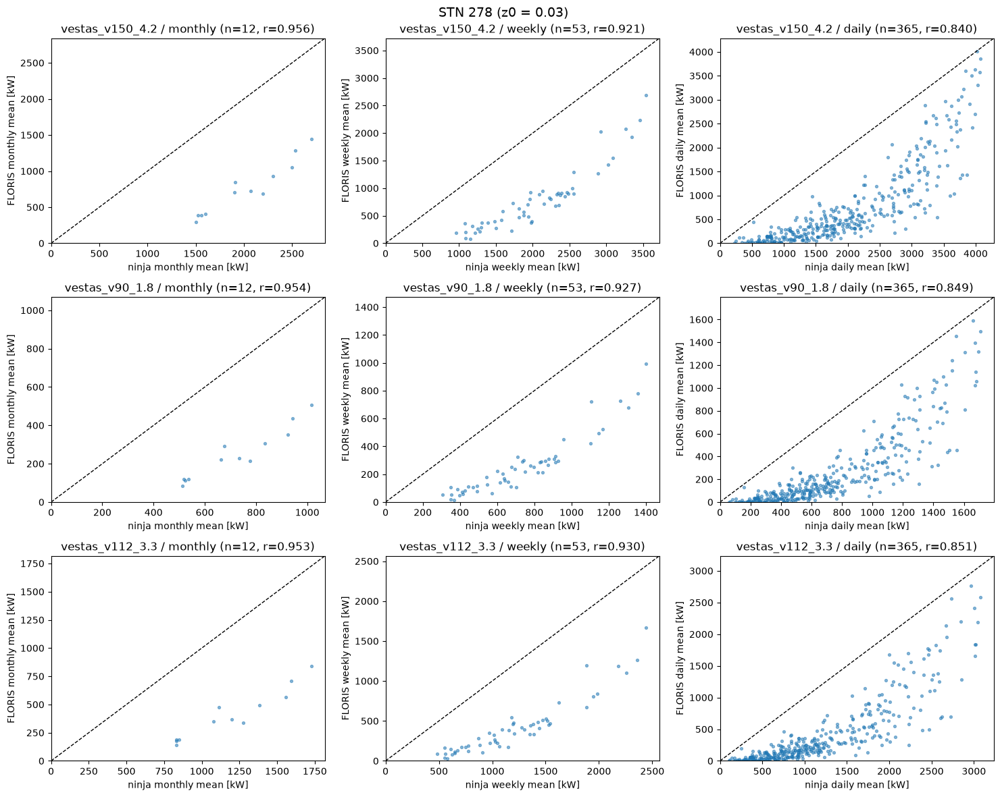

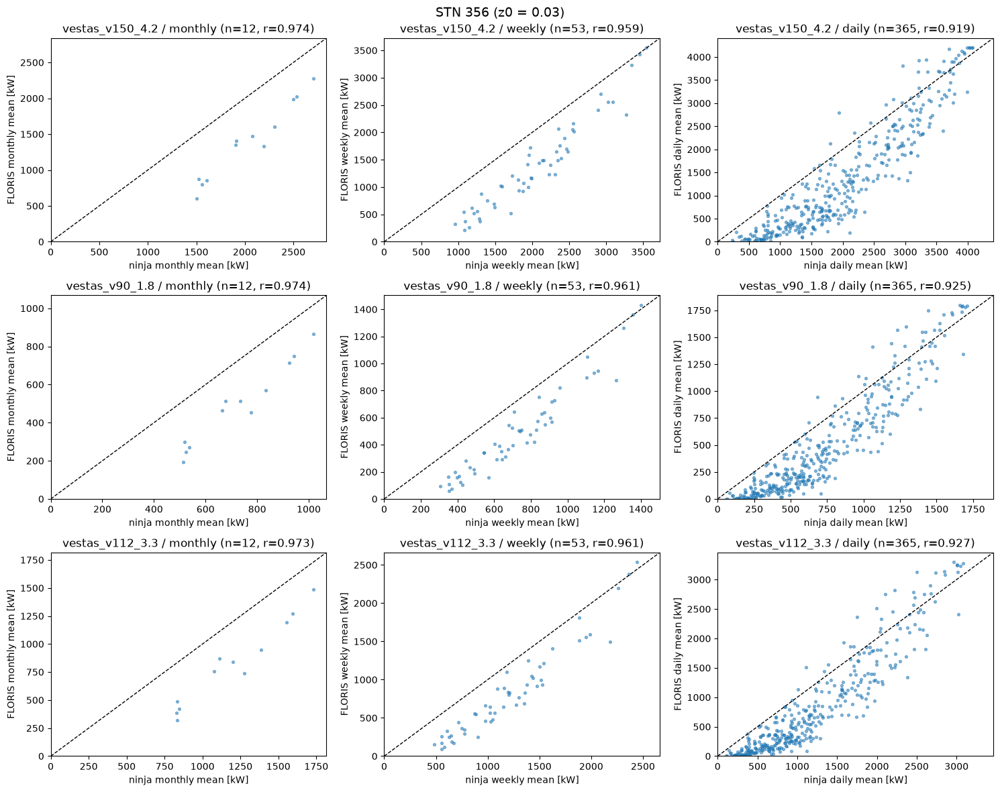

In [17]:
# Cell 7: monthly, weekly, daily FLORIS vs ninja power correlation, all stations x all turbines
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RESOLUTIONS = [("monthly", "month"), ("weekly", "week"), ("daily", "day")]

results_pw = {}

for (stn, name), r in floris_results_knmi.items():
    df = pd.DataFrame({
        "time": pd.to_datetime(r["time"]),
        "floris_kw": r["floris_kw"],
        "ninja_kw": r["ninja_kw"],
    }).dropna(subset=["floris_kw", "ninja_kw"])

    df["month"] = df["time"].dt.to_period("M").astype(str)
    df["week"]  = df["time"].dt.to_period("W-SUN").astype(str)
    df["day"]   = df["time"].dt.normalize()

    for label, key in RESOLUTIONS:
        g = df.groupby(key)[["floris_kw", "ninja_kw"]].mean().reset_index()
        r_ = g["floris_kw"].corr(g["ninja_kw"]) if len(g) > 1 else float("nan")
        results_pw[(stn, name, label)] = (g, r_)

    print(f"STN {stn} / {name}:")
    for label, _ in RESOLUTIONS:
        g, r_ = results_pw[(stn, name, label)]
        print(f"  {label:>8s}: n={len(g):4d}  r={r_:.4f}")

names = list(NINJA_FILES.keys())

for stn in knmi.keys():
    fig, axes = plt.subplots(len(names), len(RESOLUTIONS),
                             figsize=(15, 4 * len(names)), squeeze=False)
    fig.suptitle(f"STN {stn} (z0 = {Z0_BY_STATION[stn]})", fontsize=14)

    for row, name in enumerate(names):
        for col, (label, _) in enumerate(RESOLUTIONS):
            g, r_ = results_pw[(stn, name, label)]
            ax = axes[row, col]
            ax.scatter(g["ninja_kw"], g["floris_kw"], s=8, alpha=0.5)
            lim = [0, max(g["ninja_kw"].max(), g["floris_kw"].max()) * 1.05]
            ax.plot(lim, lim, "k--", lw=1)
            ax.set_xlim(lim); ax.set_ylim(lim)
            ax.set_xlabel(f"ninja {label} mean [kW]")
            ax.set_ylabel(f"FLORIS {label} mean [kW]")
            ax.set_title(f"{name} / {label} (n={len(g)}, r={r_:.3f})")

    plt.tight_layout()
    plt.show()

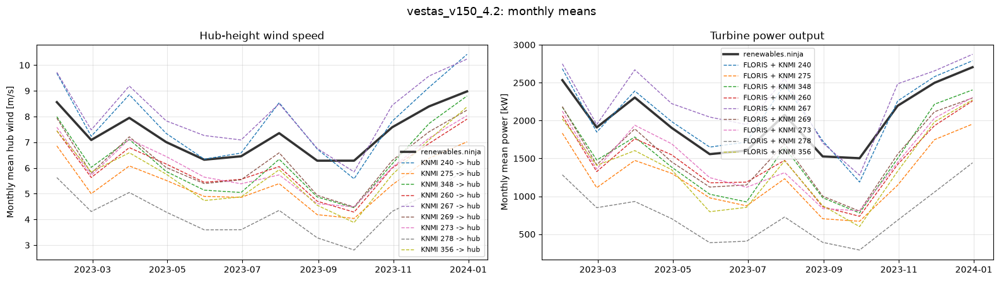

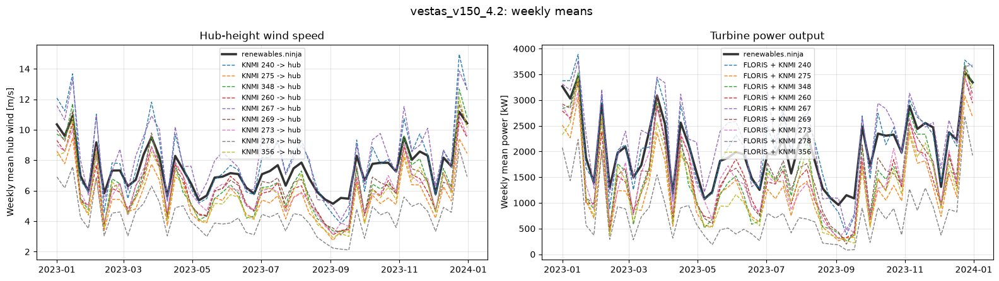

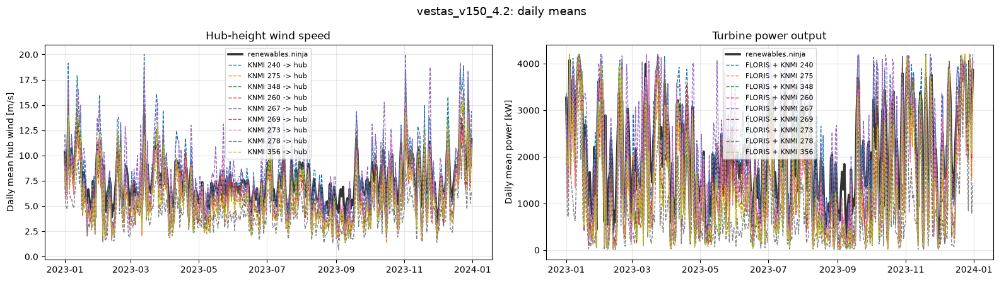

In [18]:
# Cell 8: monthly/weekly/daily mean time series, V150 shown for all stations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

TURBINE_SHOWN = "vestas_v150_4.2"

RESOLUTIONS = [("Monthly", "month"), ("Weekly", "week"), ("Daily", "day")]
RES_KEYS = {"month": "ME", "week": "W-SUN", "day": "D"}

# ninja wind speed per turbine (no station dependence)
ninja_ws_by_turbine = {}
for name, path in NINJA_FILES.items():
    n = pd.read_csv(path, skiprows=3, parse_dates=["time"])[["time", "wind_speed"]]
    ninja_ws_by_turbine[name] = n.rename(columns={"wind_speed": "ninja_ws"})

series_ws = {}
series_pw = {}

for name in NINJA_FILES.keys():
    ninja_ws_df = ninja_ws_by_turbine[name]

    for stn, df in knmi.items():
        m = df[["time", f"ws_hub_{name}"]].rename(columns={f"ws_hub_{name}": "knmi_ws"})
        m = m.merge(ninja_ws_df, on="time", how="inner")

        r = floris_results_knmi[(stn, name)]
        pw = pd.DataFrame({
            "time": pd.to_datetime(r["time"]),
            "floris_kw": r["floris_kw"],
            "ninja_kw": r["ninja_kw"],
        })
        m = m.merge(pw, on="time", how="left")

        for label, key in RESOLUTIONS:
            k = pd.Grouper(key="time", freq=RES_KEYS[key])
            series_ws[(stn, name, label)] = (
                m.groupby(k)[["knmi_ws", "ninja_ws"]].mean().reset_index()
            )
            series_pw[(stn, name, label)] = (
                m.groupby(k)[["floris_kw", "ninja_kw"]].mean().reset_index()
            )

# Plot: one figure per resolution, cols = wind speed / power, lines = station
stns = list(knmi.keys())

for label, _ in RESOLUTIONS:
    fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), sharex=True)
    fig.suptitle(f"{TURBINE_SHOWN}: {label.lower()} means", fontsize=13)

    # Plot renewables.ninja ONCE outside the station loop
    first_stn = stns[0]
    ws_ninja = series_ws[(first_stn, TURBINE_SHOWN, label)]
    pw_ninja = series_pw[(first_stn, TURBINE_SHOWN, label)]
    
    # 2x thickness (lw=2.6) and squares ('s') as point indicators
    axes[0].plot(ws_ninja["time"], ws_ninja["ninja_ws"], lw=2.6, ls="-", ms=5,
                 color="k", alpha=0.8, label="renewables.ninja")
    axes[1].plot(pw_ninja["time"], pw_ninja["ninja_kw"], lw=2.6, ls="-", ms=5,
                 color="k", alpha=0.8, label="renewables.ninja")

    # Plot each station's KNMI / FLORIS output
    for stn in stns:
        ws = series_ws[(stn, TURBINE_SHOWN, label)]
        pw = series_pw[(stn, TURBINE_SHOWN, label)]

        axes[0].plot(ws["time"], ws["knmi_ws"], lw=1.0, ls="--",
                     label=f"KNMI {stn} -> hub")

        axes[1].plot(pw["time"], pw["floris_kw"], lw=1.0, ls="--",
                     label=f"FLORIS + KNMI {stn}")

    axes[0].set_ylabel(f"{label} mean hub wind [m/s]")
    axes[0].set_title("Hub-height wind speed")
    axes[0].legend(fontsize=8); axes[0].grid(True, alpha=0.3)

    axes[1].set_ylabel(f"{label} mean power [kW]")
    axes[1].set_title("Turbine power output")
    axes[1].legend(fontsize=8); axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

STN 240 / vestas_v150_4.2  (z0=0.1)
hours            8760
hours above cut-in 8651
  KNMI hub  mean  7.868  median  7.553  std 4.291  min 0.000  max 30.212  p05  1.51  p95 16.62
     ninja  mean  7.360  median  7.159  std 2.422  min 1.832  max 18.774  p05  3.74  p95 11.89

ERRORS (KNMI - ninja)
mean bias     +0.508 m/s
median bias   +0.389 m/s
MAE           2.036 m/s
RMSE          2.560 m/s
RMSE >= 3 m/s 2.572 m/s
max |err|     14.920 m/s
within ±1 m/s  30.1 %
within ±2 m/s  57.2 %
within ±3 m/s  76.5 %

AGREEMENT
Pearson r     +0.8652   (p=0)
Spearman rho  +0.8252
OLS: KNMI = 1.533 * ninja -3.417
mean ratio    1.069


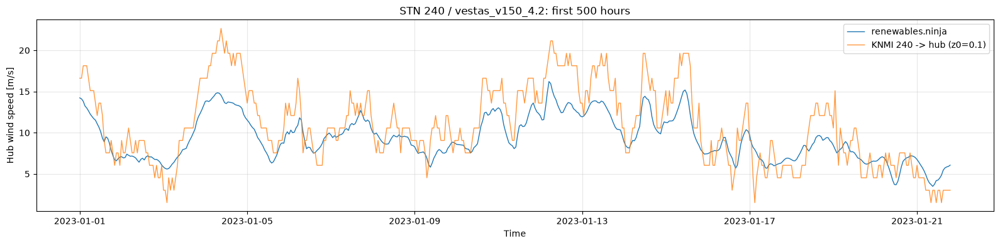

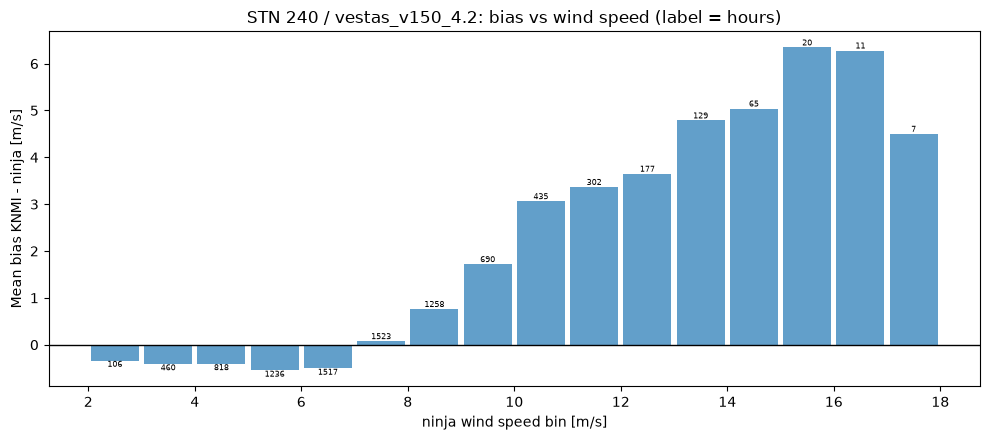

STN 275 / vestas_v150_4.2  (z0=0.03)
hours            8760
hours above cut-in 8651
  KNMI hub  mean  5.470  median  5.619  std 2.980  min 0.000  max 18.262  p05  1.40  p95 11.24
     ninja  mean  7.360  median  7.159  std 2.422  min 1.832  max 18.774  p05  3.74  p95 11.89

ERRORS (KNMI - ninja)
mean bias     -1.891 m/s
median bias   -1.805 m/s
MAE           2.138 m/s
RMSE          2.626 m/s
RMSE >= 3 m/s 2.638 m/s
max |err|     10.011 m/s
within ±1 m/s  27.8 %
within ±2 m/s  53.4 %
within ±3 m/s  72.8 %

AGREEMENT
Pearson r     +0.7915   (p=0)
Spearman rho  +0.7531
OLS: KNMI = 0.974 * ninja -1.700
mean ratio    0.743


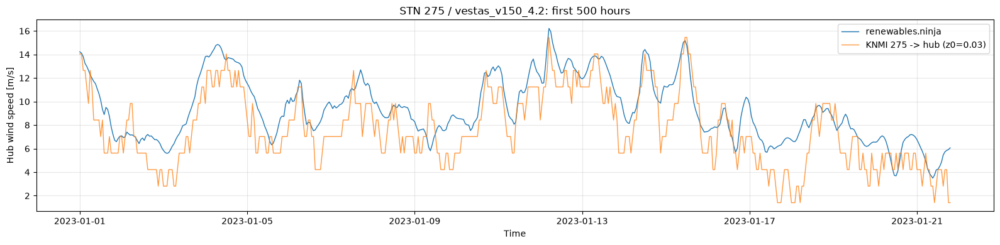

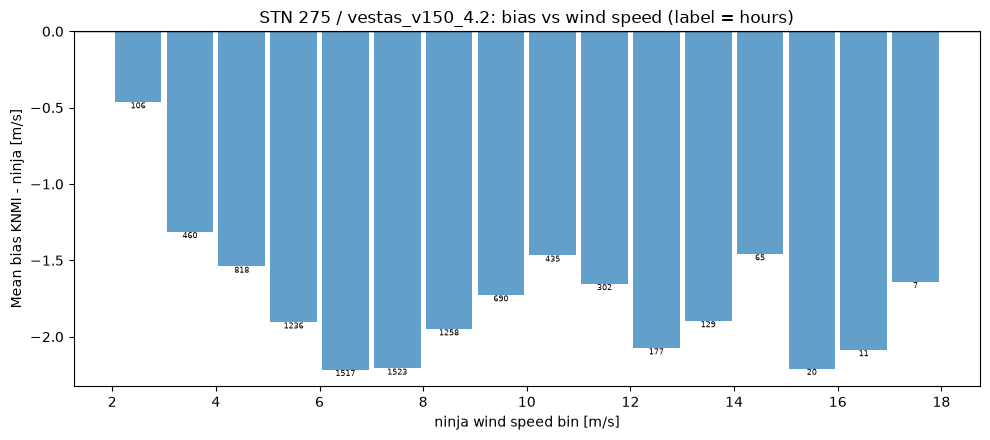

STN 348 / vestas_v150_4.2  (z0=0.03)
hours            8760
hours above cut-in 8651
  KNMI hub  mean  6.302  median  5.619  std 3.599  min 0.000  max 21.072  p05  1.40  p95 14.05
     ninja  mean  7.360  median  7.159  std 2.422  min 1.832  max 18.774  p05  3.74  p95 11.89

ERRORS (KNMI - ninja)
mean bias     -1.058 m/s
median bias   -1.132 m/s
MAE           1.838 m/s
RMSE          2.261 m/s
RMSE >= 3 m/s 2.271 m/s
max |err|     7.296 m/s
within ±1 m/s  32.2 %
within ±2 m/s  60.3 %
within ±3 m/s  80.2 %

AGREEMENT
Pearson r     +0.8506   (p=0)
Spearman rho  +0.7977
OLS: KNMI = 1.264 * ninja -3.004
mean ratio    0.856


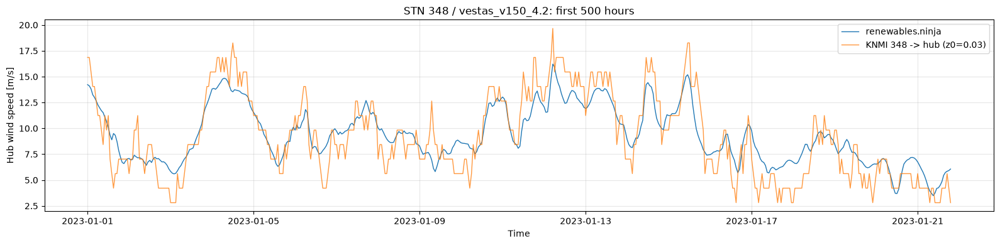

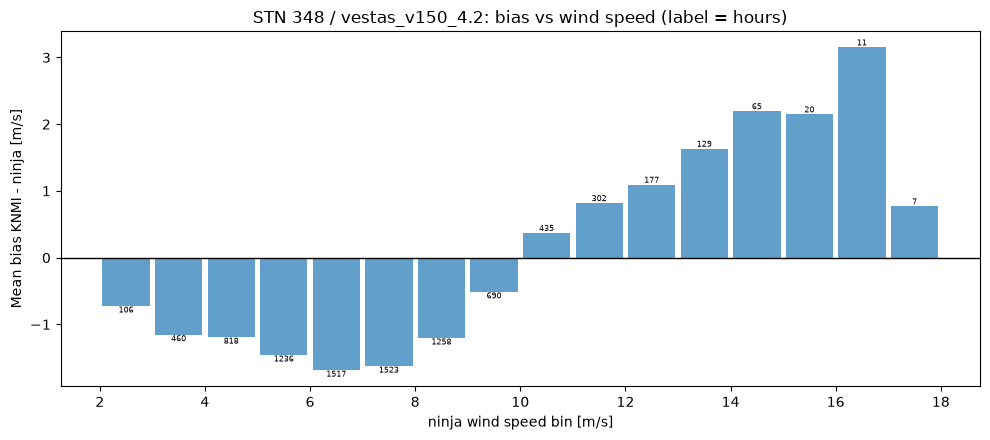

STN 260 / vestas_v150_4.2  (z0=0.4)
hours            8760
hours above cut-in 8651
  KNMI hub  mean  6.084  median  5.191  std 3.088  min 0.000  max 19.035  p05  1.73  p95 12.11
     ninja  mean  7.360  median  7.159  std 2.422  min 1.832  max 18.774  p05  3.74  p95 11.89

ERRORS (KNMI - ninja)
mean bias     -1.276 m/s
median bias   -1.262 m/s
MAE           1.787 m/s
RMSE          2.213 m/s
RMSE >= 3 m/s 2.222 m/s
max |err|     8.026 m/s
within ±1 m/s  34.1 %
within ±2 m/s  62.1 %
within ±3 m/s  80.9 %

AGREEMENT
Pearson r     +0.8112   (p=0)
Spearman rho  +0.7669
OLS: KNMI = 1.035 * ninja -1.531
mean ratio    0.827


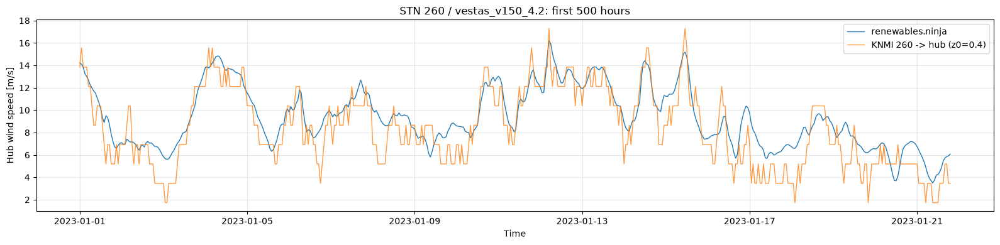

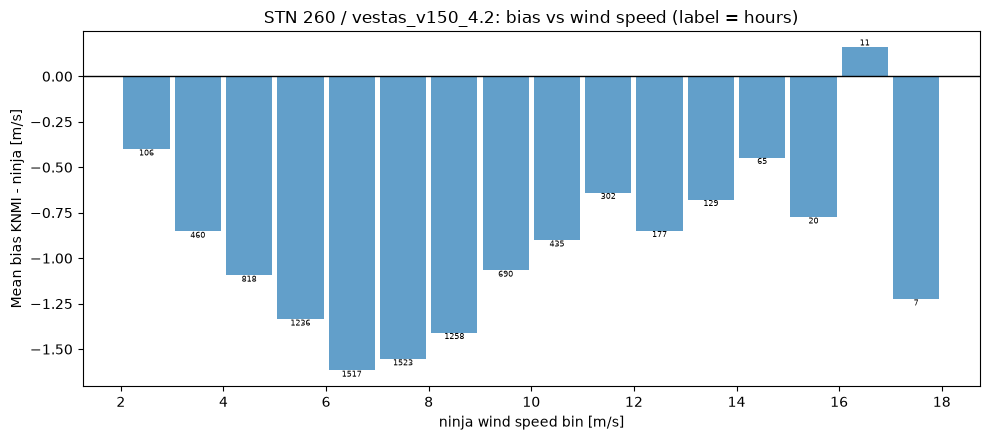

STN 267 / vestas_v150_4.2  (z0=0.03)
hours            8760
hours above cut-in 8651
  KNMI hub  mean  8.173  median  7.024  std 4.058  min 0.000  max 26.691  p05  2.81  p95 15.45
     ninja  mean  7.360  median  7.159  std 2.422  min 1.832  max 18.774  p05  3.74  p95 11.89

ERRORS (KNMI - ninja)
mean bias     +0.812 m/s
median bias   +0.683 m/s
MAE           2.002 m/s
RMSE          2.550 m/s
RMSE >= 3 m/s 2.561 m/s
max |err|     11.399 m/s
within ±1 m/s  31.1 %
within ±2 m/s  58.3 %
within ±3 m/s  77.4 %

AGREEMENT
Pearson r     +0.8390   (p=0)
Spearman rho  +0.8073
OLS: KNMI = 1.406 * ninja -2.174
mean ratio    1.110


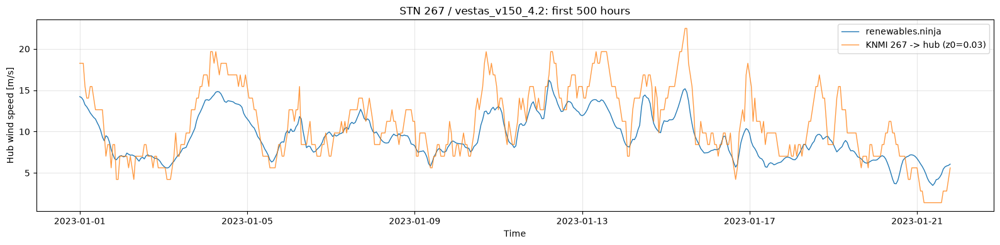

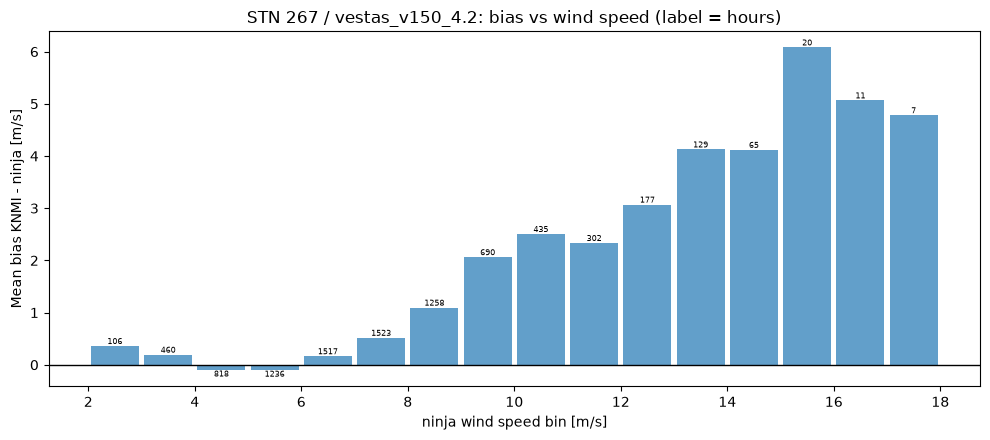

STN 269 / vestas_v150_4.2  (z0=0.03)
hours            8760
hours above cut-in 8651
  KNMI hub  mean  6.331  median  5.619  std 3.514  min 0.000  max 26.691  p05  1.40  p95 12.64
     ninja  mean  7.360  median  7.159  std 2.422  min 1.832  max 18.774  p05  3.74  p95 11.89

ERRORS (KNMI - ninja)
mean bias     -1.030 m/s
median bias   -1.063 m/s
MAE           1.804 m/s
RMSE          2.224 m/s
RMSE >= 3 m/s 2.234 m/s
max |err|     9.489 m/s
within ±1 m/s  33.2 %
within ±2 m/s  61.2 %
within ±3 m/s  81.2 %

AGREEMENT
Pearson r     +0.8417   (p=0)
Spearman rho  +0.7952
OLS: KNMI = 1.221 * ninja -2.659
mean ratio    0.860


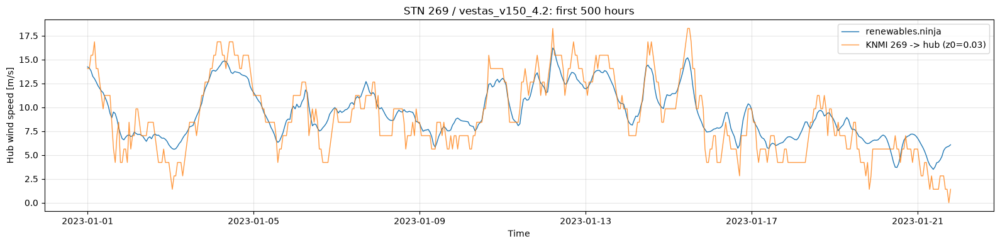

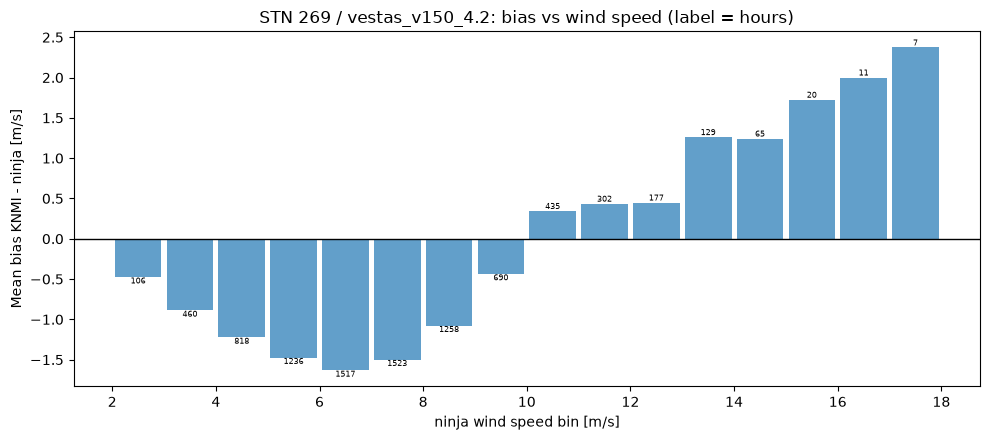

STN 273 / vestas_v150_4.2  (z0=0.1)
hours            8760
hours above cut-in 8651
  KNMI hub  mean  6.168  median  6.042  std 3.277  min 0.000  max 21.148  p05  1.51  p95 12.08
     ninja  mean  7.360  median  7.159  std 2.422  min 1.832  max 18.774  p05  3.74  p95 11.89

ERRORS (KNMI - ninja)
mean bias     -1.192 m/s
median bias   -1.177 m/s
MAE           1.896 m/s
RMSE          2.332 m/s
RMSE >= 3 m/s 2.342 m/s
max |err|     7.124 m/s
within ±1 m/s  31.9 %
within ±2 m/s  58.2 %
within ±3 m/s  78.3 %

AGREEMENT
Pearson r     +0.7930   (p=0)
Spearman rho  +0.7435
OLS: KNMI = 1.073 * ninja -1.731
mean ratio    0.838


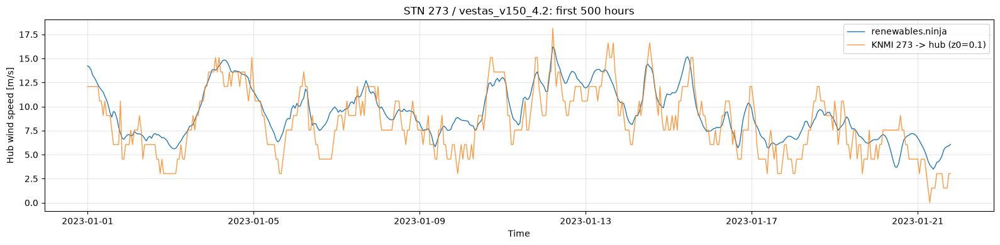

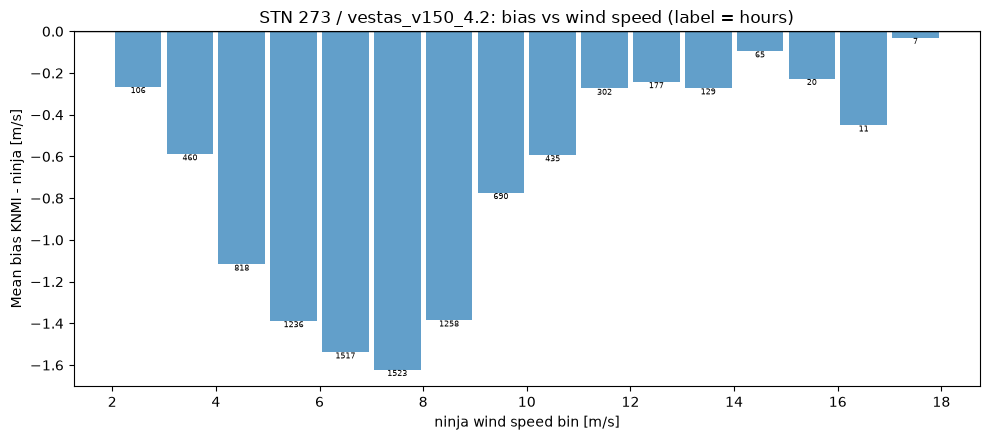

STN 278 / vestas_v150_4.2  (z0=0.03)
hours            8760
hours above cut-in 8651
  KNMI hub  mean  4.354  median  4.214  std 2.601  min 0.000  max 18.262  p05  1.40  p95  9.83
     ninja  mean  7.360  median  7.159  std 2.422  min 1.832  max 18.774  p05  3.74  p95 11.89

ERRORS (KNMI - ninja)
mean bias     -3.006 m/s
median bias   -2.970 m/s
MAE           3.044 m/s
RMSE          3.467 m/s
RMSE >= 3 m/s 3.485 m/s
max |err|     9.976 m/s
within ±1 m/s  12.1 %
within ±2 m/s  29.9 %
within ±3 m/s  50.8 %

AGREEMENT
Pearson r     +0.7657   (p=0)
Spearman rho  +0.7148
OLS: KNMI = 0.822 * ninja -1.698
mean ratio    0.592


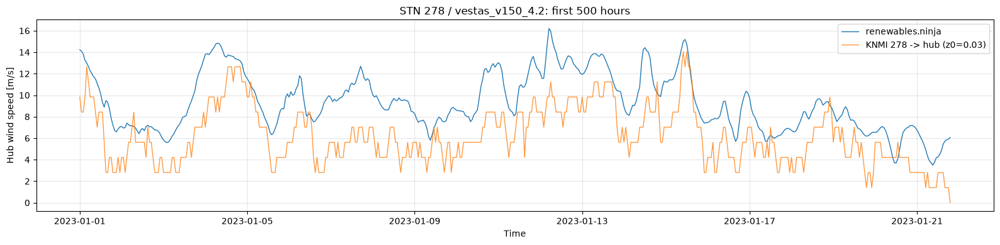

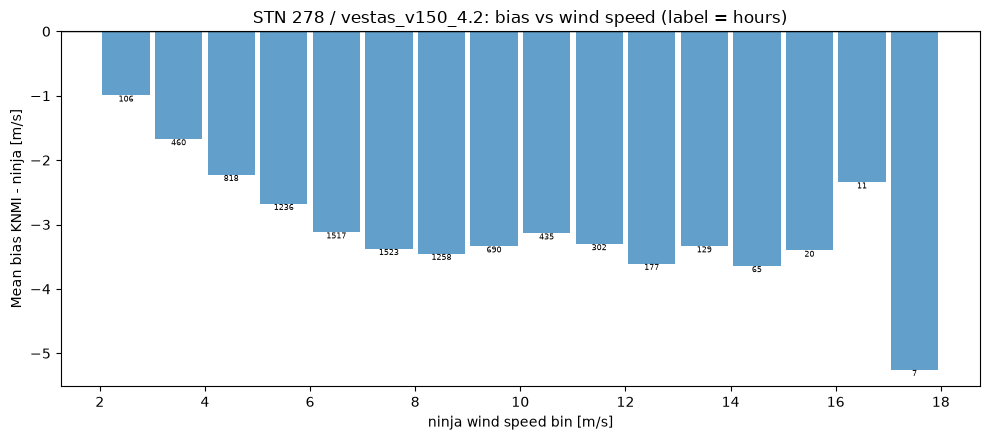

STN 356 / vestas_v150_4.2  (z0=0.03)
hours            8760
hours above cut-in 8651
  KNMI hub  mean  5.908  median  5.619  std 3.379  min 0.000  max 19.667  p05  1.40  p95 12.64
     ninja  mean  7.360  median  7.159  std 2.422  min 1.832  max 18.774  p05  3.74  p95 11.89

ERRORS (KNMI - ninja)
mean bias     -1.453 m/s
median bias   -1.552 m/s
MAE           2.000 m/s
RMSE          2.423 m/s
RMSE >= 3 m/s 2.434 m/s
max |err|     8.607 m/s
within ±1 m/s  28.8 %
within ±2 m/s  55.1 %
within ±3 m/s  76.3 %

AGREEMENT
Pearson r     +0.8262   (p=0)
Spearman rho  +0.7761
OLS: KNMI = 1.153 * ninja -2.578
mean ratio    0.803


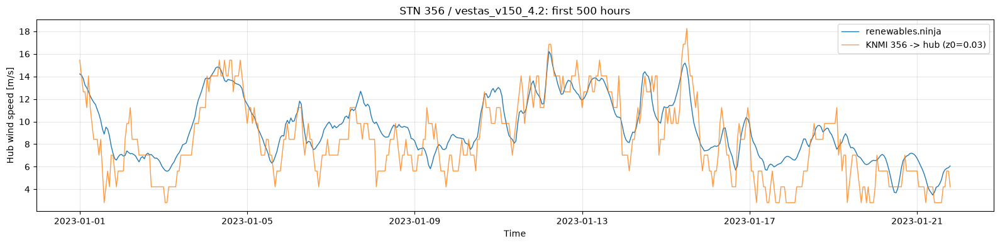

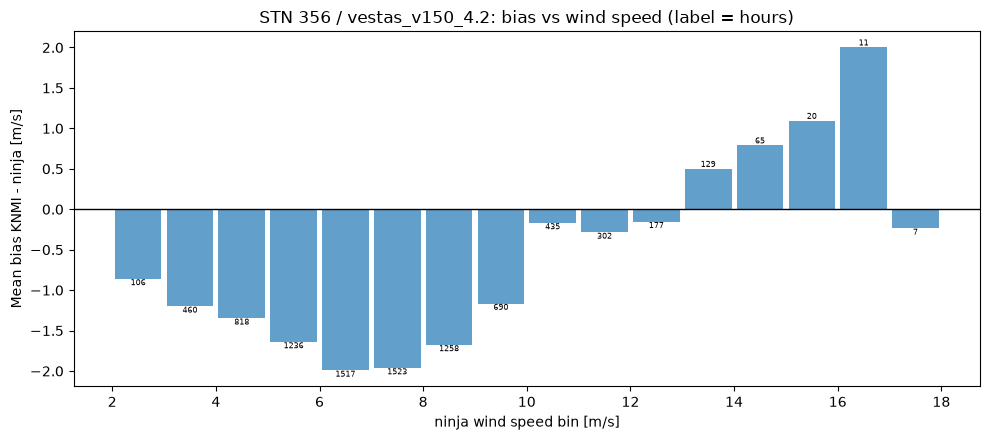

In [19]:
# Diagnostics: KNMI stations vs renewables.ninja hub wind speed, vestas_v150_4.2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

TURBINE_SHOWN = "vestas_v150_4.2"

ninja_df = pd.read_csv(
    NINJA_FILES[TURBINE_SHOWN], skiprows=3, parse_dates=["time"]
)[["time", "wind_speed"]].rename(columns={"wind_speed": "ninja"})

for stn, df in knmi.items():
    m = df[["time", f"ws_hub_{TURBINE_SHOWN}"]].rename(
        columns={f"ws_hub_{TURBINE_SHOWN}": "knmi"}
    ).merge(ninja_df, on="time", how="inner").dropna(subset=["knmi", "ninja"])

    k = m["knmi"].to_numpy(dtype=float)
    n = m["ninja"].to_numpy(dtype=float)
    diff = k - n
    mask = n >= 3.0

    print("=" * 60)
    print(f"STN {stn} / {TURBINE_SHOWN}  (z0={Z0_BY_STATION[stn]})")
    print("=" * 60)
    print(f"hours            {len(k)}")
    print(f"hours above cut-in {mask.sum()}")
    for lbl, s in [("KNMI hub", k), ("ninja", n)]:
        print(f"{lbl:>10s}  mean {s.mean():6.3f}  median {np.median(s):6.3f}  "
              f"std {s.std():5.3f}  min {s.min():5.3f}  max {s.max():5.3f}  "
              f"p05 {np.percentile(s,5):5.2f}  p95 {np.percentile(s,95):5.2f}")

    print("\nERRORS (KNMI - ninja)")
    print(f"mean bias     {diff.mean():+.3f} m/s")
    print(f"median bias   {np.median(diff):+.3f} m/s")
    print(f"MAE           {np.abs(diff).mean():.3f} m/s")
    print(f"RMSE          {np.sqrt((diff**2).mean()):.3f} m/s")
    print(f"RMSE >= 3 m/s {np.sqrt((diff[mask]**2).mean()):.3f} m/s")
    print(f"max |err|     {np.abs(diff).max():.3f} m/s")
    print(f"within ±1 m/s {(np.abs(diff)<=1).mean()*100:5.1f} %")
    print(f"within ±2 m/s {(np.abs(diff)<=2).mean()*100:5.1f} %")
    print(f"within ±3 m/s {(np.abs(diff)<=3).mean()*100:5.1f} %")

    r, p = stats.pearsonr(k, n)
    slope, intercept, _, _, _ = stats.linregress(n, k)
    rho, _ = stats.spearmanr(k, n)
    print("\nAGREEMENT")
    print(f"Pearson r     {r:+.4f}   (p={p:.2g})")
    print(f"Spearman rho  {rho:+.4f}")
    print(f"OLS: KNMI = {slope:.3f} * ninja {intercept:+.3f}")
    print(f"mean ratio    {k.mean()/n.mean():.3f}")

    # Time series, first 500 hours, wide
    fig, ax = plt.subplots(figsize=(16, 4))
    ax.plot(m["time"].iloc[:500], n[:500], lw=1.0, label="renewables.ninja")
    ax.plot(m["time"].iloc[:500], k[:500], lw=1.0, alpha=0.8,
            label=f"KNMI {stn} -> hub (z0={Z0_BY_STATION[stn]})")
    ax.set_xlabel("Time"); ax.set_ylabel("Hub wind speed [m/s]")
    ax.set_title(f"STN {stn} / {TURBINE_SHOWN}: first 500 hours")
    ax.legend(); ax.grid(True, alpha=0.3)
    plt.tight_layout(); plt.show()

    # Bias vs wind speed bin
    bins = np.arange(0, 21, 1.0)
    idx = np.digitize(n, bins) - 1
    mean_bias = [diff[idx == i].mean() if (idx == i).sum() > 5 else np.nan
                 for i in range(len(bins) - 1)]
    counts = [(idx == i).sum() for i in range(len(bins) - 1)]
    centers = 0.5 * (bins[:-1] + bins[1:])

    fig, ax = plt.subplots(figsize=(10, 4.5))
    ax.bar(centers, mean_bias, width=0.9, alpha=0.7)
    ax.axhline(0, color="k", lw=1)
    for c, b, nn in zip(centers, mean_bias, counts):
        if nn > 5 and not np.isnan(b):
            ax.text(c, b, f"{nn}", ha="center",
                    va="bottom" if b >= 0 else "top", fontsize=6)
    ax.set_xlabel("ninja wind speed bin [m/s]")
    ax.set_ylabel("Mean bias KNMI - ninja [m/s]")
    ax.set_title(f"STN {stn} / {TURBINE_SHOWN}: bias vs wind speed (label = hours)")
    plt.tight_layout(); plt.show()

### Gather local turbulence intensity data

In [20]:
import requests
import pandas as pd
from time import sleep

API_KEY = "eyJvcmciOiI1ZTU1NGUxOTI3NGE5NjAwMDEyYTNlYjEiLCJpZCI6IjY4MmJlMDNkNGUwZTQ1ZThhYWQ2MTI3NjMwYzllNTY4IiwiaCI6Im11cm11cjEyOCJ9"
BASE = "https://api.dataplatform.knmi.nl/edr/v1"
COLLECTION = "10-minute-in-situ-meteorological-observations"
HEADERS = {"Authorization": API_KEY}

LOCATIONS = {
    260: "0-20000-0-06260",
    267: "0-20000-0-06267",
    269: "0-20000-0-06269",
}

PARAMS = "ff,fsd,dd,dsd,gff"
YEAR = 2023
COOL_OFF_S = 5.0  # between stations; well inside the 1000 req/hour quota

def fetch_year(location_id, year):
    params = {
        "datetime": f"{year}-01-01T00:00:00Z/{year + 1}-01-01T00:00:00Z",
        "parameter-name": PARAMS,
    }
    r = requests.get(
        f"{BASE}/collections/{COLLECTION}/locations/{location_id}",
        headers=HEADERS, params=params, timeout=300,
    )
    r.raise_for_status()
    cov = r.json()["coverages"][0]
    times = pd.to_datetime(cov["domain"]["axes"]["t"]["values"])
    df = pd.DataFrame({"time": times})
    for pname in PARAMS.split(","):
        if pname in cov["ranges"]:
            df[pname] = cov["ranges"][pname]["values"]
    return df

for i, (wmo, lid) in enumerate(LOCATIONS.items()):
    print(f"WMO {wmo}: fetching {YEAR} ...")
    df = fetch_year(lid, YEAR)
    print(f"  rows: {len(df)}  (expect ~52560)")
    print(f"  ff valid:  {df['ff'].notna().sum()}")
    print(f"  fsd valid: {df['fsd'].notna().sum()}")
    print(f"  range: {df['time'].min()} to {df['time'].max()}")

    df.to_csv(f"knmi_{wmo}_{YEAR}_10min.csv", index=False)
    print(f"  saved: knmi_{wmo}_{YEAR}_10min.csv")

    if i < len(LOCATIONS) - 1:
        sleep(COOL_OFF_S)

WMO 260: fetching 2023 ...
  rows: 52553  (expect ~52560)
  ff valid:  52531
  fsd valid: 52526
  range: 2023-01-01 00:00:00+00:00 to 2024-01-01 00:00:00+00:00
  saved: knmi_260_2023_10min.csv
WMO 267: fetching 2023 ...
  rows: 52534  (expect ~52560)
  ff valid:  52518
  fsd valid: 52513
  range: 2023-01-01 00:00:00+00:00 to 2024-01-01 00:00:00+00:00
  saved: knmi_267_2023_10min.csv
WMO 269: fetching 2023 ...
  rows: 52553  (expect ~52560)
  ff valid:  52221
  fsd valid: 52221
  range: 2023-01-01 00:00:00+00:00 to 2024-01-01 00:00:00+00:00
  saved: knmi_269_2023_10min.csv



STN 260 SANITY CHECKS
Total 10-min records:      52553
Records above 2.0 m/s:     41526 (79.0%)
Records dropped (low wind/NaN): 11027

TI Statistics (valid records only):
  Mean:   0.2338
  Median: 0.2314
  Std:    0.0548
  Min:    0.0172
  Max:    0.9630
  p05:    0.1502
  p95:    0.3236
  Values > 0.5: 46 (0.11%)


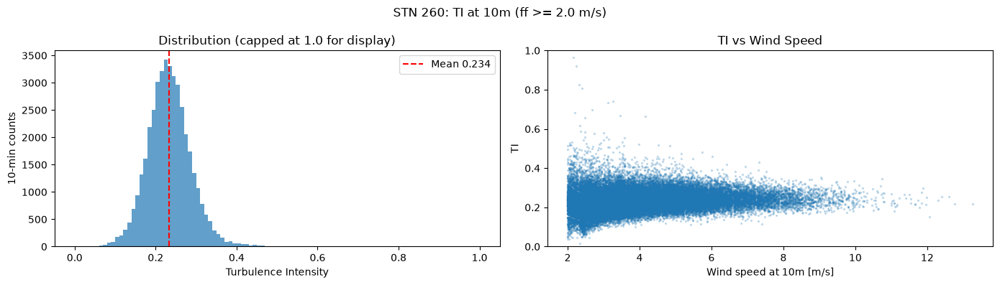


STN 267 SANITY CHECKS
Total 10-min records:      52534
Records above 2.0 m/s:     49210 (93.7%)
Records dropped (low wind/NaN): 3324

TI Statistics (valid records only):
  Mean:   0.1244
  Median: 0.1208
  Std:    0.0370
  Min:    0.0143
  Max:    0.8846
  p05:    0.0725
  p95:    0.1842
  Values > 0.5: 8 (0.02%)


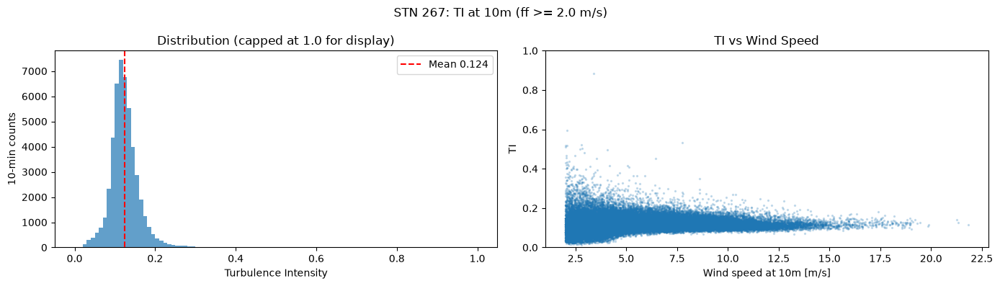


STN 269 SANITY CHECKS
Total 10-min records:      52553
Records above 2.0 m/s:     44269 (84.2%)
Records dropped (low wind/NaN): 8284

TI Statistics (valid records only):
  Mean:   0.1495
  Median: 0.1436
  Std:    0.0523
  Min:    0.0100
  Max:    0.7671
  p05:    0.0714
  p95:    0.2404
  Values > 0.5: 16 (0.04%)


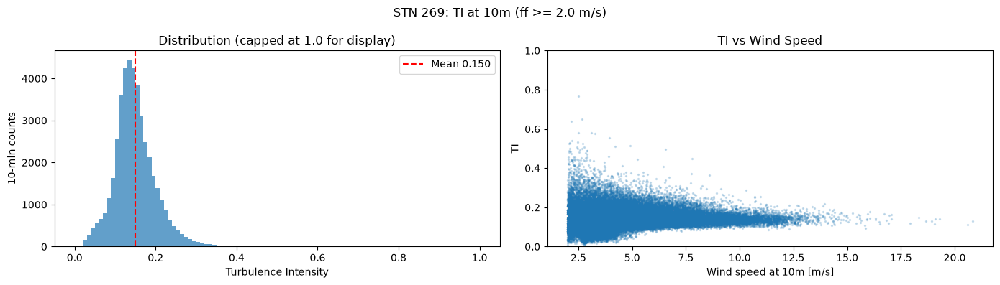

In [21]:
# Cell: Calculate TI at 10m from 10-min KNMI data and run sanity checks
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

YEAR = 2023
FF_FLOOR = 2.0  # m/s, below this TI is meaningless noise

for stn in LOCATIONS.keys():
    df = pd.read_csv(f"knmi_{stn}_{YEAR}_10min.csv", parse_dates=["time"])
    
    # Calculate raw TI
    df["ti_raw"] = df["fsd"] / df["ff"]
    
    # Valid mask: wind speed above floor and TI actually calculated
    valid_mask = (df["ff"] >= FF_FLOOR) & df["ti_raw"].notna()
    ti_valid = df.loc[valid_mask, "ti_raw"]
    
    print(f"\n" + "=" * 50)
    print(f"STN {stn} SANITY CHECKS")
    print("=" * 50)
    print(f"Total 10-min records:      {len(df)}")
    print(f"Records above {FF_FLOOR} m/s:     {valid_mask.sum()} ({valid_mask.mean()*100:.1f}%)")
    print(f"Records dropped (low wind/NaN): {(~valid_mask).sum()}")
    
    print(f"\nTI Statistics (valid records only):")
    print(f"  Mean:   {ti_valid.mean():.4f}")
    print(f"  Median: {ti_valid.median():.4f}")
    print(f"  Std:    {ti_valid.std():.4f}")
    print(f"  Min:    {ti_valid.min():.4f}")
    print(f"  Max:    {ti_valid.max():.4f}")
    print(f"  p05:    {ti_valid.quantile(0.05):.4f}")
    print(f"  p95:    {ti_valid.quantile(0.95):.4f}")
    
    # Check for extremes (often caused by low wind speeds just above the floor)
    extreme_count = (ti_valid > 0.5).sum()
    print(f"  Values > 0.5: {extreme_count} ({(extreme_count/len(ti_valid))*100:.2f}%)")
    
    # Plot distribution and vs wind speed
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    fig.suptitle(f"STN {stn}: TI at 10m (ff >= {FF_FLOOR} m/s)", fontsize=12)
    
    # Histogram
    axes[0].hist(ti_valid, bins=100, range=(0, 1.0), alpha=0.7)
    axes[0].axvline(ti_valid.mean(), color="r", ls="--", label=f"Mean {ti_valid.mean():.3f}")
    axes[0].set_xlabel("Turbulence Intensity")
    axes[0].set_ylabel("10-min counts")
    axes[0].set_title("Distribution (capped at 1.0 for display)")
    axes[0].legend()
    
    # TI vs Wind Speed scatter
    axes[1].scatter(df.loc[valid_mask, "ff"], ti_valid, s=2, alpha=0.2)
    axes[1].set_xlabel("Wind speed at 10m [m/s]")
    axes[1].set_ylabel("TI")
    axes[1].set_ylim(0, 1.0)
    axes[1].set_title("TI vs Wind Speed")
    
    plt.tight_layout()
    plt.show()

Conclusion: turbulence intensity is around 0.17 at 10m, decreases as it approaches hub height. Don't know how to defensibly scale the 10m values to hub height, so resorting to using a flat turbulence intensity profile.

### Compare FLORIS simulations with and without wake effects to renewables.ninja outcomes

=== STN 267 / vestas_v150_4.2 (8760 hours) | TI=0.1 ===
FLORIS mean [kW]:          2266.6
ninja mean  [kW]:          2028.6
mean diff   [kW]:          238.0
mean diff above cut-in:    336.1
MAE above cut-in [kW]:     867.4
RMSE above cut-in [kW]:    1087.4
FLORIS AEP [GWh]:          19855.45
ninja AEP  [GWh]:          17770.37
AEP ratio FLORIS/ninja:    1.117


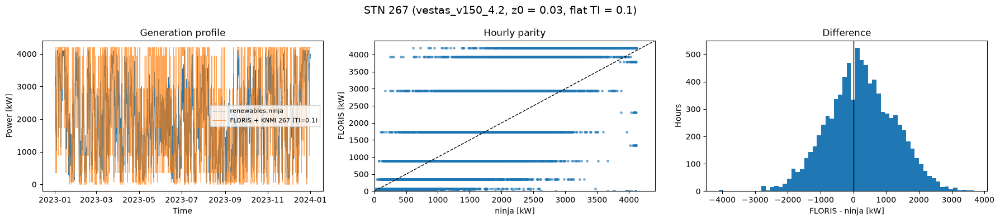

In [19]:
# Test (Flat TI = 0.1): FLORIS on 1h KNMI hub speeds vs ninja power, V150 at STN 267
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from floris import FlorisModel

TURBINE_SHOWN = "vestas_v150_4.2"
TARGET_STN = 267
TI_FLAT = 0.10

floris_results_knmi_ti01 = {}

name = TURBINE_SHOWN
stn = TARGET_STN
t = turbines[name]

m = ws_results_knmi[(stn, name)][["time", "DD", "knmi_hub"]].copy()

# replace missing/zero hub speeds with a tiny number instead of dropping
ws = m["knmi_hub"].to_numpy(dtype=float).copy()
ws[~np.isfinite(ws) | (ws <= 0)] = 0.001

# handle direction: fill calm/variable with interpolation
DD = m["DD"].where(m["DD"].between(1, 360)).interpolate().ffill().bfill().to_numpy(dtype=float)

fm = FlorisModel("defaults")
fm.set(
    layout_x=[0.0], layout_y=[0.0], turbine_type=[t],
    reference_wind_height=t["hub_height"], wind_shear=0.0,
)
fm.set(
    wind_speeds=ws,
    wind_directions=DD,
    turbulence_intensities=TI_FLAT * np.ones_like(ws),
)
fm.run()
floris_kw = fm.get_turbine_powers()[:, 0] / 1000.0

floris_results_knmi_ti01[(stn, name)] = {
    "time": m["time"].to_numpy(),
    "ws": ws,
    "floris_kw": floris_kw,
}

# Pull ninja electricity (kW) and align
ninja = pd.read_csv(NINJA_FILES[name], skiprows=3, parse_dates=["time"])[["time", "electricity"]]
ninja_kw = ninja.set_index("time")["electricity"]

r = floris_results_knmi_ti01[(stn, name)]
r["ninja_kw"] = pd.Series(r["time"]).map(ninja_kw).to_numpy(dtype=float)

# Print stats
ws = r["ws"]; f = r["floris_kw"]; n = r["ninja_kw"]
d = f - n
mask = ws >= 3.0

print(f"=== STN {stn} / {name} ({len(ws)} hours) | TI={TI_FLAT} ===")
print(f"FLORIS mean [kW]:          {f.mean():.1f}")
print(f"ninja mean  [kW]:          {n.mean():.1f}")
print(f"mean diff   [kW]:          {d.mean():.1f}")
print(f"mean diff above cut-in:    {d[mask].mean():.1f}")
print(f"MAE above cut-in [kW]:     {np.abs(d[mask]).mean():.1f}")
print(f"RMSE above cut-in [kW]:    {np.sqrt((d[mask]**2).mean()):.1f}")
print(f"FLORIS AEP [GWh]:          {f.sum()/1e3:.2f}")
print(f"ninja AEP  [GWh]:          {n.sum()/1e3:.2f}")
print(f"AEP ratio FLORIS/ninja:    {f.sum()/n.sum():.3f}")

# Plot
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
fig.suptitle(f"STN {stn} ({name}, z0 = {Z0_BY_STATION[stn]}, flat TI = {TI_FLAT})", fontsize=14)

t_arr = r["time"]

ax = axes[0]
ax.plot(t_arr, n, lw=0.7, label="renewables.ninja")
ax.plot(t_arr, f, lw=0.7, alpha=0.7, label=f"FLORIS + KNMI {stn} (TI={TI_FLAT})")
ax.set_xlabel("Time"); ax.set_ylabel("Power [kW]")
ax.set_title("Generation profile"); ax.legend(fontsize=8)

ax = axes[1]
ax.scatter(n, f, s=6, alpha=0.5)
lim = [0, max(np.nanmax(n), np.nanmax(f)) * 1.05]
ax.plot(lim, lim, "k--", lw=1)
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("ninja [kW]"); ax.set_ylabel("FLORIS [kW]")
ax.set_title("Hourly parity")

ax = axes[2]
ax.hist(f - n, bins=60); ax.axvline(0, color="k", lw=1)
ax.set_xlabel("FLORIS - ninja [kW]"); ax.set_ylabel("Hours")
ax.set_title("Difference")

plt.tight_layout()
plt.show()

Target: 50.0 MW -> 12 x 4.2 MW = 50.4 MW
Grid: 3x4 (12 turbines) at 9.0D spacing

=== AEP Summary (GWh) ===
          ninja: 213.24
  floris_nowake: 238.27
    floris_wake: 233.77


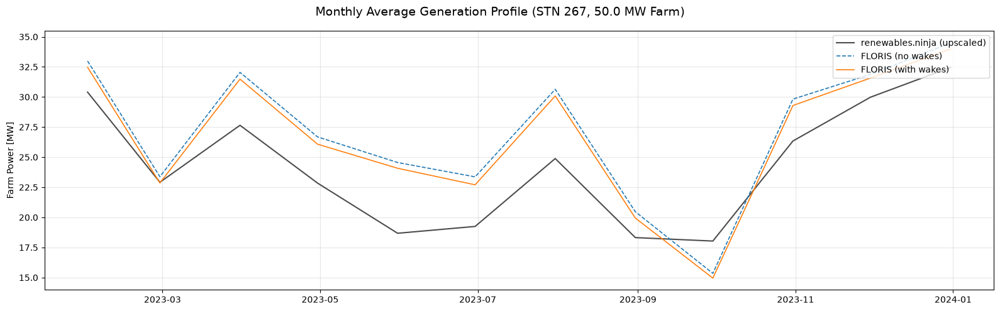

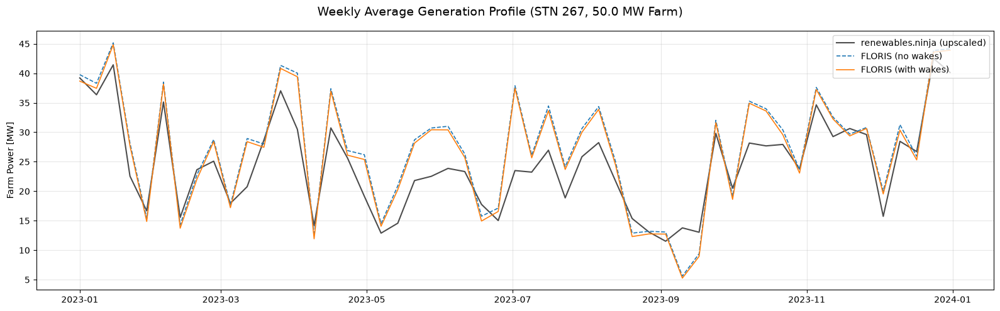

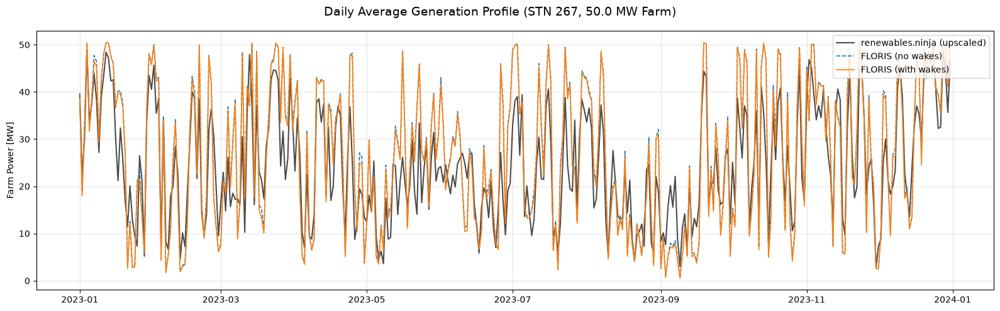

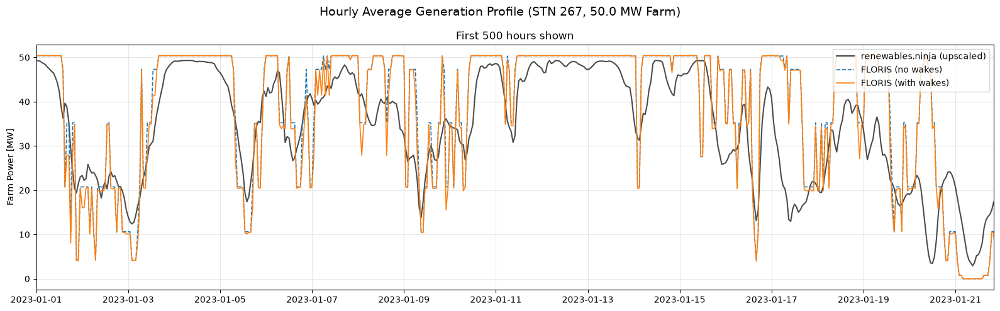

In [ ]:
# Cell: Farm-level FLORIS (wake vs no-wake) vs upscaled ninja, multi-resolution plots
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from floris import FlorisModel

# --- INPUTS ---
TARGET_MW = 50.0
TURBINE_SHOWN = "vestas_v150_4.2"
TARGET_STN = 267
TI_FLAT = 0.10
SPACING_D = 6

t = turbines[TURBINE_SHOWN]
stn = TARGET_STN

# --- 1. Auto Layout ---
rated_power_kw = np.max(t["power_thrust_table"]["power"])
rated_power_mw = rated_power_kw / 1e3

n_turbines = round(TARGET_MW / rated_power_mw)
n_rows = int(np.floor(np.sqrt(n_turbines)))
while n_turbines % n_rows != 0:
    n_rows -= 1
n_cols = n_turbines // n_rows

D = t["rotor_diameter"]
spacing = SPACING_D * D

layout_x, layout_y = [], []
for i in range(n_rows):
    for j in range(n_cols):
        layout_x.append(j * spacing)
        layout_y.append(i * spacing)

print(f"Target: {TARGET_MW} MW -> {n_turbines} x {rated_power_mw:.1f} MW = {n_turbines * rated_power_mw:.1f} MW")
print(f"Grid: {n_rows}x{n_cols} ({n_turbines} turbines) at {SPACING_D}D spacing")

# --- 2. Prep Time Series ---
m = ws_results_knmi[(stn, TURBINE_SHOWN)][["time", "DD", "knmi_hub"]].copy()

ws = m["knmi_hub"].to_numpy(dtype=float).copy()
ws[~np.isfinite(ws) | (ws <= 0)] = 0.001
DD = m["DD"].where(m["DD"].between(1, 360)).interpolate().ffill().bfill().to_numpy(dtype=float)

# Upscaled ninja (using single-turbine profile * n_turbines)
ninja_1t = pd.read_csv(NINJA_FILES[TURBINE_SHOWN], skiprows=3, parse_dates=["time"])[["time", "electricity"]]
ninja_1t_mw = ninja_1t.set_index("time")["electricity"] / 1e3
ninja_mw_farm = pd.Series(m["time"]).map(ninja_1t_mw).to_numpy(dtype=float) * n_turbines

# --- 3. Run FLORIS (With Wakes) ---
fm_wake = FlorisModel("defaults")
fm_wake.set(
    layout_x=layout_x, layout_y=layout_y, turbine_type=[t],
    reference_wind_height=t["hub_height"], wind_shear=0.0,
)
fm_wake.set(
    wind_speeds=ws, wind_directions=DD, turbulence_intensities=TI_FLAT * np.ones_like(ws),
)
fm_wake.run()
floris_wake_mw = fm_wake.get_farm_power() / 1e6  # W to MW

# --- 4. Run FLORIS (No Wakes) ---
layout_x_nw = [i * 1000 * D for i in range(n_turbines)]
layout_y_nw = [0.0] * n_turbines

fm_nowake = FlorisModel("defaults")
fm_nowake.set(
    layout_x=layout_x_nw, layout_y=layout_y_nw, turbine_type=[t],
    reference_wind_height=t["hub_height"], wind_shear=0.0,
)
fm_nowake.set(
    wind_speeds=ws, wind_directions=DD, turbulence_intensities=TI_FLAT * np.ones_like(ws),
)
fm_nowake.run()
floris_nowake_mw = fm_nowake.get_farm_power() / 1e6  # W to MW

# --- 5. Assemble and Aggregate ---
df = pd.DataFrame({
    "time": m["time"],
    "ninja": ninja_mw_farm,
    "floris_nowake": floris_nowake_mw,
    "floris_wake": floris_wake_mw,
}).set_index("time")

agg = {
    "Monthly": df.resample("ME").mean(),
    "Weekly": df.resample("W-SUN").mean(),
    "Daily": df.resample("D").mean(),
    "Hourly": df
}

print("\n=== AEP Summary (GWh) ===")
for col in ["ninja", "floris_nowake", "floris_wake"]:
    print(f"{col:>15s}: {df[col].sum() / 1e3:.2f}")

# --- 6. Plotting ---
for label, data in agg.items():
    fig, ax = plt.subplots(figsize=(16, 5))
    fig.suptitle(f"{label} Average Generation Profile (STN {stn}, {TARGET_MW} MW Farm)", fontsize=14)
    
    ax.plot(data.index, data["ninja"], lw=1.5, label="renewables.ninja (upscaled)", color="black", alpha=0.7)
    ax.plot(data.index, data["floris_nowake"], lw=1.2, label="FLORIS (no wakes)", ls="--", color="tab:blue")
    ax.plot(data.index, data["floris_wake"], lw=1.2, label="FLORIS (with wakes)", color="tab:orange")
    
    ax.set_ylabel("Farm Power [MW]")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper right")
    
    if label == "Hourly":
        ax.set_xlim(data.index[0], data.index[500])
        ax.set_title("First 500 hours shown")
        
    plt.tight_layout()
    plt.show()


--- Processing STN 240 / vestas_v150_4.2 ---
  Grid: 5x5 (24 turbines) at 6D spacing
  Farm Capacity: 100.8 MW
            ninja AEP [GWh]:  426.49  |  CF: 48.30%
    floris_nowake AEP [GWh]:  444.29  |  CF: 50.32%
      floris_wake AEP [GWh]:  422.58  |  CF: 47.86%

--- Processing STN 275 / vestas_v150_4.2 ---
  Grid: 5x5 (24 turbines) at 6D spacing
  Farm Capacity: 100.8 MW
            ninja AEP [GWh]:  426.49  |  CF: 48.30%
    floris_nowake AEP [GWh]:  263.82  |  CF: 29.88%
      floris_wake AEP [GWh]:  245.63  |  CF: 27.82%

--- Processing STN 348 / vestas_v150_4.2 ---
  Grid: 5x5 (24 turbines) at 6D spacing
  Farm Capacity: 100.8 MW
            ninja AEP [GWh]:  426.49  |  CF: 48.30%
    floris_nowake AEP [GWh]:  321.20  |  CF: 36.38%
      floris_wake AEP [GWh]:  301.68  |  CF: 34.17%

--- Processing STN 260 / vestas_v150_4.2 ---
  Grid: 5x5 (24 turbines) at 6D spacing
  Farm Capacity: 100.8 MW
            ninja AEP [GWh]:  426.49  |  CF: 48.30%
    floris_nowake AEP [GWh]:  31

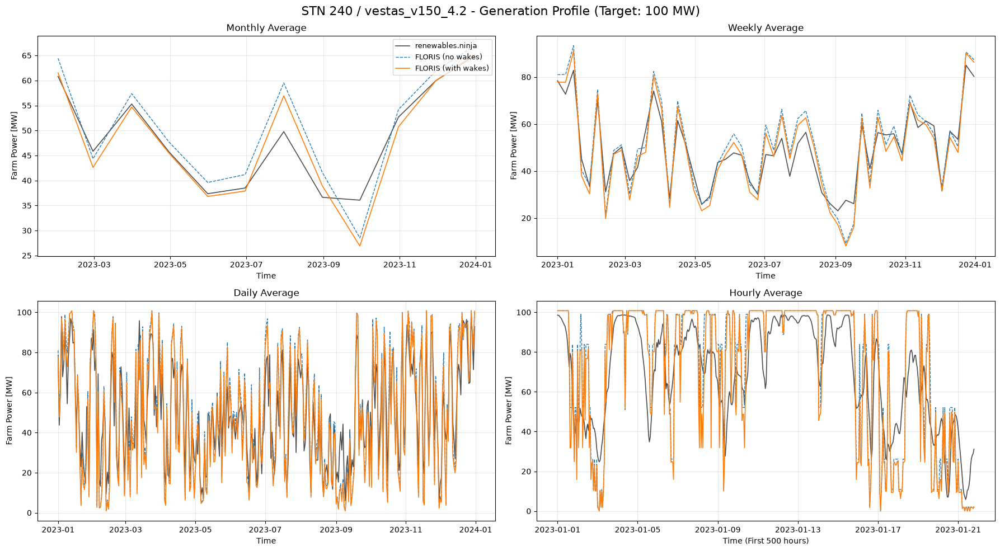

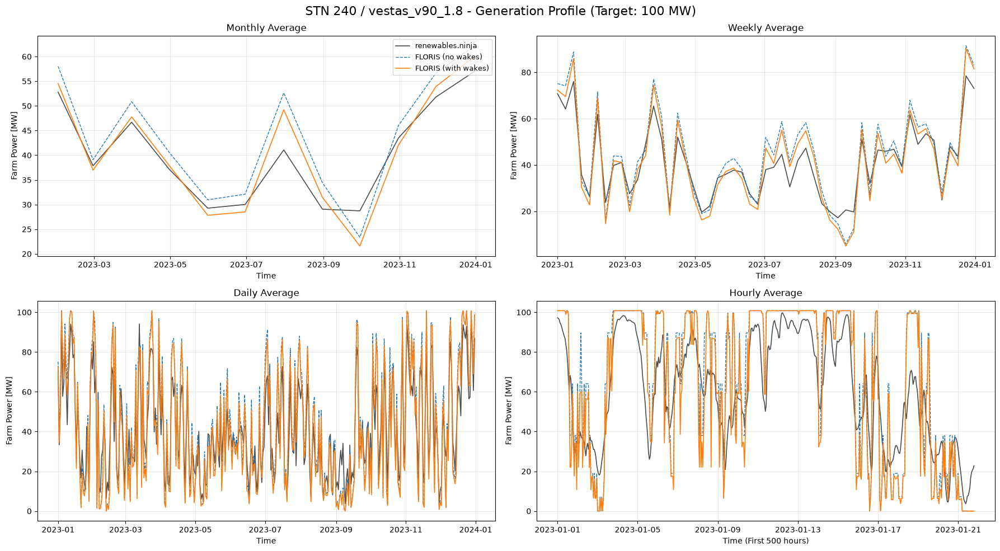

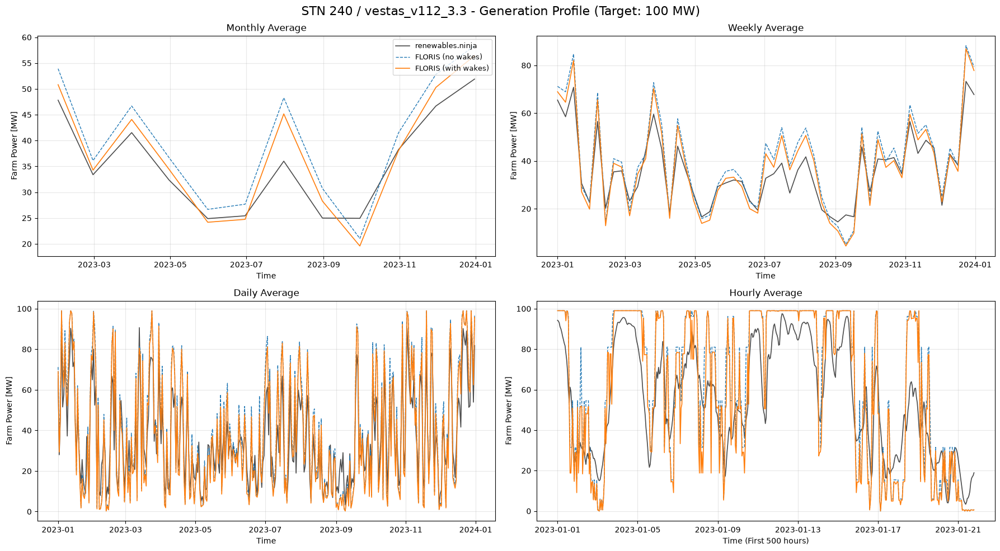

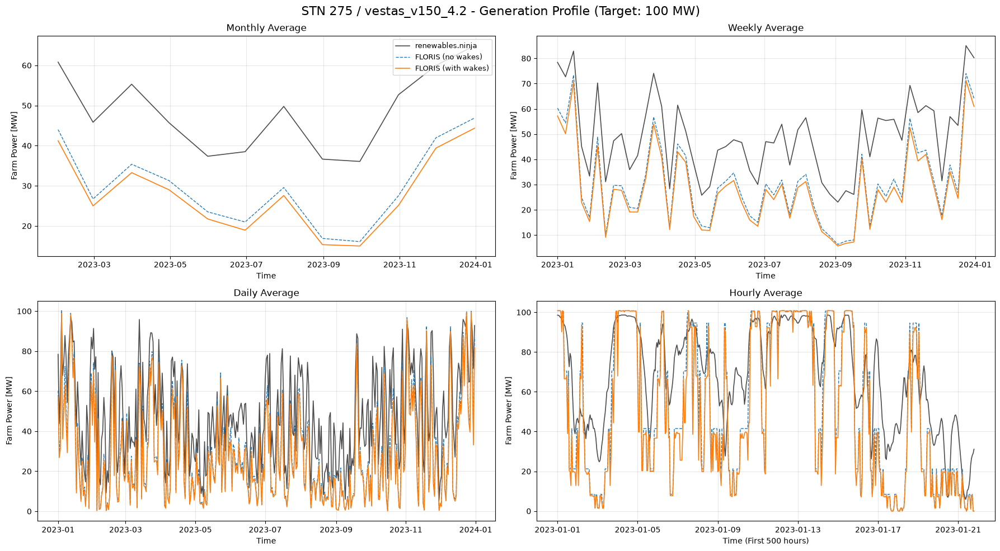

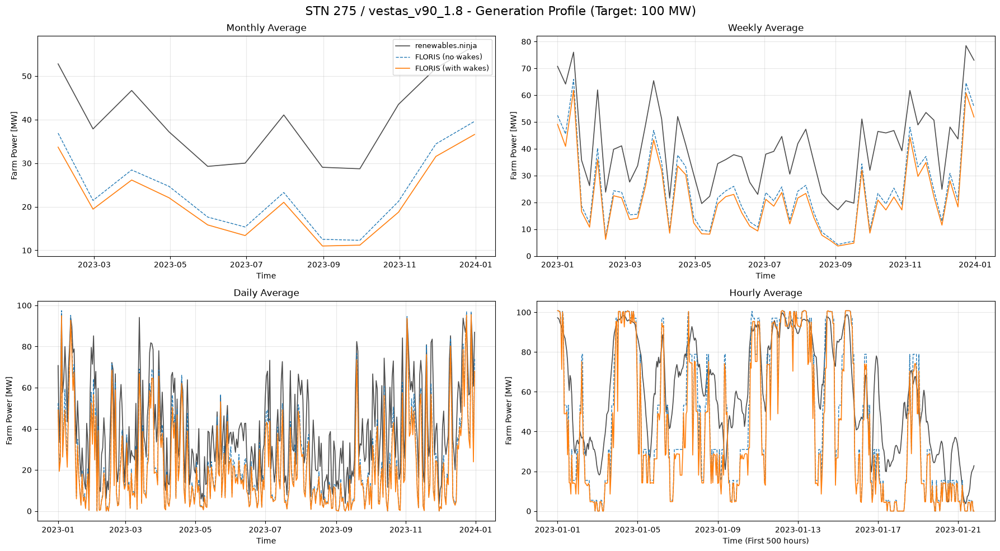

...

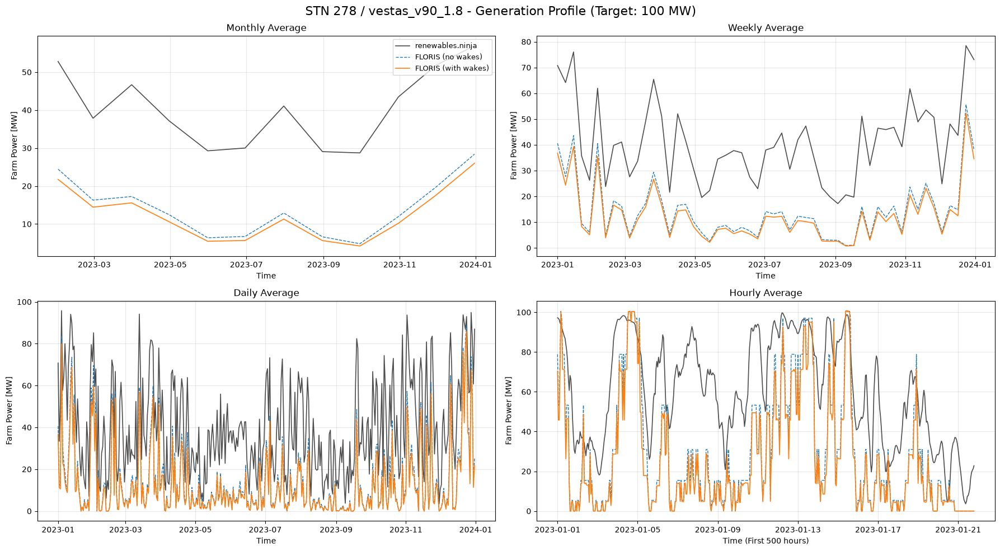

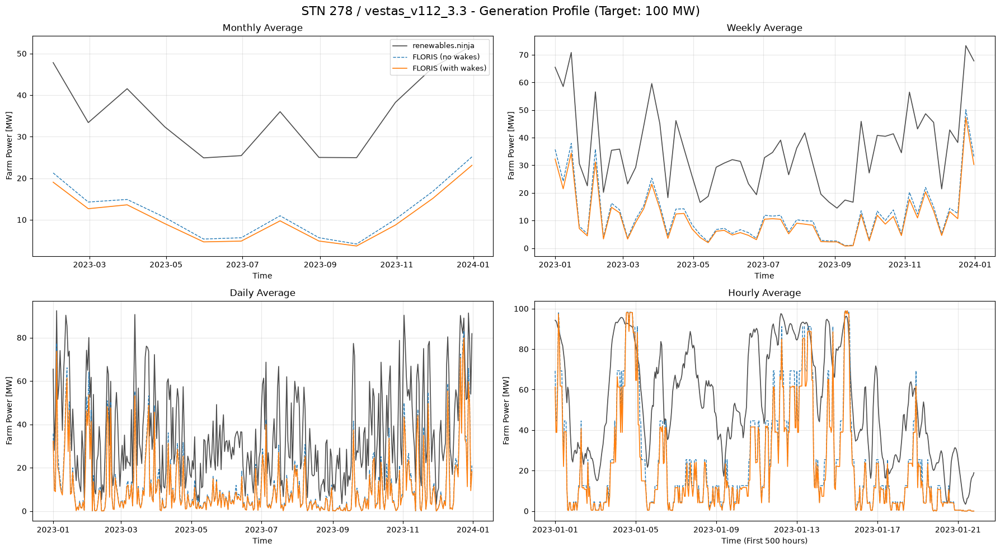

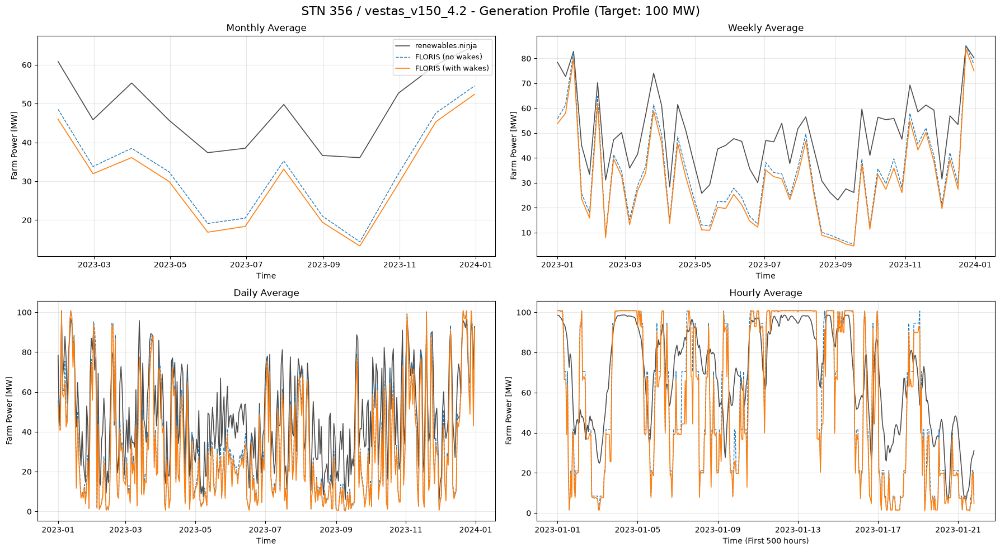

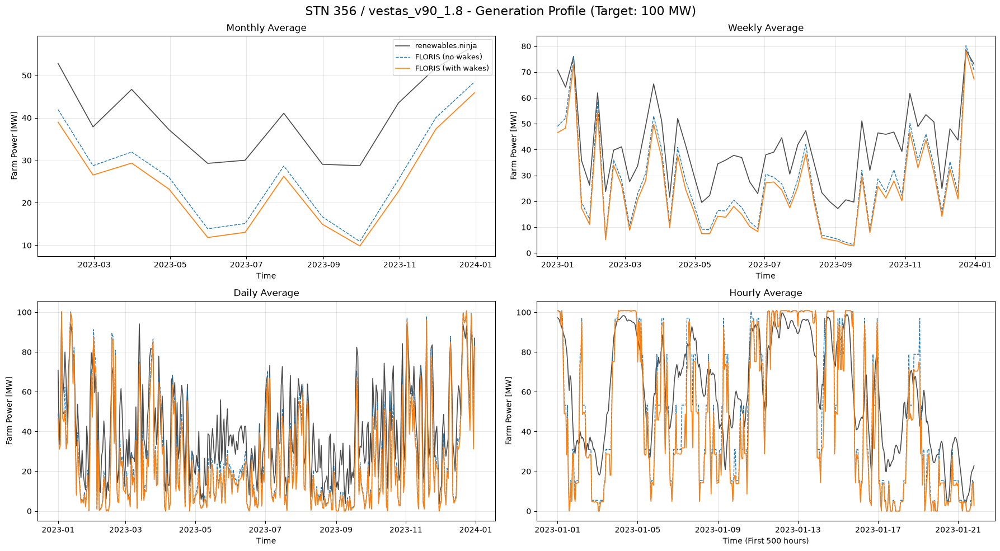

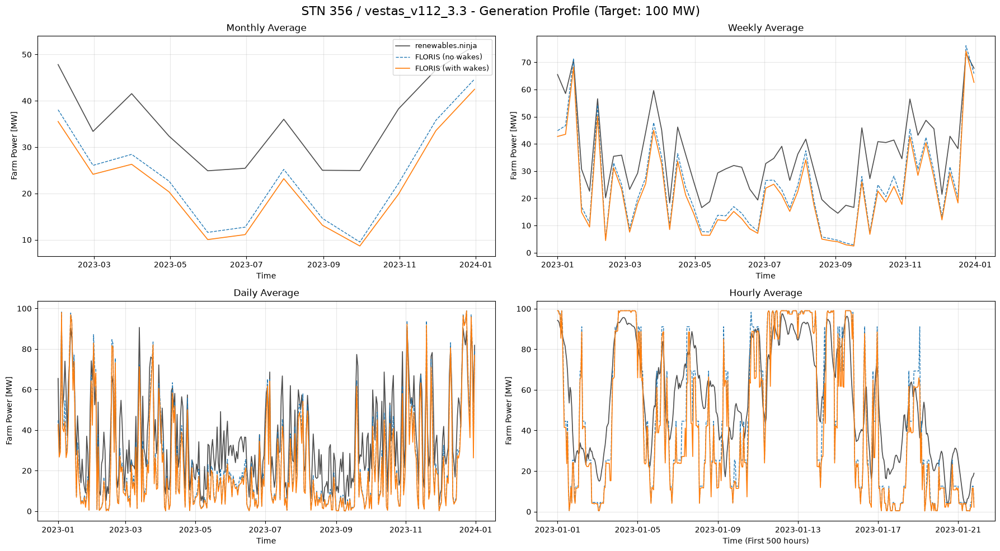

In [23]:
# Cell: Farm-level FLORIS (wake vs no-wake) vs upscaled ninja, separate figures, prints AEP and CF
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from floris import FlorisModel

# --- INPUTS ---
TARGET_MW = 100
TI_FLAT = 0.10
SPACING_D = 6

all_results = {}

for name in NINJA_FILES.keys():
    t = turbines[name]

    
    # --- 1. Auto Layout ---
    rated_power_kw = np.max(t["power_thrust_table"]["power"])
    rated_power_mw = rated_power_kw / 1e3
    
    n_turbines = round(TARGET_MW / rated_power_mw)
    
    # Find the most square grid, allowing the last row to be partially filled
    n_rows = int(np.round(np.sqrt(n_turbines)))
    n_cols = int(np.ceil(n_turbines / n_rows))
    
    D = t["rotor_diameter"]
    spacing = SPACING_D * D
    
    layout_x, layout_y = [], []
    count = 0
    for i in range(n_rows):
        for j in range(n_cols):
            if count < n_turbines:
                layout_x.append(j * spacing)
                layout_y.append(i * spacing)
                count += 1
            
    layout_x_nw = [i * 1000 * D for i in range(n_turbines)]
    layout_y_nw = [0.0] * n_turbines

    for stn in knmi.keys():
        print(f"\n--- Processing STN {stn} / {name} ---")
        m = ws_results_knmi[(stn, name)][["time", "DD", "knmi_hub"]].copy()

        ws = m["knmi_hub"].to_numpy(dtype=float).copy()
        ws[~np.isfinite(ws) | (ws <= 0)] = 0.001
        DD = m["DD"].where(m["DD"].between(1, 360)).interpolate().ffill().bfill().to_numpy(dtype=float)

        # Upscaled ninja
        ninja_1t = pd.read_csv(NINJA_FILES[name], skiprows=3, parse_dates=["time"])[["time", "electricity"]]
        ninja_1t_mw = ninja_1t.set_index("time")["electricity"] / 1e3
        ninja_mw_farm = pd.Series(m["time"]).map(ninja_1t_mw).to_numpy(dtype=float) * n_turbines

        # FLORIS with wakes
        fm_wake = FlorisModel("defaults")
        fm_wake.set(
            layout_x=layout_x, layout_y=layout_y, turbine_type=[t],
            reference_wind_height=t["hub_height"], wind_shear=0.0,
        )
        fm_wake.set(
            wind_speeds=ws, wind_directions=DD, turbulence_intensities=TI_FLAT * np.ones_like(ws),
        )
        fm_wake.run()
        floris_wake_mw = fm_wake.get_farm_power() / 1e6

        # FLORIS without wakes
        fm_nowake = FlorisModel("defaults")
        fm_nowake.set(
            layout_x=layout_x_nw, layout_y=layout_y_nw, turbine_type=[t],
            reference_wind_height=t["hub_height"], wind_shear=0.0,
        )
        fm_nowake.set(
            wind_speeds=ws, wind_directions=DD, turbulence_intensities=TI_FLAT * np.ones_like(ws),
        )
        fm_nowake.run()
        floris_nowake_mw = fm_nowake.get_farm_power() / 1e6

        # Assemble
        df = pd.DataFrame({
            "time": m["time"],
            "ninja": ninja_mw_farm,
            "floris_nowake": floris_nowake_mw,
            "floris_wake": floris_wake_mw,
        }).set_index("time")
        
        all_results[(stn, name)] = df

        # Print AEP and Capacity Factor
        farm_capacity_mw = n_turbines * rated_power_mw
        hours = len(df)
        max_possible_gwh = (farm_capacity_mw * hours) / 1e3
        
        print(f"  Grid: {n_rows}x{n_cols} ({n_turbines} turbines) at {SPACING_D}D spacing")
        print(f"  Farm Capacity: {farm_capacity_mw:.1f} MW")
        for col in ["ninja", "floris_nowake", "floris_wake"]:
            aep = df[col].sum() / 1e3
            cf = (aep / max_possible_gwh) * 100
            print(f"  {col:>15s} AEP [GWh]: {aep:7.2f}  |  CF: {cf:5.2f}%")

# --- 6. Plotting ---
subplot_map = {
    "Monthly": (0, 0, "ME"),
    "Weekly": (0, 1, "W-SUN"),
    "Daily": (1, 0, "D"),
    "Hourly": (1, 1, None)
}

for stn in knmi.keys():
    for name in NINJA_FILES.keys():
        df = all_results[(stn, name)]
        
        fig, axes = plt.subplots(2, 2, figsize=(18, 10))
        fig.suptitle(f"STN {stn} / {name} - Generation Profile (Target: {TARGET_MW} MW)", fontsize=16)
        
        for label, (row, col, freq) in subplot_map.items():
            ax = axes[row, col]
            ax.set_title(f"{label} Average")
            
            if freq:
                data = df.resample(freq).mean()
            else:
                data = df
                
            if label == "Hourly":
                data = data.iloc[:500]
                ax.set_xlabel("Time (First 500 hours)")
            else:
                ax.set_xlabel("Time")
                
            ax.plot(data.index, data["ninja"], lw=1.2, color="black", alpha=0.7, label="renewables.ninja")
            ax.plot(data.index, data["floris_nowake"], lw=1.0, ls="--", color="tab:blue", label="FLORIS (no wakes)")
            ax.plot(data.index, data["floris_wake"], lw=1.2, ls="-", color="tab:orange", label="FLORIS (with wakes)")

            ax.set_ylabel("Farm Power [MW]")
            ax.grid(True, alpha=0.3)
            
            if label == "Monthly":
                ax.legend(fontsize=9, loc="upper right")

        plt.tight_layout()
        plt.show()

Conclusion: agreement between FLORIS with KNMI wind speed measurements and renewables.ninja depends on selected station and surface roughness value. Wake effects reduce power output across the board, usually improving the fit in annual/monthly/weekly terms but with minimal effect on daily/hourly output. Conclusions hold across wind turbines.

### Try to optimize the farm layout to maximize AEP

Initial layout: 3x4 (12 turbines) at 9.0D spacing


floris.optimization.layout_optimization.layout_optimization_random_search.LayoutOptimizationRandomSearch WARNING Running layout optimization without a WindData object (e.g. TimeSeries, WindRose, WindTIRose). We suggest that the user set the wind conditions (and if applicable, frequencies and values) on the FlorisModel using the wind_data keyword argument for layout optimizations to capture frequencies and the value of the energy production accurately. If a WindData object is not defined, uniform frequencies will be assumed. If use_value is True and a WindData object is not defined, a value of 1 will be used for each wind condition and layout optimization will simply be performed to maximize AEP.
floris.floris_model.FlorisModel WARNING Computing AEP with uniform frequencies. Results results may not reflect annual operation.
floris.floris_model.FlorisModel WARNING Computing AEP with uniform frequencies. Results results may not reflect annual operation.


Generating 4 initial layouts...


floris.floris_model.FlorisModel WARNING Computing AEP with uniform frequencies. Results results may not reflect annual operation.
floris.floris_model.FlorisModel WARNING Computing AEP with uniform frequencies. Results results may not reflect annual operation.
floris.floris_model.FlorisModel WARNING Computing AEP with uniform frequencies. Results results may not reflect annual operation.
floris.floris_model.FlorisModel WARNING Computing AEP with uniform frequencies. Results results may not reflect annual operation.


  Time to generate initial layouts: 37.311 s
Optimization step +0.0
Optimization time = +37.3 [s]
Mean AEP = 232.2 [GWh] (-0.66%)
Median AEP = 232.2 [GWh] (-0.66%)
Max AEP = 232.4 [GWh] (-0.59%)
Min AEP = 232.1 [GWh] (-0.71%)
Random Layout Optimization
Number of turbines to optimize = 12
Minimum distance between turbines = 2.6999999999999997 [D], 404.99999999999994 [m]
Number of individuals = 4
Seconds per iteration = 30
Initial AEP = 233.8 [GWh]
Optimizing using 4 individuals.
Optimization time: 0.0 s / 300.0 s
Optimization step +1.0
Optimization time = +85.4 [s]
Mean AEP = 232.4 [GWh] (-0.60%)
Median AEP = 232.3 [GWh] (-0.61%)
Max AEP = 232.6 [GWh] (-0.51%)
Min AEP = 232.2 [GWh] (-0.69%)
Optimization time: 48.1 s / 300.0 s
Optimization step +2.0
Optimization time = +134.4 [s]
Mean AEP = 232.5 [GWh] (-0.56%)
Median AEP = 232.5 [GWh] (-0.55%)
Max AEP = 232.6 [GWh] (-0.51%)
Min AEP = 232.3 [GWh] (-0.62%)
Optimization time: 97.1 s / 300.0 s
Optimization step +3.0
Optimization time = +178

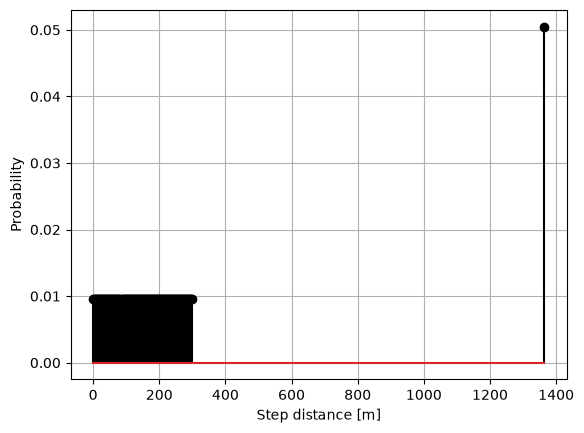

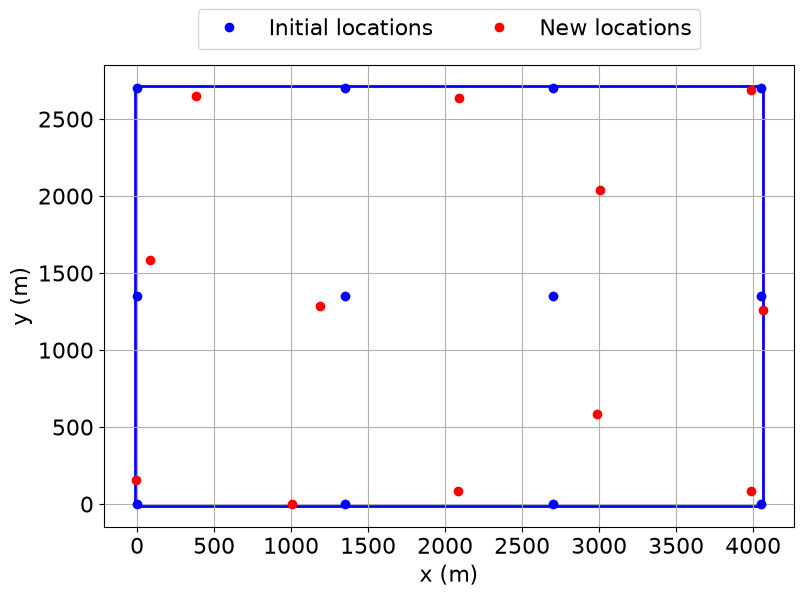

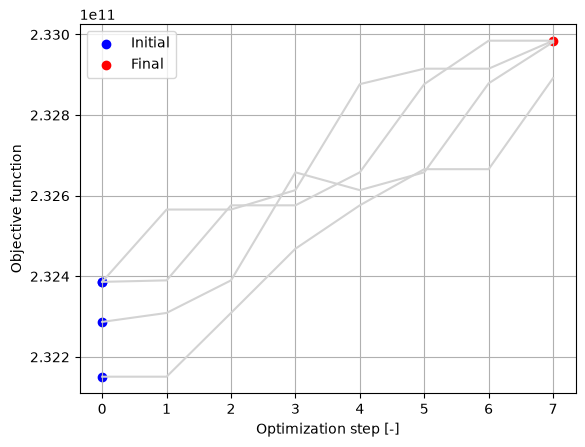


Optimized layout coordinates:
  Turbine 0: (0.0, 0.0)
  Turbine 1: (1350.0, 0.0)
  Turbine 2: (2700.0, 0.0)
  Turbine 3: (4050.0, 0.0)
  Turbine 4: (0.0, 1350.0)
  Turbine 5: (1350.0, 1350.0)
  Turbine 6: (2700.0, 1350.0)
  Turbine 7: (4050.0, 1350.0)
  Turbine 8: (0.0, 2700.0)
  Turbine 9: (1350.0, 2700.0)
  Turbine 10: (2700.0, 2700.0)
  Turbine 11: (4050.0, 2700.0)

AEP initial  [GWh]: 233.77
AEP optimized [GWh]: 233.77
Improvement: 0.00%


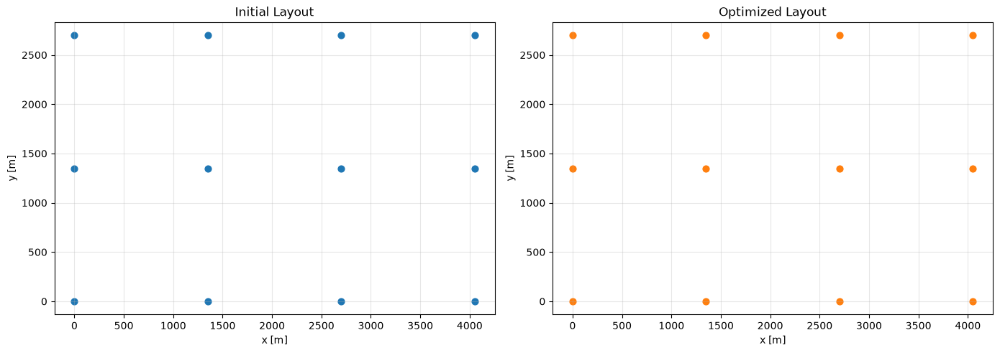

In [25]:
# Cell: Layout optimization using LayoutOptimizationRandomSearch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from floris import FlorisModel
from floris.optimization.layout_optimization.layout_optimization_random_search import (
    LayoutOptimizationRandomSearch,
)

# --- INPUTS ---
TARGET_MW = 50.0
TURBINE_SHOWN = "vestas_v150_4.2"
TARGET_STN = 267
TI_FLAT = 0.10
SPACING_D = 9.0

t = turbines[TURBINE_SHOWN]
stn = TARGET_STN

# --- 1. Auto Layout (initial) ---
rated_power_kw = np.max(t["power_thrust_table"]["power"])
rated_power_mw = rated_power_kw / 1e3
n_turbines = round(TARGET_MW / rated_power_mw)

n_rows = int(np.floor(np.sqrt(n_turbines)))
while n_turbines % n_rows != 0:
    n_rows -= 1
n_cols = n_turbines // n_rows

D = t["rotor_diameter"]
spacing = SPACING_D * D

layout_x, layout_y = [], []
for i in range(n_rows):
    for j in range(n_cols):
        layout_x.append(j * spacing)
        layout_y.append(i * spacing)

print(f"Initial layout: {n_rows}x{n_cols} ({n_turbines} turbines) at {SPACING_D}D spacing")

# --- 2. Prep Time Series ---
m = ws_results_knmi[(stn, TURBINE_SHOWN)][["time", "DD", "knmi_hub"]].copy()
ws = m["knmi_hub"].to_numpy(dtype=float).copy()
ws[~np.isfinite(ws) | (ws <= 0)] = 0.001
DD = m["DD"].where(m["DD"].between(1, 360)).interpolate().ffill().bfill().to_numpy(dtype=float)

# --- 3. Set up FlorisModel ---
fm_opt = FlorisModel("defaults")
fm_opt.set(
    layout_x=layout_x, layout_y=layout_y, turbine_type=[t],
    reference_wind_height=t["hub_height"], wind_shear=0.0,
)
fm_opt.set(
    wind_speeds=ws, wind_directions=DD, turbulence_intensities=TI_FLAT * np.ones_like(ws),
)

# --- 4. Boundaries: rectangle containing the initial layout with margin ---
x_min = min(layout_x) - 0.01 * spacing
x_max = max(layout_x) + 0.01 * spacing
y_min = min(layout_y) - 0.01 * spacing
y_max = max(layout_y) + 0.01 * spacing

boundaries = [(x_min, y_min), (x_max, y_min), (x_max, y_max), (x_min, y_max)]

# --- 5. Configure and run optimizer ---
layout_opt = LayoutOptimizationRandomSearch(
    fm_opt,
    boundaries,
    min_dist_D=0.3*SPACING_D,
    seconds_per_iteration=30,
    total_optimization_seconds=300,
    distance_pmf=None,
)

layout_opt.describe()
layout_opt.plot_distance_pmf()
layout_opt.optimize()
layout_opt.plot_layout_opt_results()
layout_opt.plot_progress()

plt.show()

# --- 6. Extract optimized layout and evaluate AEP comparison ---
optimized_layout = np.array([
    [fm_opt.layout_x[i], fm_opt.layout_y[i]] for i in range(n_turbines)
])
print("\nOptimized layout coordinates:")
for i in range(n_turbines):
    print(f"  Turbine {i}: ({optimized_layout[i, 0]:.1f}, {optimized_layout[i, 1]:.1f})")

# Evaluate initial layout
fm_initial = FlorisModel("defaults")
fm_initial.set(
    layout_x=layout_x, layout_y=layout_y, turbine_type=[t],
    reference_wind_height=t["hub_height"], wind_shear=0.0,
)
fm_initial.set(
    wind_speeds=ws, wind_directions=DD, turbulence_intensities=TI_FLAT * np.ones_like(ws),
)
fm_initial.run()
aep_initial = fm_initial.get_farm_power().sum() / 1e6 / 1e3  # GWh

# Evaluate optimized layout (fm_opt already holds the optimized layout after optimize())
fm_opt.run()
aep_opt = fm_opt.get_farm_power().sum() / 1e6 / 1e3  # GWh

print(f"\nAEP initial  [GWh]: {aep_initial:.2f}")
print(f"AEP optimized [GWh]: {aep_opt:.2f}")
print(f"Improvement: {(aep_opt - aep_initial) / aep_initial * 100:.2f}%")

# --- 7. Initial vs optimized layout side-by-side ---
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].scatter(layout_x, layout_y, c="tab:blue", s=40)
axes[0].set_title("Initial Layout")
axes[0].set_xlabel("x [m]"); axes[0].set_ylabel("y [m]")
axes[0].set_aspect("equal"); axes[0].grid(True, alpha=0.3)

axes[1].scatter(optimized_layout[:, 0], optimized_layout[:, 1], c="tab:orange", s=40)
axes[1].set_title("Optimized Layout")
axes[1].set_xlabel("x [m]"); axes[1].set_ylabel("y [m]")
axes[1].set_aspect("equal"); axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()